In [13]:
"""
Collect daily price data for 20 US stocks using yfinance.
Period: 2000-01-01 to 2026-01-01

Outputs (in ./us_stock_data):
  - <TICKER>.csv          : per-stock OHLCV data
  - all_stocks_long.csv   : all stocks stacked (Date, Ticker, OHLCV)
  - adj_close_wide.csv    : Date x Ticker matrix of adjusted close prices
  - close_wide.csv        : Date x Ticker matrix of raw close prices
  - download_summary.csv  : rows, first/last date per ticker

Install:  pip install yfinance pandas
"""

import os
import time

import pandas as pd
import yfinance as yf

# ----------------------------------------------------------------------
# Configuration
# ----------------------------------------------------------------------
START_DATE = "2000-01-01"
END_DATE = "2026-01-01"   # yfinance 'end' is exclusive
OUTPUT_DIR = "us_stock_data"
MAX_RETRIES = 3

# Note: Yahoo Finance uses a hyphen for share classes: BRK.B -> BRK-B
# (BRK-A is also available; add it below if you want both share classes.)
STOCKS = {
    "MSFT":  "Microsoft Corporation",
    "AAPL":  "Apple Inc.",
    "NVDA":  "NVIDIA Corporation",
    "AMZN":  "Amazon.com Inc.",
    "INTC":  "Intel Corporation",
    "WMT":   "Walmart Inc.",
    "KO":    "The Coca-Cola Company",
    "DIS":   "The Walt Disney Company",
    "PG":    "The Procter & Gamble Company",
    "IBM":   "International Business Machines",
    "MCD":   "McDonald's Corporation",
    "JPM":   "JPMorgan Chase & Co.",
    "GS":    "The Goldman Sachs Group, Inc.",
    "MS":    "Morgan Stanley",
    "AXP":   "American Express Company",
    "BAC":   "Bank of America Corporation",
    "JNJ":   "Johnson & Johnson",
    "XOM":   "ExxonMobil Corporation",
    "UNH":   "UnitedHealth Group Incorporated",
    "BRK-B": "Berkshire Hathaway Inc. (Class B)",
    # "BRK-A": "Berkshire Hathaway Inc. (Class A)",
}


# ----------------------------------------------------------------------
# Download helper
# ----------------------------------------------------------------------
def download_ticker(ticker: str) -> pd.DataFrame:
    """Download daily OHLCV for one ticker, with retries.

    auto_adjust=False keeps both 'Close' (split-adjusted) and 'Adj Close'
    (split + dividend adjusted).
    """
    for attempt in range(1, MAX_RETRIES + 1):
        try:
            df = yf.download(
                ticker,
                start=START_DATE,
                end=END_DATE,
                interval="1d",
                auto_adjust=False,
                progress=False,
                threads=False,
            )
            if df is not None and not df.empty:
                # Newer yfinance versions return MultiIndex columns
                if isinstance(df.columns, pd.MultiIndex):
                    df.columns = df.columns.get_level_values(0)
                df.index = pd.to_datetime(df.index)
                df.index.name = "Date"
                df = df[["Open", "High", "Low", "Close", "Adj Close", "Volume"]]
                return df.dropna(how="all")
            print(f"  [{ticker}] empty result (attempt {attempt}/{MAX_RETRIES})")
        except Exception as e:
            print(f"  [{ticker}] error: {e} (attempt {attempt}/{MAX_RETRIES})")
        time.sleep(2 * attempt)
    return pd.DataFrame()


# ----------------------------------------------------------------------
# Main
# ----------------------------------------------------------------------
def main():
    os.makedirs(OUTPUT_DIR, exist_ok=True)

    data = {}
    summary = []
    failed = []

    print(f"Downloading {len(STOCKS)} stocks from {START_DATE} to {END_DATE}\n")

    for i, (ticker, name) in enumerate(STOCKS.items(), start=1):
        print(f"[{i:02d}/{len(STOCKS)}] {ticker} - {name}")
        df = download_ticker(ticker)

        if df.empty:
            failed.append(ticker)
            continue

        df.to_csv(os.path.join(OUTPUT_DIR, f"{ticker}.csv"))
        data[ticker] = df
        summary.append(
            {
                "Ticker": ticker,
                "Name": name,
                "Rows": len(df),
                "First_Date": df.index.min().date(),
                "Last_Date": df.index.max().date(),
                "Missing_Close": int(df["Close"].isna().sum()),
            }
        )
        print(f"  -> {len(df)} rows ({df.index.min().date()} to {df.index.max().date()})")
        time.sleep(0.5)  # be polite to Yahoo

    if not data:
        raise SystemExit("No data downloaded. Check your internet connection.")

    # Long format (all stocks stacked)
    long_df = (
        pd.concat(data, names=["Ticker", "Date"])
        .reset_index()
        .sort_values(["Ticker", "Date"])
    )
    long_df.to_csv(os.path.join(OUTPUT_DIR, "all_stocks_long.csv"), index=False)

    # Wide format matrices (Date x Ticker)
    adj_close = pd.DataFrame({t: d["Adj Close"] for t, d in data.items()}).sort_index()
    close = pd.DataFrame({t: d["Close"] for t, d in data.items()}).sort_index()
    adj_close.to_csv(os.path.join(OUTPUT_DIR, "adj_close_wide.csv"))
    close.to_csv(os.path.join(OUTPUT_DIR, "close_wide.csv"))

    # Summary
    summary_df = pd.DataFrame(summary)
    summary_df.to_csv(os.path.join(OUTPUT_DIR, "download_summary.csv"), index=False)

    print("\n" + "=" * 70)
    print(summary_df.to_string(index=False))
    print("=" * 70)
    print(f"Successful: {len(data)}/{len(STOCKS)}")
    if failed:
        print(f"Failed: {failed}")
    print(f"Files saved in: ./{OUTPUT_DIR}/")


if __name__ == "__main__":
    main()


[01/20] MSFT - Microsoft Corporation
  -> 6539 rows (2000-01-03 to 2025-12-31)
[02/20] AAPL - Apple Inc.
  -> 6539 rows (2000-01-03 to 2025-12-31)
[03/20] NVDA - NVIDIA Corporation
  -> 6539 rows (2000-01-03 to 2025-12-31)
[04/20] AMZN - Amazon.com Inc.
  -> 6539 rows (2000-01-03 to 2025-12-31)
[05/20] INTC - Intel Corporation
  -> 6539 rows (2000-01-03 to 2025-12-31)
[06/20] WMT - Walmart Inc.
  -> 6539 rows (2000-01-03 to 2025-12-31)
[07/20] KO - The Coca-Cola Company
  -> 6539 rows (2000-01-03 to 2025-12-31)
[08/20] DIS - The Walt Disney Company
  -> 6539 rows (2000-01-03 to 2025-12-31)
[09/20] PG - The Procter & Gamble Company
  -> 6539 rows (2000-01-03 to 2025-12-31)
[10/20] IBM - International Business Machines
  -> 6539 rows (2000-01-03 to 2025-12-31)
[11/20] MCD - McDonald's Corporation


$MCD: possibly delisted; no price data found  (1d 2000-01-01 -> 2026-01-01)

1 Failed download:
['MCD']: possibly delisted; no price data found  (1d 2000-01-01 -> 2026-01-01)


  [MCD] empty result (attempt 1/3)


$MCD: possibly delisted; no price data found  (1d 2000-01-01 -> 2026-01-01)

1 Failed download:
['MCD']: possibly delisted; no price data found  (1d 2000-01-01 -> 2026-01-01)


  [MCD] empty result (attempt 2/3)
  -> 6539 rows (2000-01-03 to 2025-12-31)
[12/20] JPM - JPMorgan Chase & Co.


$JPM: possibly delisted; no price data found  (1d 2000-01-01 -> 2026-01-01)

1 Failed download:
['JPM']: possibly delisted; no price data found  (1d 2000-01-01 -> 2026-01-01)


  [JPM] empty result (attempt 1/3)


$JPM: possibly delisted; no price data found  (1d 2000-01-01 -> 2026-01-01)

1 Failed download:
['JPM']: possibly delisted; no price data found  (1d 2000-01-01 -> 2026-01-01)


  [JPM] empty result (attempt 2/3)
  -> 6539 rows (2000-01-03 to 2025-12-31)
[13/20] GS - The Goldman Sachs Group, Inc.
  -> 6539 rows (2000-01-03 to 2025-12-31)
[14/20] MS - Morgan Stanley
  -> 6539 rows (2000-01-03 to 2025-12-31)
[15/20] AXP - American Express Company
  -> 6539 rows (2000-01-03 to 2025-12-31)
[16/20] BAC - Bank of America Corporation
  -> 6539 rows (2000-01-03 to 2025-12-31)
[17/20] JNJ - Johnson & Johnson
  -> 6539 rows (2000-01-03 to 2025-12-31)
[18/20] XOM - ExxonMobil Corporation
  -> 6539 rows (2000-01-03 to 2025-12-31)
[19/20] UNH - UnitedHealth Group Incorporated
  -> 6539 rows (2000-01-03 to 2025-12-31)
[20/20] BRK-B - Berkshire Hathaway Inc. (Class B)
  -> 6539 rows (2000-01-03 to 2025-12-31)

Ticker                              Name  Rows First_Date  Last_Date  Missing_Close
  MSFT             Microsoft Corporation  6539 2000-01-03 2025-12-31              0
  AAPL                        Apple Inc.  6539 2000-01-03 2025-12-31              0
  NVDA           

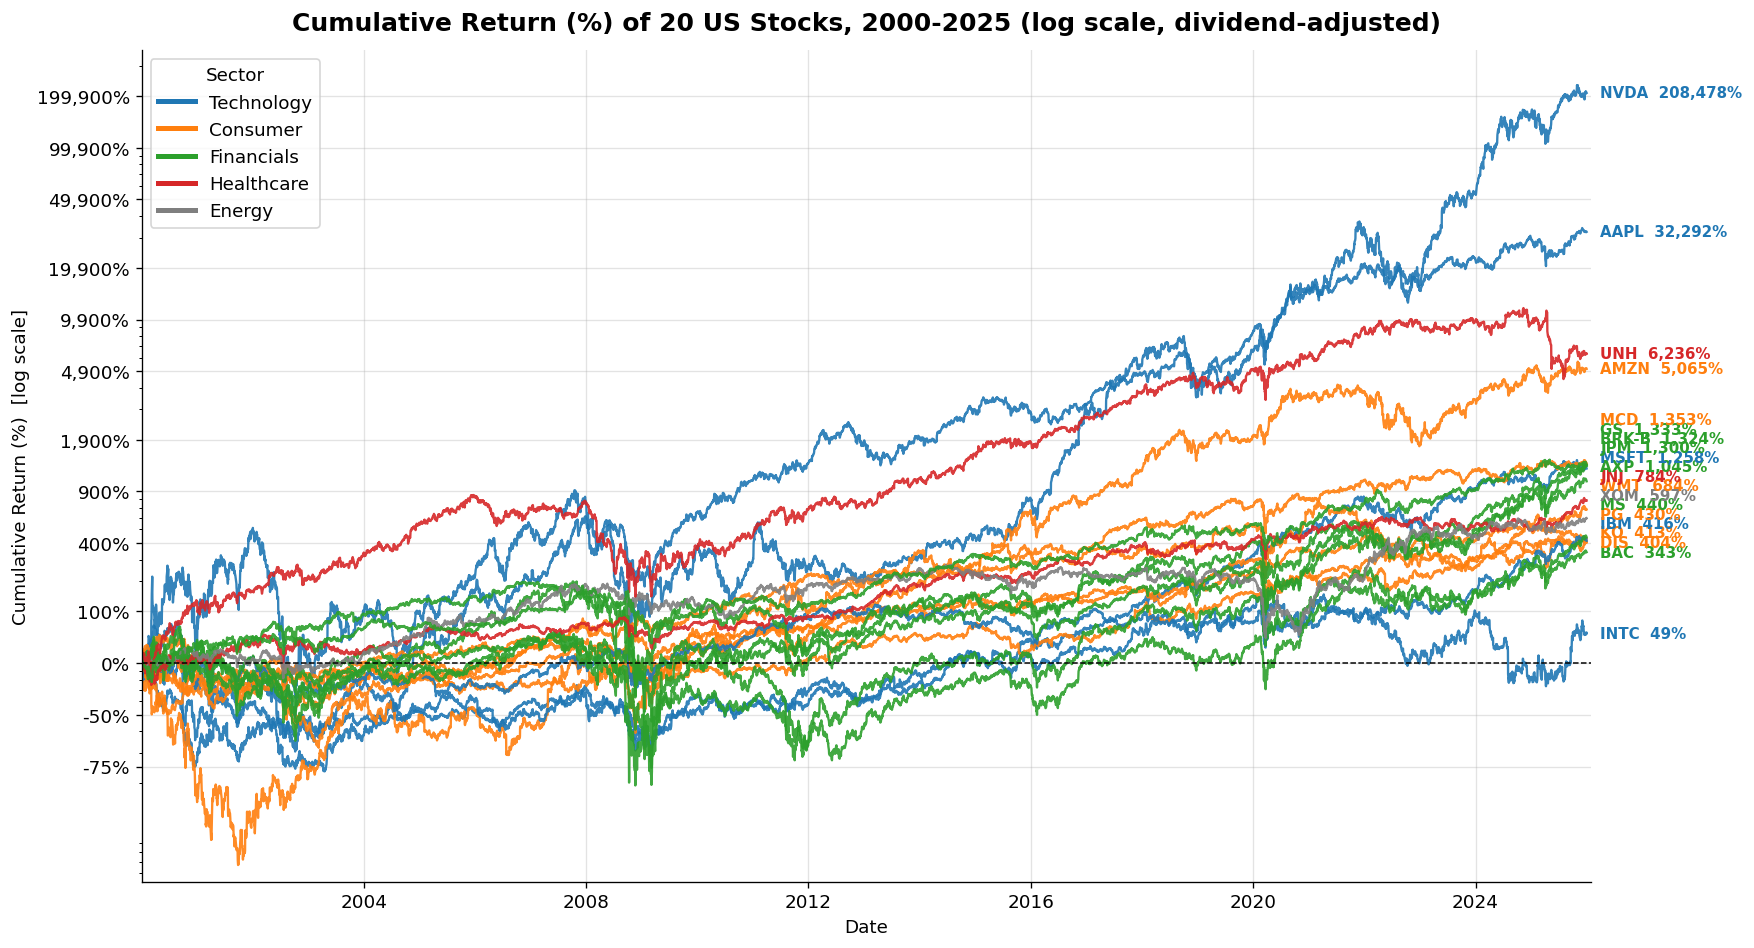

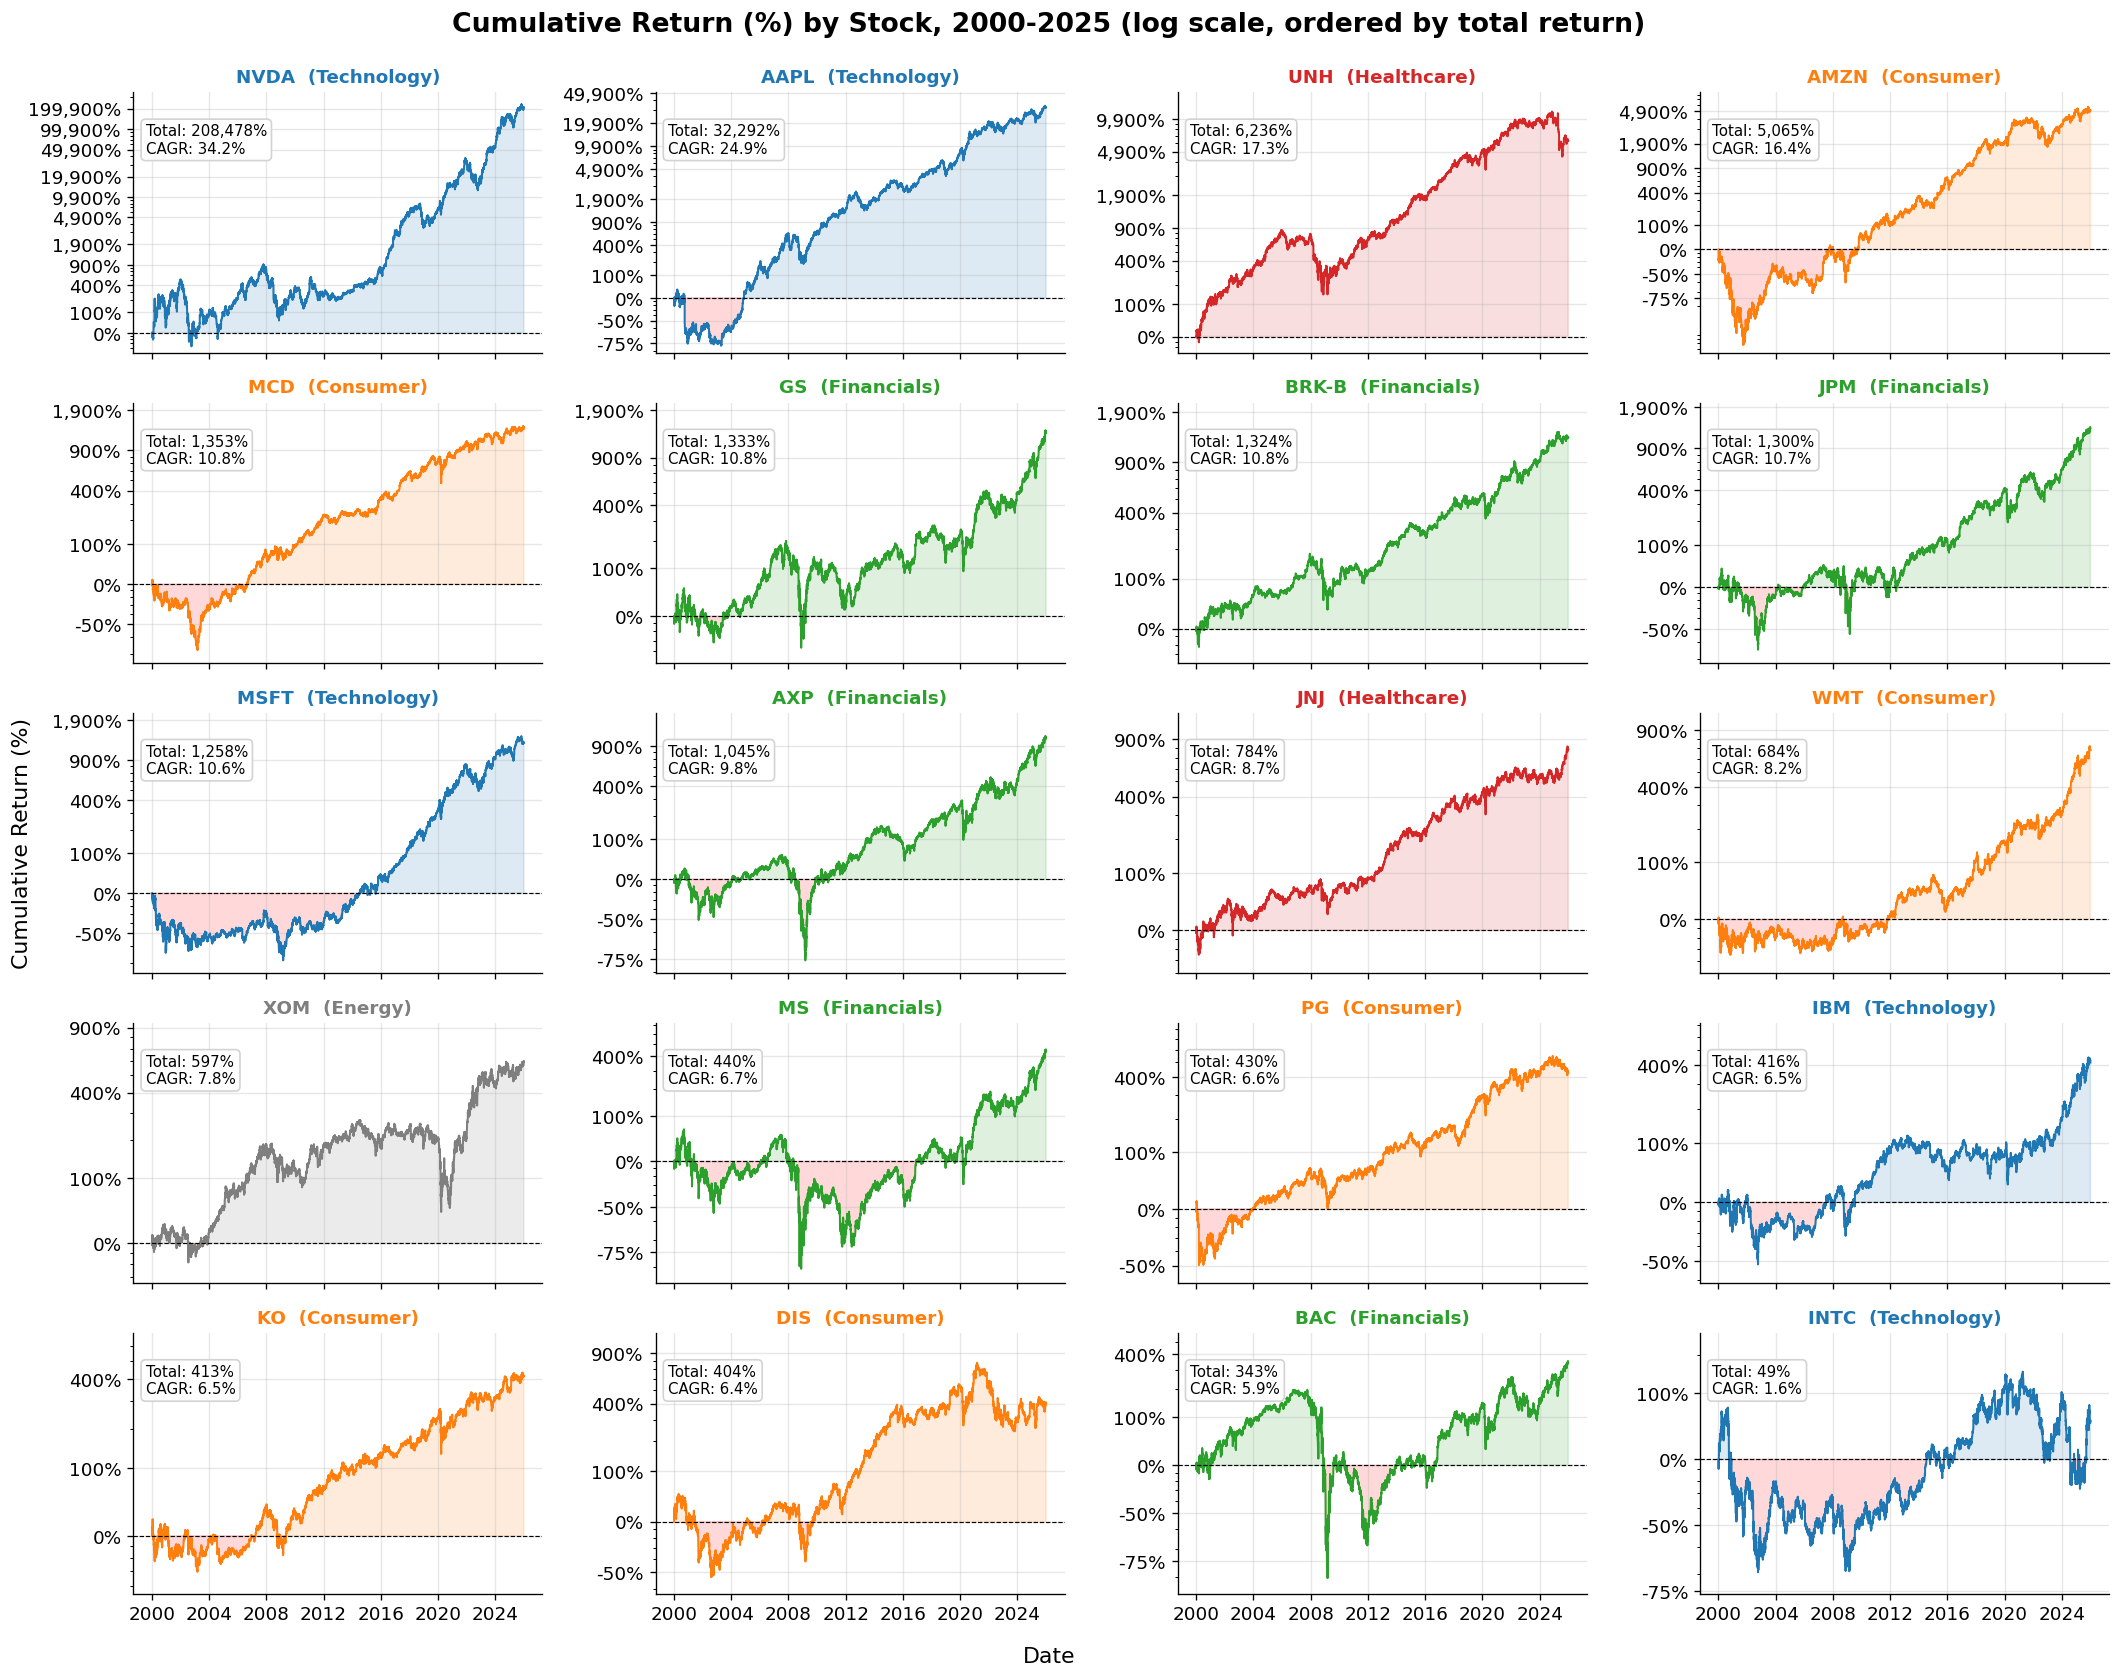

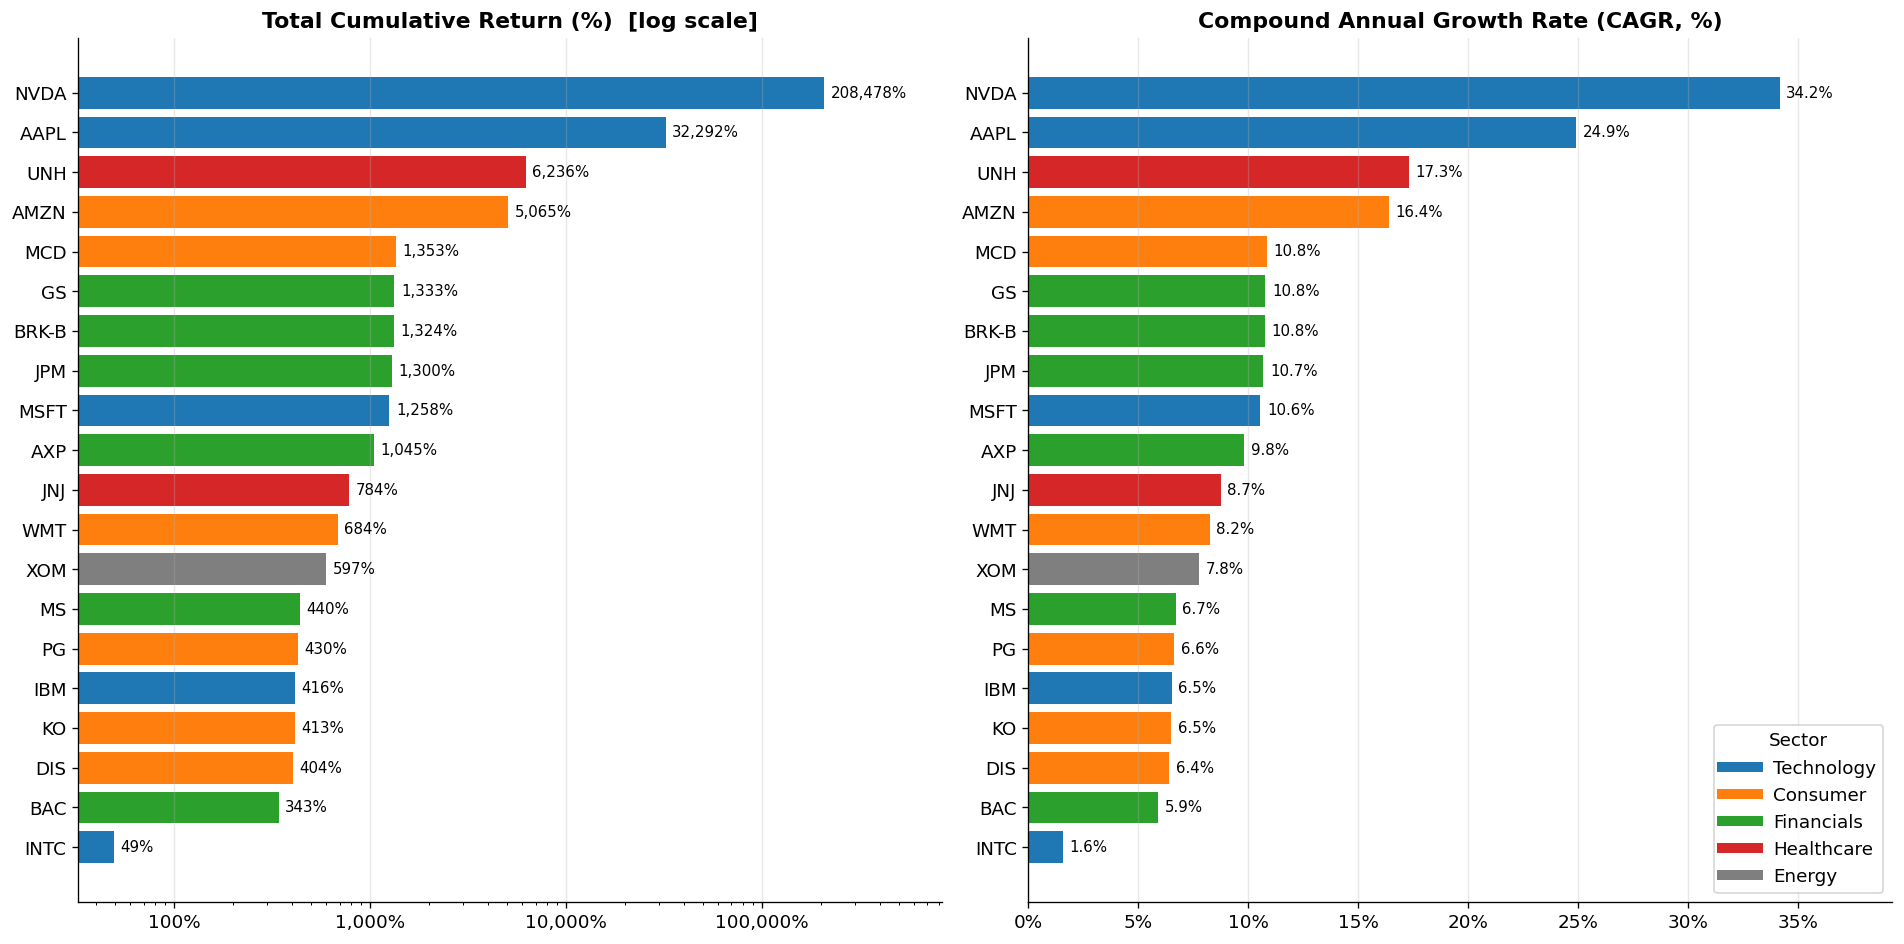

,Sector,Total Return (%),CAGR (%)
NVDA,Technology,208477.5,34.18
AAPL,Technology,32292.0,24.91
UNH,Healthcare,6236.1,17.31
AMZN,Consumer,5065.2,16.39
MCD,Consumer,1352.5,10.84
GS,Financials,1332.5,10.78
BRK-B,Financials,1323.9,10.76
JPM,Financials,1300.1,10.69
MSFT,Technology,1258.4,10.56
AXP,Financials,1044.5,9.83


In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# ----------------------------------------------------------------------
# Load data saved by cell 1
# ----------------------------------------------------------------------
adj_close = pd.read_csv("us_stock_data/adj_close_wide.csv", index_col="Date", parse_dates=True)

# Wealth index: value of $1 invested at each stock's first available price
wealth = adj_close / adj_close.apply(lambda s: s.dropna().iloc[0])
cum_ret = (wealth - 1) * 100                     # cumulative return in %
final_ret = cum_ret.ffill().iloc[-1].sort_values(ascending=False)
years = (adj_close.index[-1] - adj_close.index[0]).days / 365.25
cagr = (wealth.ffill().iloc[-1] ** (1 / years) - 1) * 100

# Sector colours (makes the chart easier to interpret)
sector = {
    "MSFT": "Technology", "AAPL": "Technology", "NVDA": "Technology",
    "INTC": "Technology", "IBM": "Technology",
    "AMZN": "Consumer", "WMT": "Consumer", "KO": "Consumer",
    "DIS": "Consumer", "PG": "Consumer", "MCD": "Consumer",
    "JPM": "Financials", "GS": "Financials", "MS": "Financials",
    "AXP": "Financials", "BAC": "Financials", "BRK-B": "Financials",
    "JNJ": "Healthcare", "UNH": "Healthcare",
    "XOM": "Energy",
}
sector_color = {"Technology": "#1f77b4", "Consumer": "#ff7f0e", "Financials": "#2ca02c",
                "Healthcare": "#d62728", "Energy": "#7f7f7f"}
col = {t: sector_color[sector[t]] for t in wealth.columns}

plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

# Y-axis: log scale on wealth index, tick labels shown as cumulative return (%)
def ret_formatter():
    return mtick.FuncFormatter(lambda w, _: f"{(w - 1) * 100:,.0f}%")

ticks = np.array([0.25, 0.5, 1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 2000])

# ======================================================================
# FIGURE 1: Cumulative return (log scale) with direct end-labels
# ======================================================================
fig, ax = plt.subplots(figsize=(16, 9), dpi=120)

for t in wealth.columns:
    ax.plot(wealth.index, wealth[t], color=col[t], lw=1.4, alpha=0.9)

ax.set_yscale("log")
ymin, ymax = wealth.min().min() * 0.8, wealth.max().max() * 1.6
ax.set_ylim(ymin, ymax)
ax.set_yticks(ticks[(ticks >= ymin) & (ticks <= ymax)])
ax.yaxis.set_major_formatter(ret_formatter())
ax.yaxis.set_minor_formatter(mtick.NullFormatter())
ax.axhline(1, color="black", lw=0.9, ls="--")          # break-even line
ax.grid(True, which="major", alpha=0.35)

# Direct labels at the right edge (spread out so they don't overlap)
last = wealth.ffill().iloc[-1].sort_values()
pos, min_gap, prev = {}, 0.055, None
for t, v in last.items():
    y = np.log10(v)
    y = y if prev is None or y - prev >= min_gap else prev + min_gap
    pos[t], prev = y, y
x_end = wealth.index[-1] + pd.Timedelta(days=90)
for t, y in pos.items():
    ax.annotate(f"{t}  {final_ret[t]:,.0f}%", xy=(x_end, 10 ** y), va="center",
                fontsize=9, color=col[t], fontweight="bold", annotation_clip=False)

ax.set_xlim(wealth.index[0], wealth.index[-1] + pd.Timedelta(days=30))
ax.set_title("Cumulative Return (%) of 20 US Stocks, 2000-2025 (log scale, dividend-adjusted)",
             fontsize=15, fontweight="bold", pad=12)
ax.set_xlabel("Date")
ax.set_ylabel("Cumulative Return (%)  [log scale]")

handles = [plt.Line2D([0], [0], color=c, lw=3, label=s) for s, c in sector_color.items()]
ax.legend(handles=handles, loc="upper left", title="Sector", frameon=True)
fig.subplots_adjust(right=0.88)
plt.savefig("cumulative_return_log.png", dpi=300, bbox_inches="tight")
plt.show()

# ======================================================================
# FIGURE 2: Small multiples (one panel per stock)
# ======================================================================
order = list(final_ret.index)
fig, axes = plt.subplots(5, 4, figsize=(18, 14), sharex=True, dpi=120)

for ax, t in zip(axes.flat, order):
    w = wealth[t].dropna()
    ax.plot(w.index, w, color=col[t], lw=1.2)
    ax.axhline(1, color="black", lw=0.7, ls="--")
    ax.fill_between(w.index, 1, w, where=(w >= 1), color=col[t], alpha=0.15)
    ax.fill_between(w.index, 1, w, where=(w < 1), color="red", alpha=0.15)
    ax.set_yscale("log")
    lo, hi = w.min() * 0.8, w.max() * 1.5
    ax.set_ylim(lo, hi)
    tk = ticks[(ticks >= lo) & (ticks <= hi)]
    ax.set_yticks(tk)
    ax.yaxis.set_major_formatter(ret_formatter())
    ax.yaxis.set_minor_formatter(mtick.NullFormatter())
    ax.set_title(f"{t}  ({sector[t]})", fontsize=11, fontweight="bold", color=col[t])
    ax.text(0.03, 0.88, f"Total: {final_ret[t]:,.0f}%\nCAGR: {cagr[t]:.1f}%",
            transform=ax.transAxes, fontsize=9, va="top",
            bbox=dict(boxstyle="round", fc="white", ec="lightgrey"))
    ax.grid(True, alpha=0.3)

fig.suptitle("Cumulative Return (%) by Stock, 2000-2025 (log scale, ordered by total return)",
             fontsize=16, fontweight="bold", y=0.995)
fig.supxlabel("Date")
fig.supylabel("Cumulative Return (%)")
plt.tight_layout()
plt.savefig("cumulative_return_small_multiples.png", dpi=300, bbox_inches="tight")
plt.show()

# ======================================================================
# FIGURE 3: Total return and CAGR ranking
# ======================================================================
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 8), dpi=120)

fr = final_ret.sort_values()
a1.barh(fr.index, fr.values, color=[col[t] for t in fr.index])
a1.set_xscale("log")
a1.set_title("Total Cumulative Return (%)  [log scale]", fontweight="bold")
a1.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:,.0f}%"))
for i, v in enumerate(fr.values):
    a1.text(v * 1.08, i, f"{v:,.0f}%", va="center", fontsize=9)
a1.set_xlim(right=fr.max() * 4)

cg = cagr.sort_values()
a2.barh(cg.index, cg.values, color=[col[t] for t in cg.index])
a2.set_title("Compound Annual Growth Rate (CAGR, %)", fontweight="bold")
a2.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
for i, v in enumerate(cg.values):
    a2.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=9)
a2.set_xlim(right=cg.max() * 1.15)

for a in (a1, a2):
    a.grid(True, axis="x", alpha=0.3)
handles = [plt.Line2D([0], [0], color=c, lw=6, label=s) for s, c in sector_color.items()]
a2.legend(handles=handles, loc="lower right", title="Sector")
plt.tight_layout()
plt.savefig("return_ranking.png", dpi=300, bbox_inches="tight")
plt.show()

# Summary table
summary = pd.DataFrame({"Sector": pd.Series(sector), "Total Return (%)": final_ret.round(1),
                        "CAGR (%)": cagr.round(2)}).loc[order]
summary

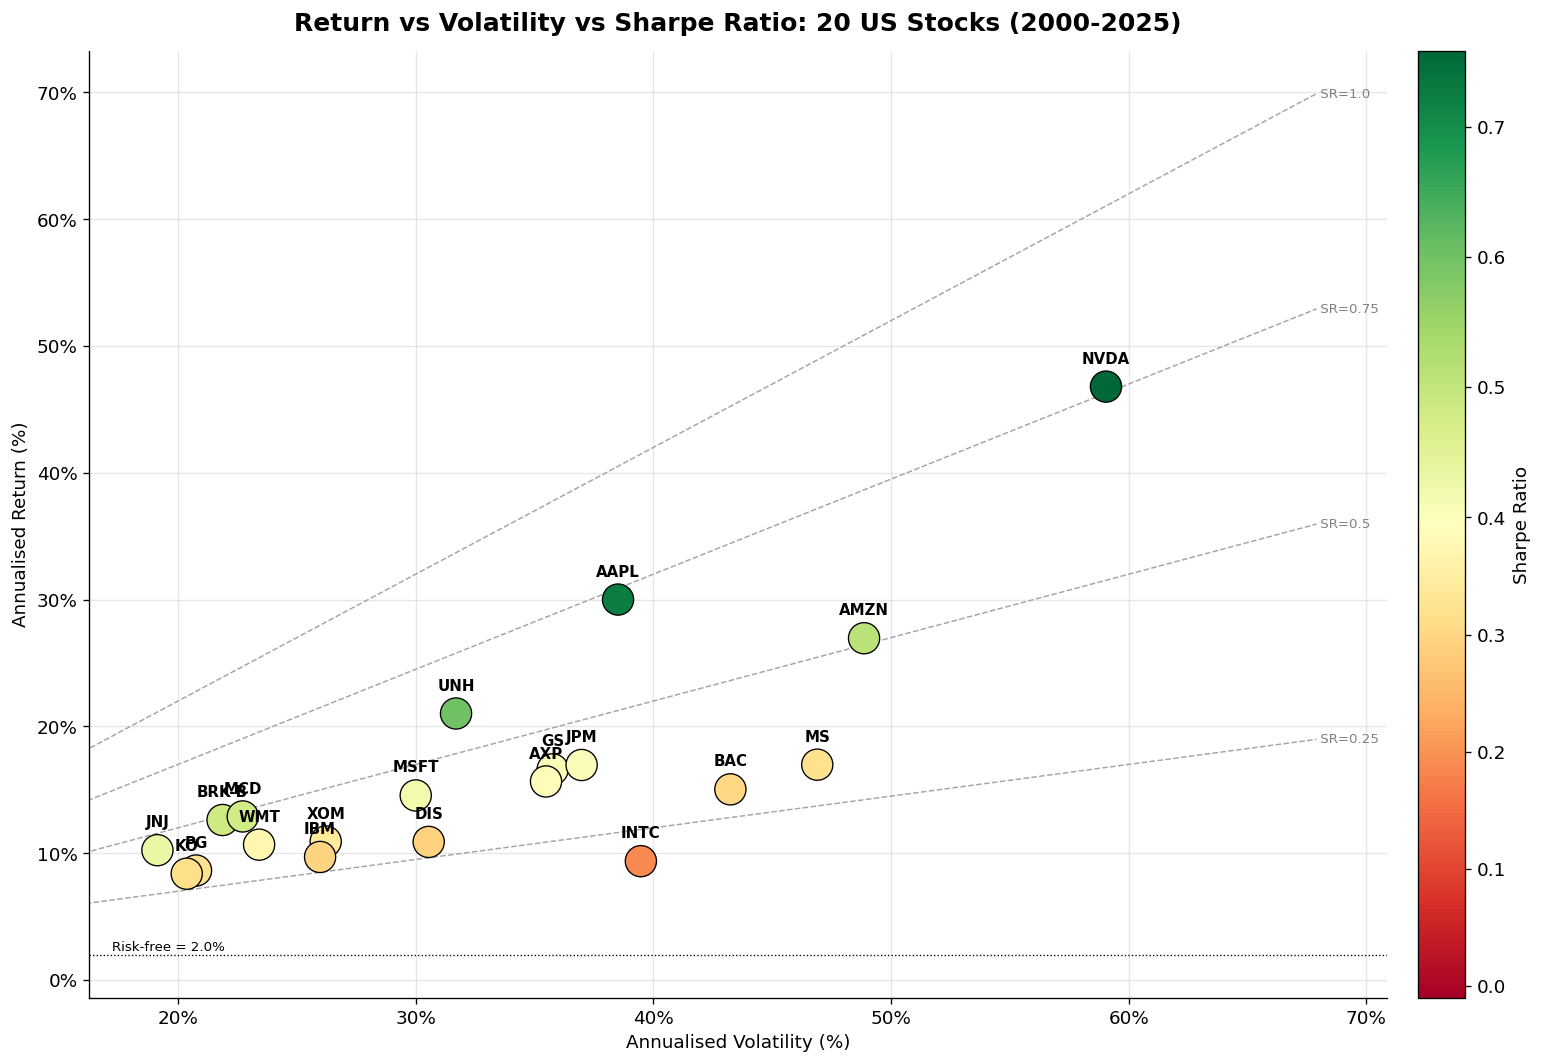

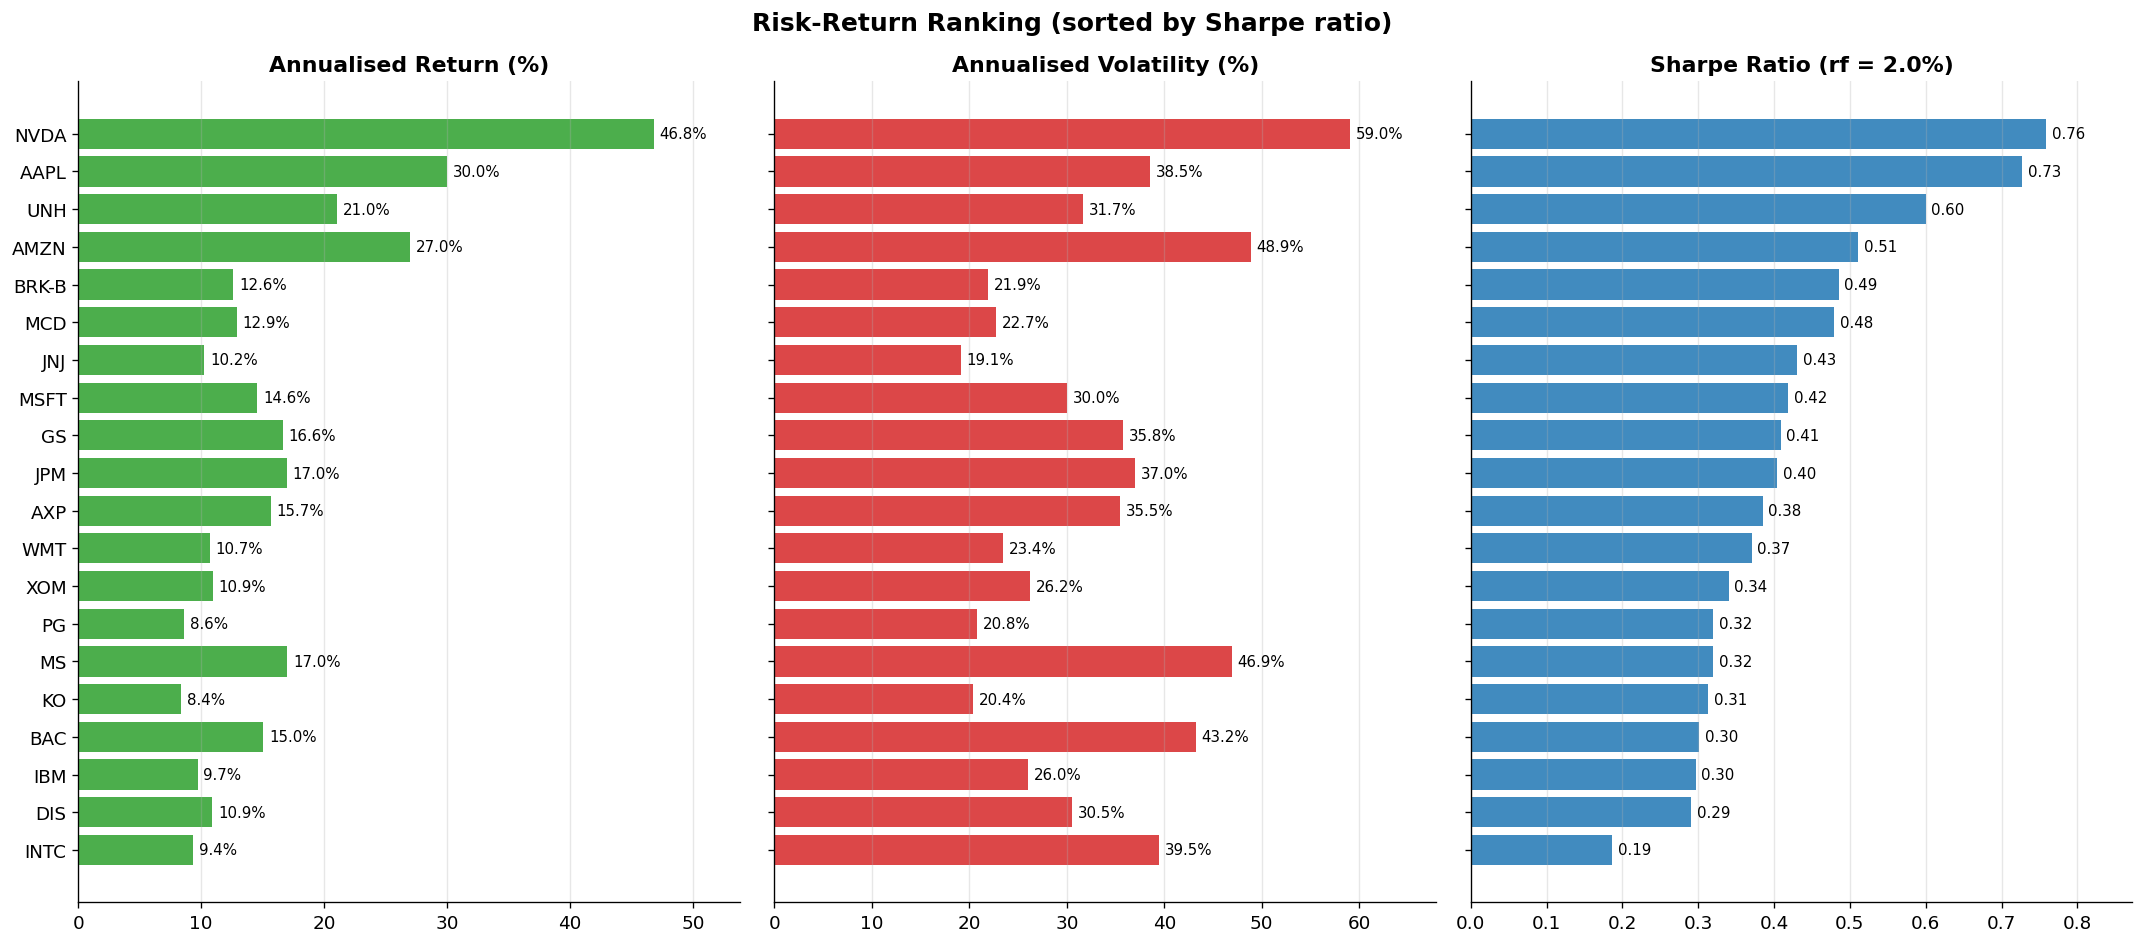

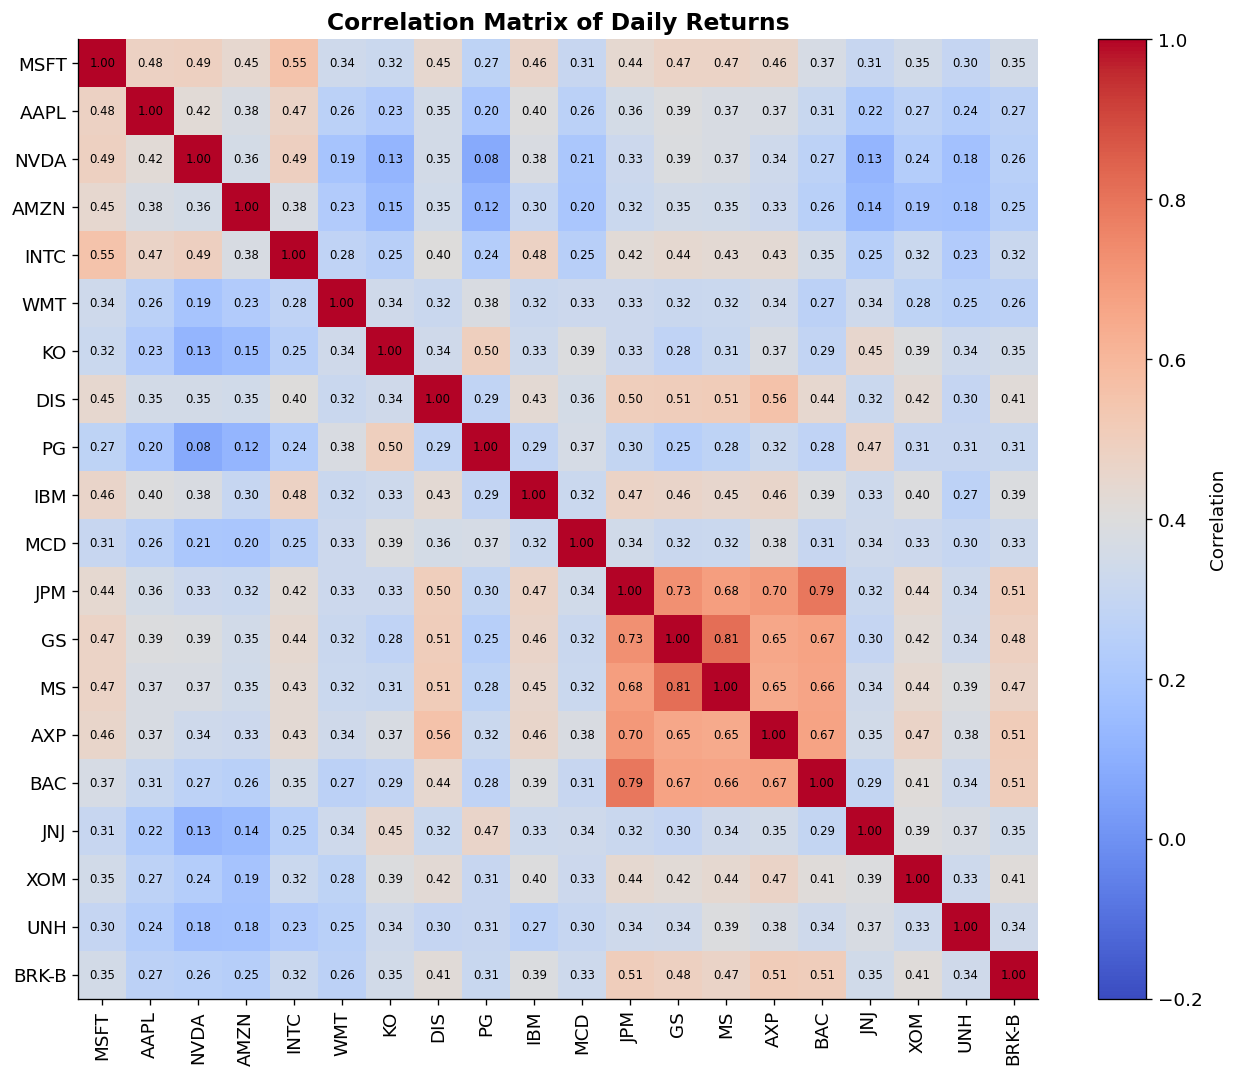

,Ann. Return (%),Ann. Volatility (%),Sharpe Ratio,CAGR (%)
NVDA,46.80,59.05,0.76,34.18
AAPL,30.00,38.52,0.73,24.91
UNH,21.02,31.70,0.60,17.31
AMZN,26.95,48.87,0.51,16.39
BRK-B,12.62,21.88,0.49,10.76
MCD,12.90,22.73,0.48,10.84
JNJ,10.24,19.14,0.43,8.75
MSFT,14.55,30.00,0.42,10.56
GS,16.61,35.76,0.41,10.78
JPM,16.96,36.98,0.40,10.69


In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import TwoSlopeNorm

# ----------------------------------------------------------------------
# Settings
# ----------------------------------------------------------------------
RF = 0.02              # annual risk-free rate (2%); change to suit your study
TRADING_DAYS = 252

# ----------------------------------------------------------------------
# Load data saved by cell 1
# ----------------------------------------------------------------------
adj_close = pd.read_csv("us_stock_data/adj_close_wide.csv", index_col="Date", parse_dates=True)

# Daily simple returns (no forward-filling, so each stock uses only its own trading history)
returns = adj_close.pct_change(fill_method=None)

# ----------------------------------------------------------------------
# Risk / return metrics
# ----------------------------------------------------------------------
ann_return = returns.mean() * TRADING_DAYS                    # annualised mean return
ann_vol = returns.std() * np.sqrt(TRADING_DAYS)               # annualised volatility
sharpe = (ann_return - RF) / ann_vol                          # Sharpe ratio

years = (adj_close.index[-1] - adj_close.index[0]).days / 365.25
first_price = adj_close.apply(lambda s: s.dropna().iloc[0])
cagr = ((adj_close.ffill().iloc[-1] / first_price) ** (1 / years) - 1)

metrics = pd.DataFrame({
    "Ann. Return (%)": ann_return * 100,
    "Ann. Volatility (%)": ann_vol * 100,
    "Sharpe Ratio": sharpe,
    "CAGR (%)": cagr * 100,
}).sort_values("Sharpe Ratio", ascending=False)

plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

# ======================================================================
# FIGURE 1: Return vs Volatility, coloured by Sharpe ratio
# ======================================================================
fig, ax = plt.subplots(figsize=(14, 9), dpi=120)

x = metrics["Ann. Volatility (%)"]
y = metrics["Ann. Return (%)"]
s = metrics["Sharpe Ratio"]

norm = TwoSlopeNorm(vmin=min(s.min(), -0.01), vcenter=s.median(), vmax=s.max())
sc = ax.scatter(x, y, c=s, cmap="RdYlGn", norm=norm, s=350,
                edgecolor="black", linewidth=0.8, zorder=3)

for t in metrics.index:
    ax.annotate(t, (x[t], y[t]), xytext=(0, 14), textcoords="offset points",
                ha="center", fontsize=9, fontweight="bold")

# Iso-Sharpe lines: return = RF + Sharpe * volatility
xs = np.linspace(0, x.max() * 1.15, 100)
for sh in [0.25, 0.5, 0.75, 1.0]:
    ax.plot(xs, (RF + sh * xs / 100) * 100, ls="--", lw=0.9, color="grey", alpha=0.7, zorder=1)
    ax.text(xs[-1], (RF + sh * xs[-1] / 100) * 100, f" SR={sh}", fontsize=8, color="grey", va="center")

ax.axhline(RF * 100, color="black", lw=0.8, ls=":")
ax.text(x.min() * 0.9, RF * 100 + 0.3, f"Risk-free = {RF*100:.1f}%", fontsize=8)

cbar = plt.colorbar(sc, ax=ax, pad=0.02)
cbar.set_label("Sharpe Ratio")

ax.set_xlim(x.min() * 0.85, x.max() * 1.2)
ax.set_xlabel("Annualised Volatility (%)")
ax.set_ylabel("Annualised Return (%)")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.grid(True, alpha=0.3)
ax.set_title("Return vs Volatility vs Sharpe Ratio: 20 US Stocks (2000-2025)",
             fontsize=15, fontweight="bold", pad=12)
plt.tight_layout()
plt.savefig("return_vs_volatility_sharpe.png", dpi=300, bbox_inches="tight")
plt.show()

# ======================================================================
# FIGURE 2: Ranking of return, volatility and Sharpe ratio
# ======================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 8), dpi=120, sharey=True)
order = metrics.sort_values("Sharpe Ratio").index

panels = [
    ("Ann. Return (%)", "Annualised Return (%)", "#2ca02c"),
    ("Ann. Volatility (%)", "Annualised Volatility (%)", "#d62728"),
    ("Sharpe Ratio", f"Sharpe Ratio (rf = {RF*100:.1f}%)", "#1f77b4"),
]
for a, (colname, title, c) in zip(axes, panels):
    vals = metrics.loc[order, colname]
    a.barh(order, vals, color=c, alpha=0.85)
    for i, v in enumerate(vals):
        a.text(v + vals.max() * 0.01, i, f"{v:.2f}" if colname == "Sharpe Ratio" else f"{v:.1f}%",
               va="center", fontsize=9)
    a.set_title(title, fontweight="bold")
    a.grid(True, axis="x", alpha=0.3)
    a.set_xlim(right=vals.max() * 1.15)

plt.suptitle("Risk-Return Ranking (sorted by Sharpe ratio)", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.savefig("risk_return_ranking.png", dpi=300, bbox_inches="tight")
plt.show()

# ======================================================================
# FIGURE 3: Correlation of daily returns (useful for portfolio work)
# ======================================================================
corr = returns.corr()
fig, ax = plt.subplots(figsize=(11, 9), dpi=120)
im = ax.imshow(corr, cmap="coolwarm", vmin=-0.2, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, ax=ax, label="Correlation")
ax.set_title("Correlation Matrix of Daily Returns", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("correlation_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

# ----------------------------------------------------------------------
# Summary table
# ----------------------------------------------------------------------
metrics.round(2)

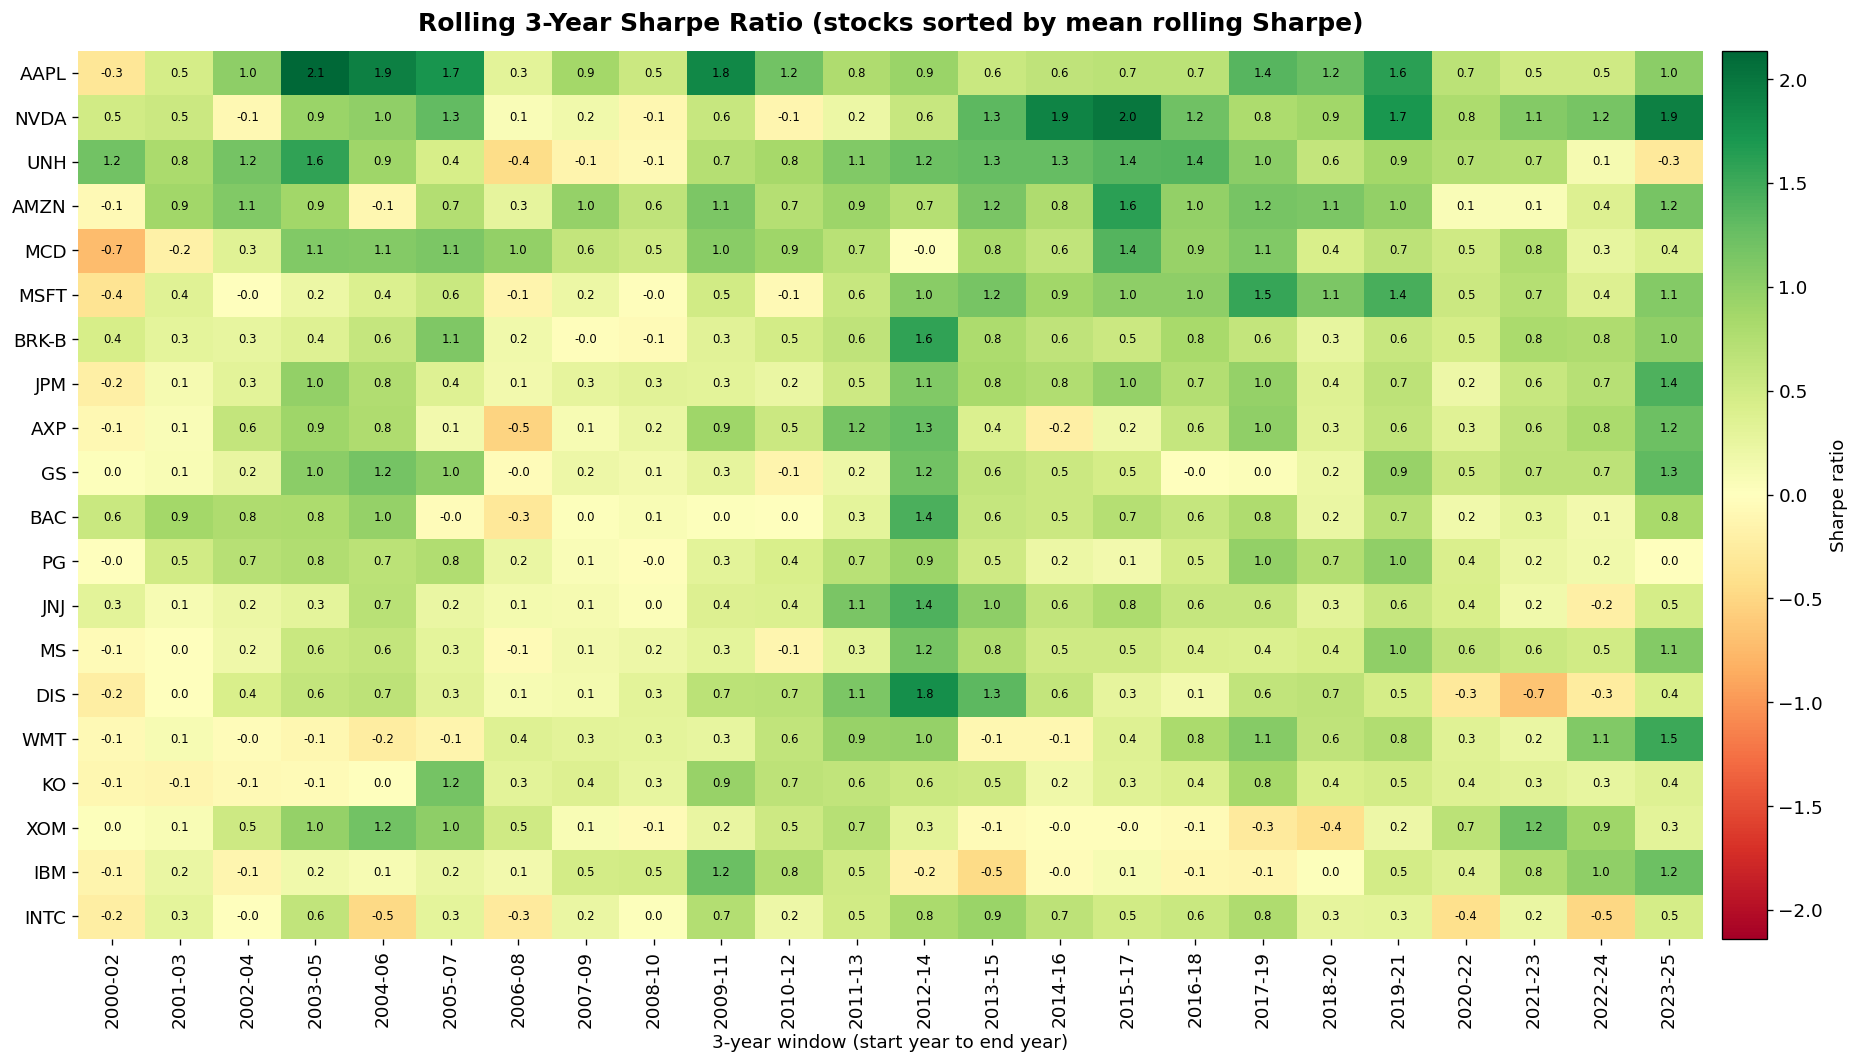

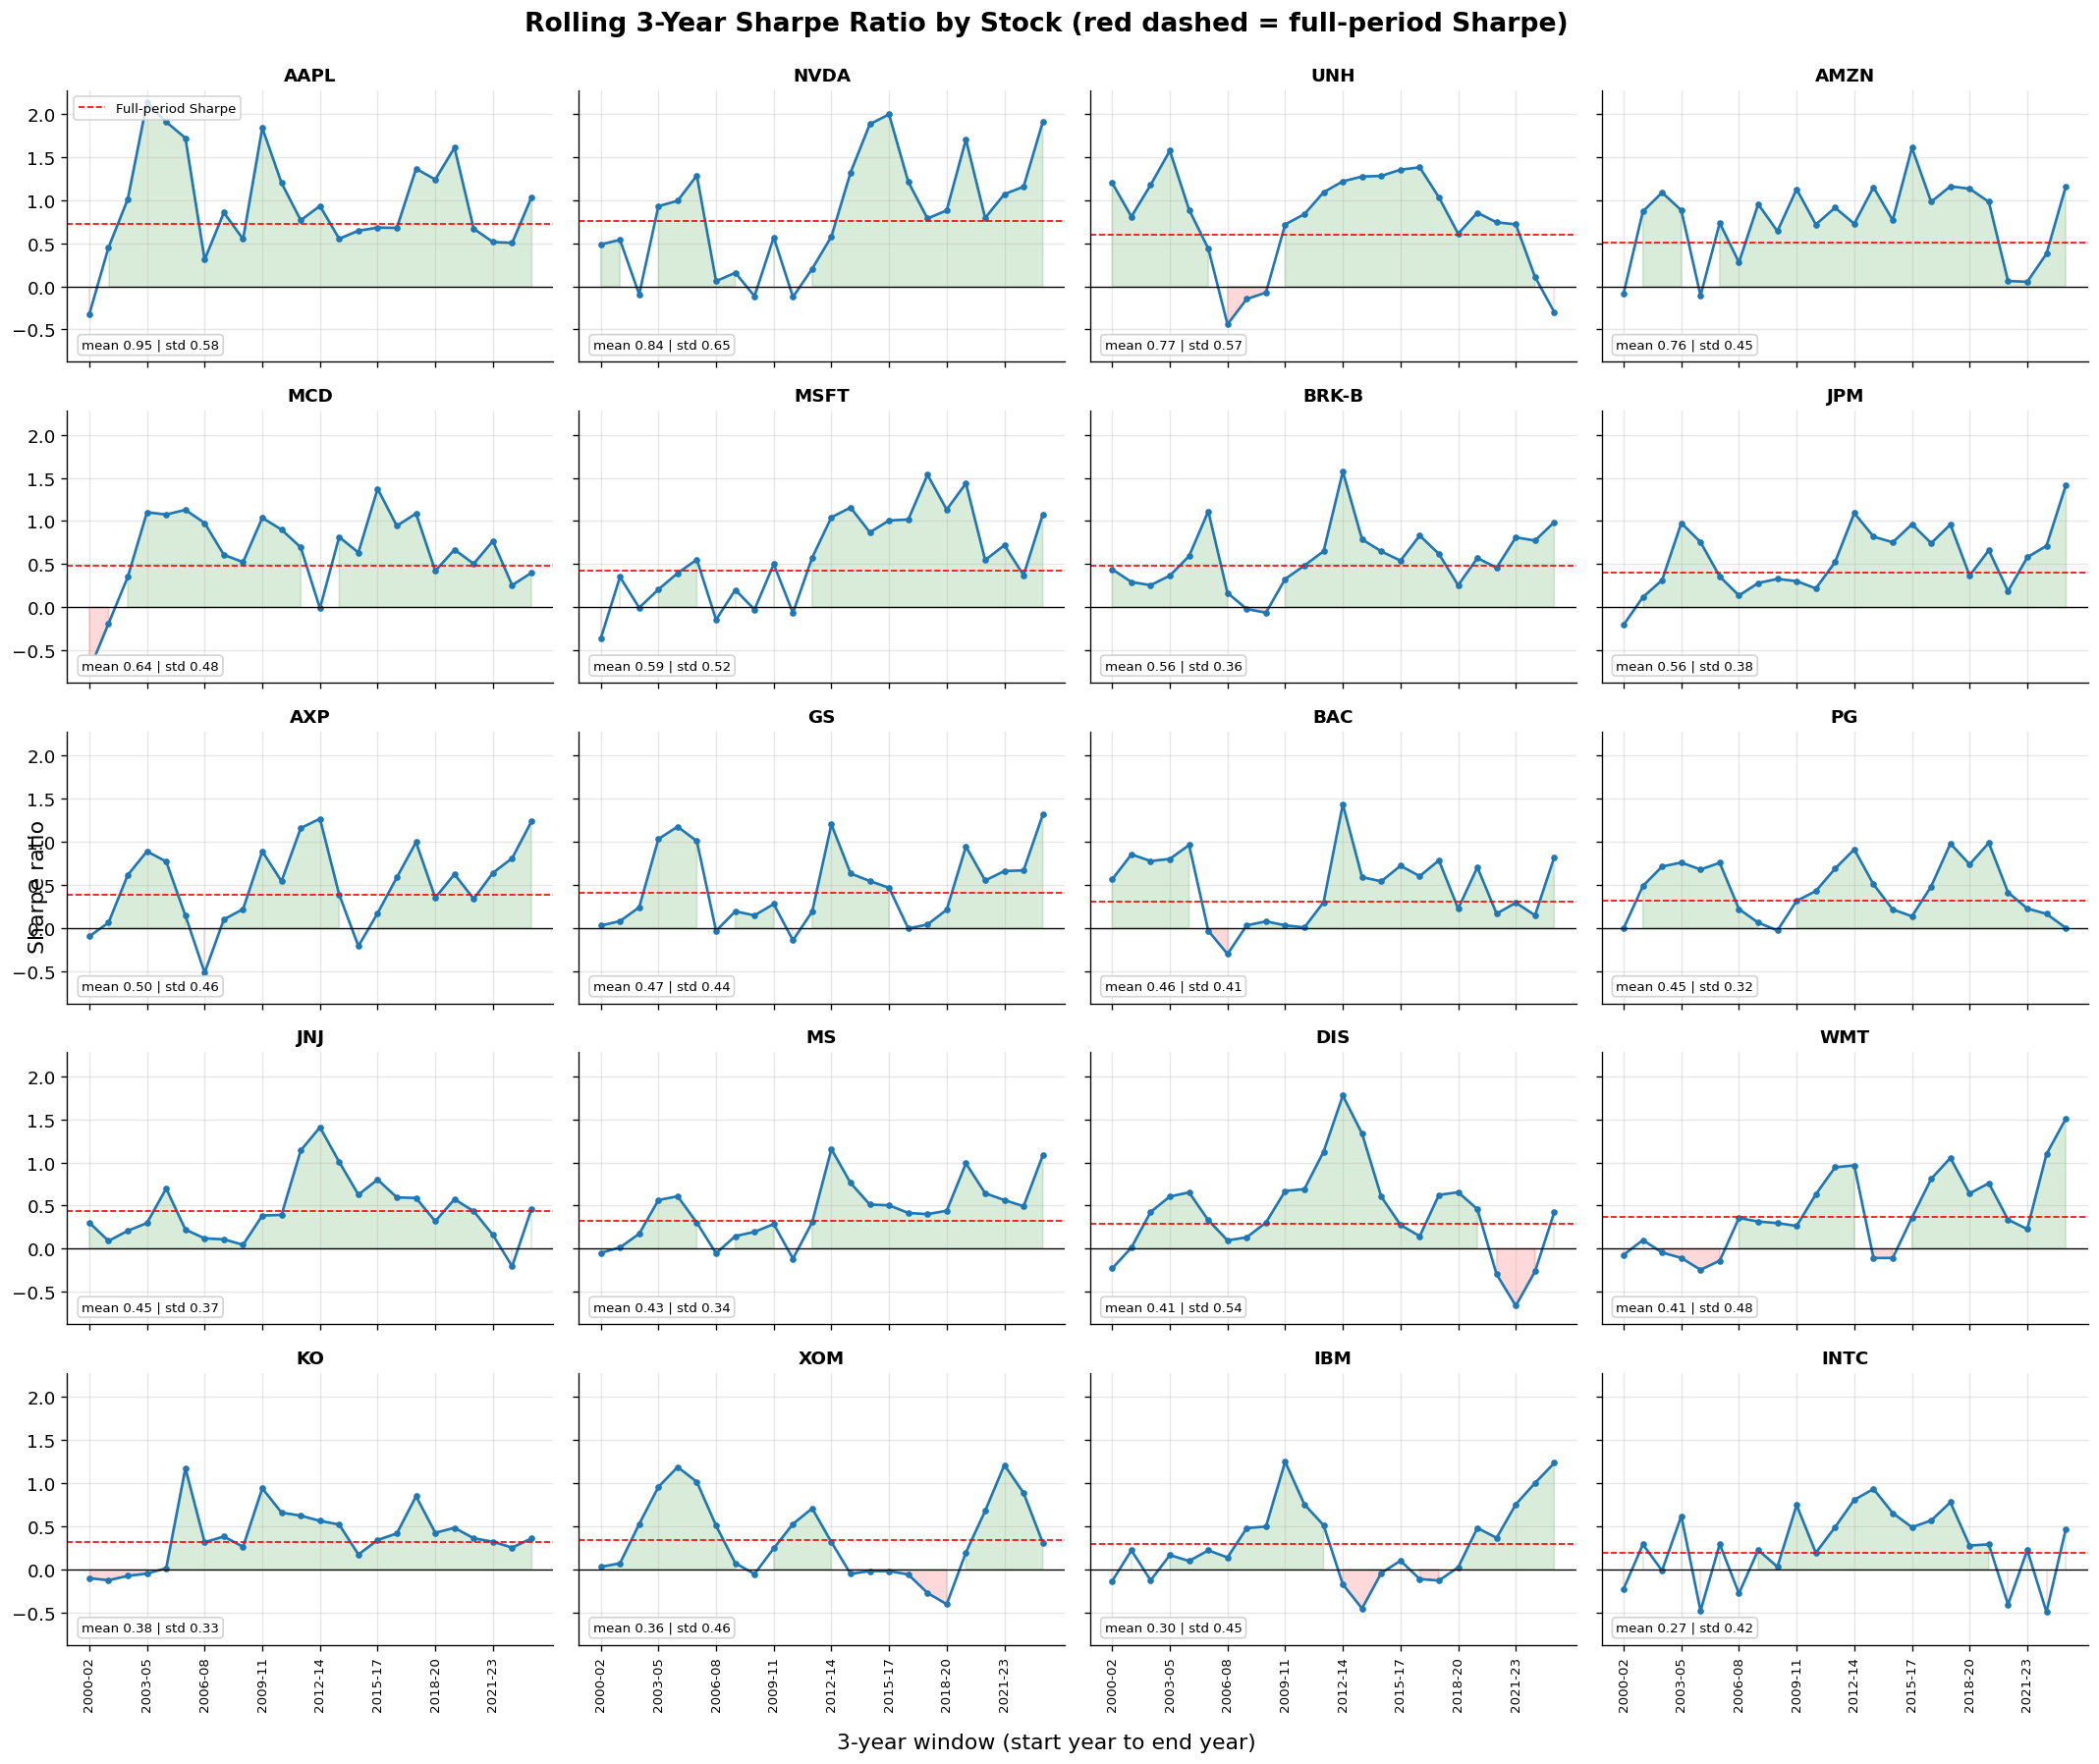

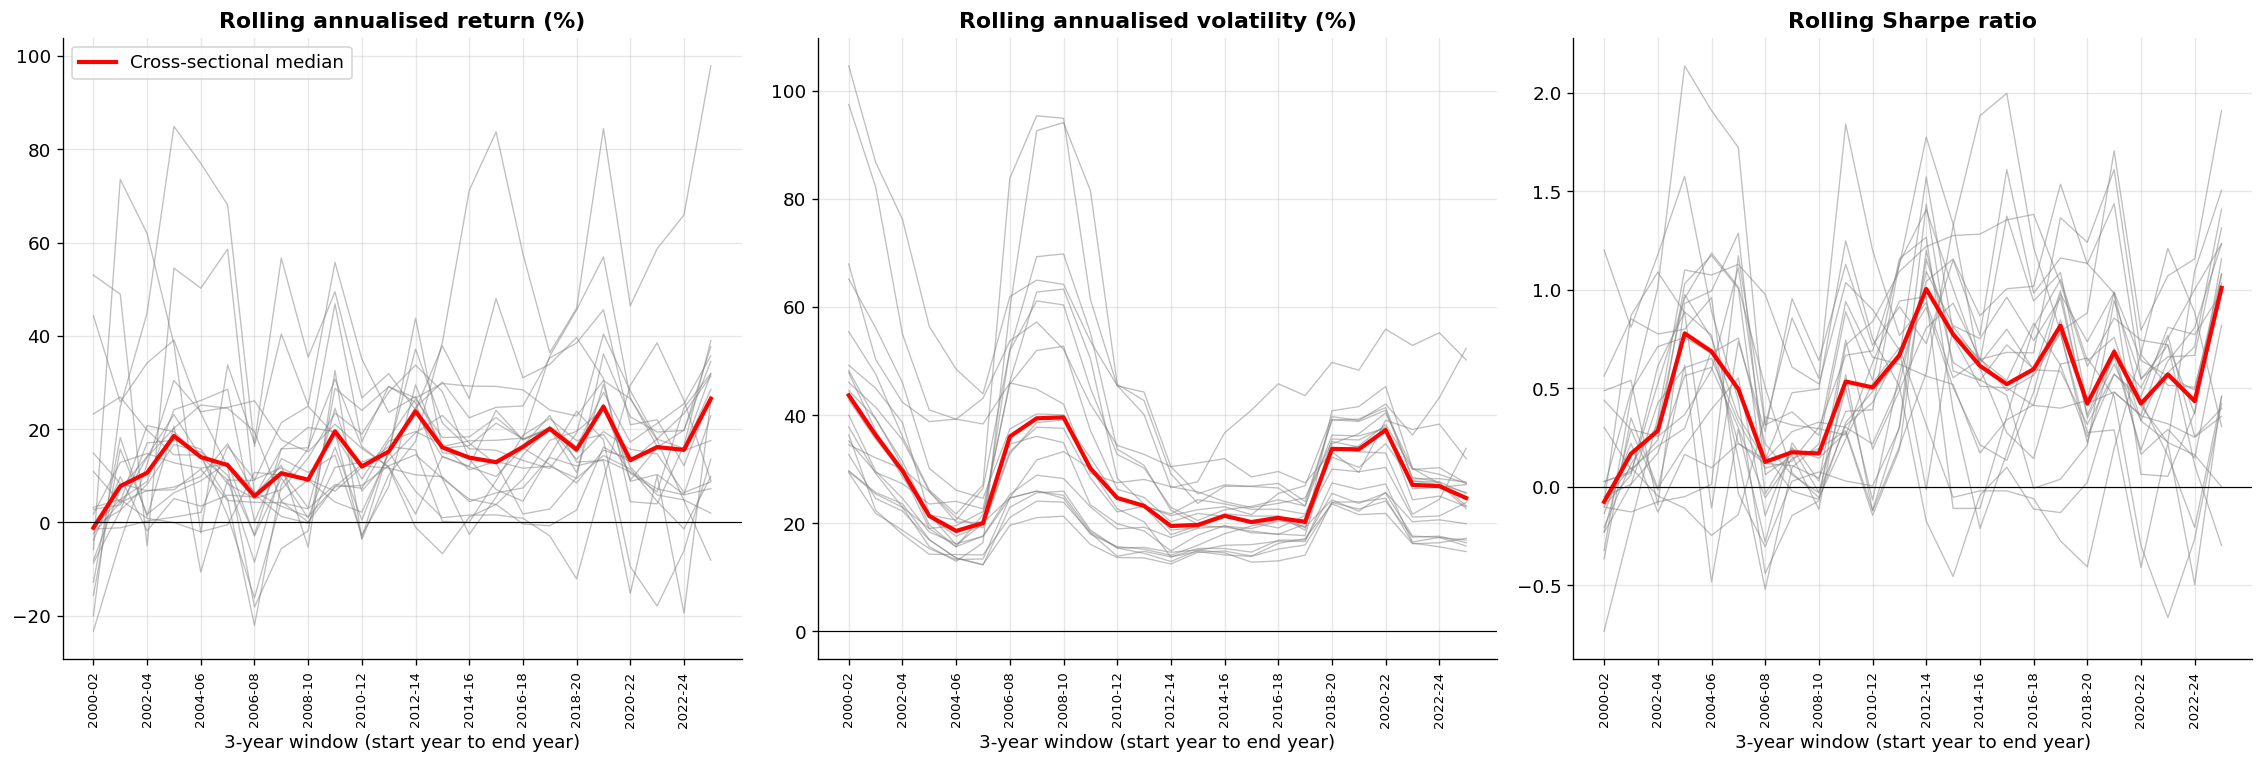

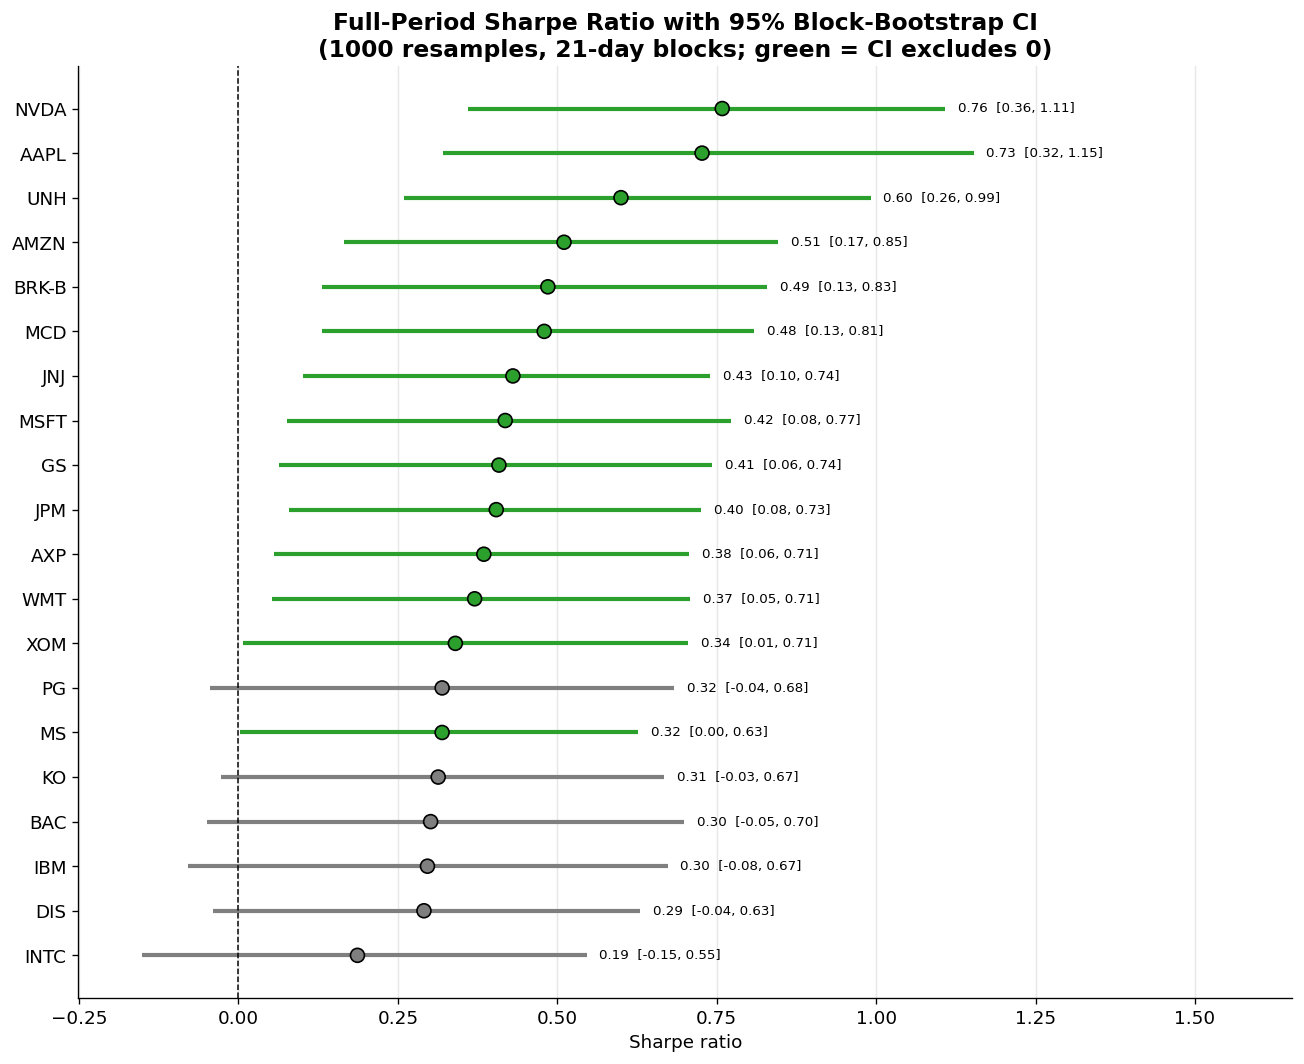

,Mean Rolling Sharpe,Std Rolling Sharpe,Min,Max,% Windows Sharpe > 0,Sharpe,CI Low (2.5%),CI High (97.5%),Significant (CI > 0)
AAPL,0.95,0.58,-0.32,2.14,95.83,0.73,0.32,1.15,True
NVDA,0.84,0.65,-0.12,2.00,87.50,0.76,0.36,1.11,True
UNH,0.77,0.57,-0.44,1.58,83.33,0.60,0.26,0.99,True
AMZN,0.76,0.45,-0.11,1.61,91.67,0.51,0.17,0.85,True
MCD,0.64,0.48,-0.73,1.37,87.50,0.48,0.13,0.81,True
MSFT,0.59,0.52,-0.37,1.54,79.17,0.42,0.08,0.77,True
BRK-B,0.56,0.36,-0.06,1.57,91.67,0.49,0.13,0.83,True
JPM,0.56,0.38,-0.21,1.41,95.83,0.40,0.08,0.73,True
AXP,0.50,0.46,-0.52,1.27,87.50,0.38,0.06,0.71,True
GS,0.47,0.44,-0.14,1.31,87.50,0.41,0.06,0.74,True


In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

# ----------------------------------------------------------------------
# Settings
# ----------------------------------------------------------------------
RF = 0.02               # annual risk-free rate (keep the same as cell 3)
TD = 252                # trading days per year
WINDOW_YEARS = 3        # rolling window length
N_BOOT = 1000           # bootstrap resamples
BLOCK = 21              # block length (~1 trading month) to preserve volatility clustering
SEED = 42

# ----------------------------------------------------------------------
# Load data saved by cell 1
# ----------------------------------------------------------------------
adj_close = pd.read_csv("us_stock_data/adj_close_wide.csv", index_col="Date", parse_dates=True)
returns = adj_close.pct_change(fill_method=None)

def sharpe_fn(r):
    return (r.mean() * TD - RF) / (r.std() * np.sqrt(TD))

def span_label(end_year):
    """Label a window by its full span, e.g. end year 2002 -> '2000-02'."""
    start_year = end_year - WINDOW_YEARS + 1
    return f"{start_year}-{str(end_year)[-2:]}"

plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

# ======================================================================
# PART 1: Rolling 3-year windows, stepped yearly (window ends at each year-end)
# ======================================================================
end_years = range(returns.index[0].year + WINDOW_YEARS - 1, returns.index[-1].year + 1)
roll_sharpe, roll_ret, roll_vol = {}, {}, {}

for y in end_years:
    end = returns.index[returns.index.year == y].max()
    start = end - pd.DateOffset(years=WINDOW_YEARS)
    w = returns.loc[(returns.index > start) & (returns.index <= end)]
    enough = w.count() >= 0.8 * TD * WINDOW_YEARS          # need at least 80% of the window
    roll_ret[y] = pd.Series({t: w[t].mean() * TD if enough[t] else np.nan for t in w.columns})
    roll_vol[y] = pd.Series({t: w[t].std() * np.sqrt(TD) if enough[t] else np.nan for t in w.columns})
    roll_sharpe[y] = pd.Series({t: sharpe_fn(w[t].dropna()) if enough[t] else np.nan for t in w.columns})

roll_sharpe = pd.DataFrame(roll_sharpe)     # stocks x window-end-year
roll_ret = pd.DataFrame(roll_ret) * 100
roll_vol = pd.DataFrame(roll_vol) * 100

order = roll_sharpe.mean(axis=1).sort_values(ascending=False).index
roll_sharpe = roll_sharpe.loc[order]

# Window labels (full span) and x positions
win_labels = [span_label(y) for y in roll_sharpe.columns]
pos = np.arange(len(win_labels))

# ---------------- Figure 1: heatmap of rolling Sharpe ----------------
fig, ax = plt.subplots(figsize=(17, 9), dpi=120)
vmax = np.nanmax(np.abs(roll_sharpe.values))
im = ax.imshow(roll_sharpe.values, aspect="auto", cmap="RdYlGn",
               norm=TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax))
ax.set_xticks(pos)
ax.set_xticklabels(win_labels, rotation=90)
ax.set_yticks(range(len(roll_sharpe)))
ax.set_yticklabels(roll_sharpe.index)
for i in range(roll_sharpe.shape[0]):
    for j in range(roll_sharpe.shape[1]):
        v = roll_sharpe.iat[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, ax=ax, pad=0.01, label="Sharpe ratio")
ax.set_xlabel(f"{WINDOW_YEARS}-year window (start year to end year)")
ax.set_title(f"Rolling {WINDOW_YEARS}-Year Sharpe Ratio (stocks sorted by mean rolling Sharpe)",
             fontsize=15, fontweight="bold", pad=12)
for s in ax.spines.values():
    s.set_visible(False)
plt.tight_layout()
plt.savefig("rolling_sharpe_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

# ---------------- Figure 2: rolling Sharpe small multiples ----------------
full_sharpe = returns.apply(lambda s: sharpe_fn(s.dropna()))
fig, axes = plt.subplots(5, 4, figsize=(18, 15), sharex=True, sharey=True, dpi=120)
for ax, t in zip(axes.flat, order):
    s = roll_sharpe.loc[t].values
    ax.plot(pos, s, color="#1f77b4", lw=1.6, marker="o", ms=3)
    ax.axhline(0, color="black", lw=0.8)
    ax.axhline(full_sharpe[t], color="red", ls="--", lw=1, label="Full-period Sharpe")
    ax.fill_between(pos, 0, s, where=(s >= 0), color="green", alpha=0.15)
    ax.fill_between(pos, 0, s, where=(s < 0), color="red", alpha=0.15)
    ax.set_title(t, fontsize=11, fontweight="bold")
    ax.text(0.03, 0.05, f"mean {np.nanmean(s):.2f} | std {np.nanstd(s, ddof=1):.2f}",
            transform=ax.transAxes, fontsize=8,
            bbox=dict(boxstyle="round", fc="white", ec="lightgrey"))
    ax.set_xticks(pos[::3])
    ax.set_xticklabels(win_labels[::3], rotation=90, fontsize=8)
    ax.grid(True, alpha=0.3)
axes.flat[0].legend(fontsize=8, loc="upper left")
fig.suptitle(f"Rolling {WINDOW_YEARS}-Year Sharpe Ratio by Stock (red dashed = full-period Sharpe)",
             fontsize=16, fontweight="bold", y=0.995)
fig.supxlabel(f"{WINDOW_YEARS}-year window (start year to end year)")
fig.supylabel("Sharpe ratio")
plt.tight_layout()
plt.savefig("rolling_sharpe_small_multiples.png", dpi=300, bbox_inches="tight")
plt.show()

# ---------------- Figure 3: stability of return / volatility / Sharpe over time ----------------
fig, axes = plt.subplots(1, 3, figsize=(19, 6.5), dpi=120)
for a, (df, title) in zip(axes, [(roll_ret, "Rolling annualised return (%)"),
                                 (roll_vol, "Rolling annualised volatility (%)"),
                                 (roll_sharpe, "Rolling Sharpe ratio")]):
    for t in df.index:
        a.plot(pos, df.loc[t].values, color="grey", lw=0.8, alpha=0.5)
    a.plot(pos, df.median().values, color="red", lw=2.5, label="Cross-sectional median")
    a.axhline(0, color="black", lw=0.7)
    a.set_title(title, fontweight="bold")
    a.set_xticks(pos[::2])
    a.set_xticklabels(win_labels[::2], rotation=90, fontsize=8)
    a.set_xlabel(f"{WINDOW_YEARS}-year window (start year to end year)")
    a.grid(True, alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.savefig("rolling_ret_vol_sharpe.png", dpi=300, bbox_inches="tight")
plt.show()

# ======================================================================
# PART 2: Block-bootstrap confidence intervals for the full-period Sharpe ratio
# ======================================================================
rng = np.random.default_rng(SEED)

def block_bootstrap_sharpe(r, n_boot, block, rng):
    """Circular block bootstrap of daily returns; returns the distribution of Sharpe ratios."""
    r = r.dropna().values
    n = len(r)
    n_blocks = int(np.ceil(n / block))
    starts = rng.integers(0, n, size=(n_boot, n_blocks))
    idx = ((starts[:, :, None] + np.arange(block)).reshape(n_boot, -1)[:, :n]) % n
    samp = r[idx]
    return (samp.mean(axis=1) * TD - RF) / (samp.std(axis=1, ddof=1) * np.sqrt(TD))

boot_rows = {}
for t in returns.columns:
    dist = block_bootstrap_sharpe(returns[t], N_BOOT, BLOCK, rng)
    boot_rows[t] = {"Sharpe": full_sharpe[t],
                    "CI Low (2.5%)": np.percentile(dist, 2.5),
                    "CI High (97.5%)": np.percentile(dist, 97.5)}
boot = pd.DataFrame(boot_rows).T.sort_values("Sharpe")
boot["Significant (CI > 0)"] = boot["CI Low (2.5%)"] > 0

# ---------------- Figure 4: forest plot ----------------
fig, ax = plt.subplots(figsize=(11, 9), dpi=120)
y = np.arange(len(boot))
colors = np.where(boot["Significant (CI > 0)"], "#2ca02c", "#7f7f7f")
ax.hlines(y, boot["CI Low (2.5%)"], boot["CI High (97.5%)"], color=colors, lw=2.5)
ax.scatter(boot["Sharpe"], y, color=colors, s=70, zorder=3, edgecolor="black")
ax.axvline(0, color="black", lw=0.9, ls="--")
ax.set_yticks(y)
ax.set_yticklabels(boot.index)
for yi, (lo, hi, sh) in enumerate(zip(boot["CI Low (2.5%)"], boot["CI High (97.5%)"], boot["Sharpe"])):
    ax.text(hi + 0.02, yi, f"{sh:.2f}  [{lo:.2f}, {hi:.2f}]", va="center", fontsize=8)
ax.set_xlim(boot["CI Low (2.5%)"].min() - 0.1, boot["CI High (97.5%)"].max() + 0.5)
ax.set_xlabel("Sharpe ratio")
ax.set_title(f"Full-Period Sharpe Ratio with 95% Block-Bootstrap CI\n"
             f"({N_BOOT} resamples, {BLOCK}-day blocks; green = CI excludes 0)",
             fontsize=14, fontweight="bold")
ax.grid(True, axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("sharpe_bootstrap_ci.png", dpi=300, bbox_inches="tight")
plt.show()

# ======================================================================
# Summary tables
# ======================================================================
stability = pd.DataFrame({
    "Mean Rolling Sharpe": roll_sharpe.mean(axis=1),
    "Std Rolling Sharpe": roll_sharpe.std(axis=1),
    "Min": roll_sharpe.min(axis=1),
    "Max": roll_sharpe.max(axis=1),
    "% Windows Sharpe > 0": (roll_sharpe > 0).sum(axis=1) / roll_sharpe.count(axis=1) * 100,
})
summary = stability.join(boot).sort_values("Mean Rolling Sharpe", ascending=False).round(2)
summary

20 stocks | 2000-01-04 to 2025-12-31 | 6538 daily observations


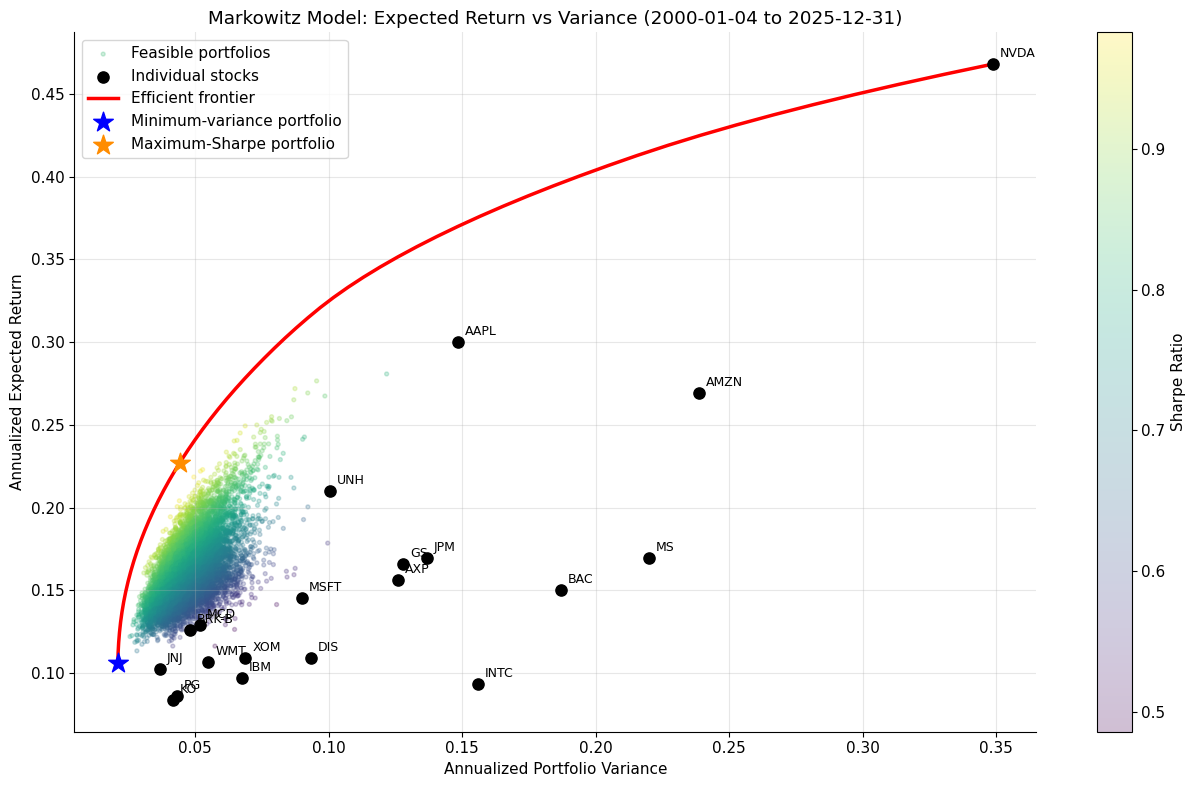

Individual stock statistics:


,Expected Return (%),Variance,Volatility (%)
NVDA,46.7991,0.3486,59.0466
AAPL,30.0030,0.1483,38.5158
AMZN,26.9526,0.2388,48.8677
UNH,21.0171,0.1005,31.7003
MS,16.9816,0.2199,46.8986
JPM,16.9556,0.1368,36.9836
GS,16.6119,0.1279,35.7646
AXP,15.6572,0.1259,35.4864
BAC,15.0344,0.1870,43.2429
MSFT,14.5550,0.0900,30.0046


Optimized portfolio statistics:


,Portfolio,Expected Return (%),Variance,Volatility (%),Sharpe Ratio
0,Minimum variance,10.6308,0.0210,14.4868,0.7338
1,Maximum Sharpe,22.7163,0.0442,21.0181,1.0808


Optimized portfolio weights (only stocks with weight > 0.01%):


,Minimum-variance weight (%),Maximum-Sharpe weight (%)
UNH,0.00,19.79
AAPL,0.07,17.79
JNJ,23.93,15.72
NVDA,0.00,15.20
MCD,12.18,13.47
BRK-B,16.98,9.70
AMZN,0.51,4.19
WMT,12.50,2.36
PG,13.05,1.78
KO,14.20,0.00


In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# ----------------------------------------------------------------------
# Settings
# ----------------------------------------------------------------------
ANALYSIS_START = "2000-01-01"   # change to "2025-01-01" to reproduce your one-year version
ANALYSIS_END   = "2026-01-01"
TD = 252
N_RANDOM = 10000
N_FRONTIER = 60
RF = 0.0                        # risk-free rate for max-Sharpe (0 to match your original code)

# ----------------------------------------------------------------------
# Load data saved by cell 1
# ----------------------------------------------------------------------
prices = pd.read_csv("us_stock_data/adj_close_wide.csv", index_col="Date", parse_dates=True)
prices = prices.loc[ANALYSIS_START:ANALYSIS_END].sort_index()

daily_returns = prices.pct_change(fill_method=None).dropna(how="all")
daily_returns = daily_returns.dropna(axis=1, how="all")
daily_returns = daily_returns.dropna()          # same dates for every stock

assets = list(daily_returns.columns)
n = len(assets)
returns_array = (daily_returns.mean() * TD).to_numpy()
covariance_array = (daily_returns.cov() * TD).to_numpy()
print(f"{n} stocks | {daily_returns.index[0].date()} to {daily_returns.index[-1].date()} "
      f"| {len(daily_returns)} daily observations")

# ----------------------------------------------------------------------
# Portfolio functions and constraints (long-only, fully invested)
# ----------------------------------------------------------------------
def port_return(w):
    return float(w @ returns_array)

def port_variance(w):
    return float(w @ covariance_array @ w)

def port_vol(w):
    return np.sqrt(max(port_variance(w), 0.0))

def neg_sharpe(w):
    v = port_vol(w)
    return -(port_return(w) - RF) / v if v > 0 else 0.0

budget = {"type": "eq", "fun": lambda w: np.sum(w) - 1.0}
bounds = tuple((0.0, 1.0) for _ in range(n))
w0 = np.full(n, 1.0 / n)

# ----------------------------------------------------------------------
# Minimum-variance and maximum-Sharpe portfolios
# ----------------------------------------------------------------------
res_minvar = minimize(port_variance, w0, method="SLSQP", bounds=bounds,
                      constraints=(budget,), options={"maxiter": 1000, "ftol": 1e-12})
if not res_minvar.success:
    raise RuntimeError(f"Minimum-variance optimization failed: {res_minvar.message}")
w_minvar = res_minvar.x
ret_minvar, var_minvar = port_return(w_minvar), port_variance(w_minvar)

res_maxsh = minimize(neg_sharpe, w0, method="SLSQP", bounds=bounds,
                     constraints=(budget,), options={"maxiter": 1000, "ftol": 1e-12})
if not res_maxsh.success:
    raise RuntimeError(f"Maximum-Sharpe optimization failed: {res_maxsh.message}")
w_maxsh = res_maxsh.x
ret_maxsh, var_maxsh = port_return(w_maxsh), port_variance(w_maxsh)
sharpe_maxsh = (ret_maxsh - RF) / np.sqrt(var_maxsh)

# ----------------------------------------------------------------------
# Efficient frontier (fix target return, minimise variance)
# ----------------------------------------------------------------------
targets = np.linspace(ret_minvar, float(returns_array.max()), N_FRONTIER)
f_ret, f_var = [], []
for tr in targets:
    cons = (budget,
            {"type": "eq", "fun": lambda w, tr=tr: port_return(w) - tr})
    r = minimize(port_variance, w0, method="SLSQP", bounds=bounds, constraints=cons,
                 options={"maxiter": 1000, "ftol": 1e-12})
    if r.success:
        f_ret.append(port_return(r.x))
        f_var.append(port_variance(r.x))
f_ret, f_var = np.asarray(f_ret), np.asarray(f_var)

# ----------------------------------------------------------------------
# Random long-only portfolios (feasible set)
# ----------------------------------------------------------------------
rng = np.random.default_rng(42)
rw = rng.dirichlet(np.ones(n), size=N_RANDOM)
r_ret = rw @ returns_array
r_var = np.einsum("ij,jk,ik->i", rw, covariance_array, rw)
r_sharpe = (r_ret - RF) / np.sqrt(np.maximum(r_var, 1e-15))

# ----------------------------------------------------------------------
# Plot: expected return vs variance
# ----------------------------------------------------------------------
plt.figure(figsize=(13, 8))
sc = plt.scatter(r_var, r_ret, c=r_sharpe, cmap="viridis", s=8, alpha=0.25,
                 label="Feasible portfolios")
plt.scatter(np.diag(covariance_array), returns_array, color="black", s=65, zorder=4,
            label="Individual stocks")
for name, v, r in zip(assets, np.diag(covariance_array), returns_array):
    plt.annotate(name, (v, r), xytext=(5, 5), textcoords="offset points", fontsize=9)

if len(f_var) > 0:
    o = np.argsort(f_var)
    plt.plot(f_var[o], f_ret[o], color="red", lw=2.5, label="Efficient frontier")

plt.scatter(var_minvar, ret_minvar, color="blue", marker="*", s=220, zorder=5,
            label="Minimum-variance portfolio")
plt.scatter(var_maxsh, ret_maxsh, color="darkorange", marker="*", s=220, zorder=5,
            label="Maximum-Sharpe portfolio")

plt.xlabel("Annualized Portfolio Variance")
plt.ylabel("Annualized Expected Return")
plt.title(f"Markowitz Model: Expected Return vs Variance "
          f"({daily_returns.index[0].date()} to {daily_returns.index[-1].date()})")
plt.colorbar(sc, label="Sharpe Ratio")
plt.grid(True, alpha=0.3)
plt.legend(loc="best")
plt.tight_layout()
plt.savefig("markowitz_frontier.png", dpi=300, bbox_inches="tight")
plt.show()

# ----------------------------------------------------------------------
# Tables
# ----------------------------------------------------------------------
ind_stats = pd.DataFrame({
    "Expected Return (%)": returns_array * 100,
    "Variance": np.diag(covariance_array),
    "Volatility (%)": np.sqrt(np.diag(covariance_array)) * 100,
}, index=assets).sort_values("Expected Return (%)", ascending=False)

port_stats = pd.DataFrame({
    "Portfolio": ["Minimum variance", "Maximum Sharpe"],
    "Expected Return (%)": [ret_minvar * 100, ret_maxsh * 100],
    "Variance": [var_minvar, var_maxsh],
    "Volatility (%)": [np.sqrt(var_minvar) * 100, np.sqrt(var_maxsh) * 100],
    "Sharpe Ratio": [(ret_minvar - RF) / np.sqrt(var_minvar), sharpe_maxsh],
})

weights = pd.DataFrame({
    "Minimum-variance weight (%)": w_minvar * 100,
    "Maximum-Sharpe weight (%)": w_maxsh * 100,
}, index=assets)
weights = weights[(weights > 0.01).any(axis=1)].sort_values("Maximum-Sharpe weight (%)", ascending=False)

print("Individual stock statistics:")
display(ind_stats.round(4))
print("Optimized portfolio statistics:")
display(port_stats.round(4))
print("Optimized portfolio weights (only stocks with weight > 0.01%):")
display(weights.round(2))

125,970 states | energy == objective verified | ground state: ['AAPL', 'NVDA', 'AMZN', 'WMT', 'MCD', 'JNJ', 'UNH', 'BRK-B'] | E = -0.1310


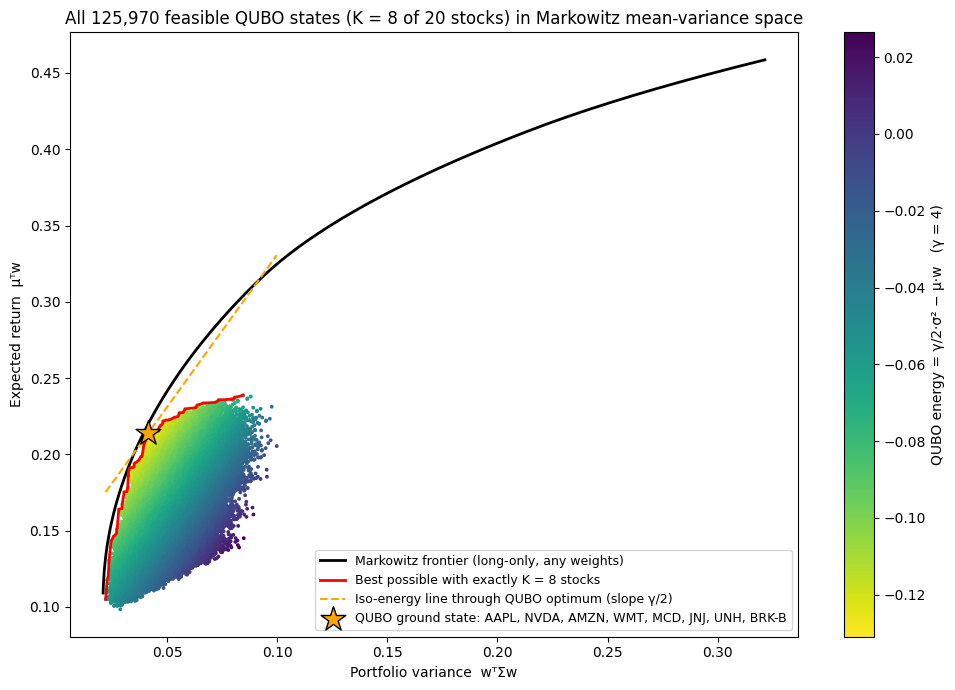

In [1]:
"""QUBO (select-K) energy landscape vs Markowitz frontier. Same formulation and settings as your notebook (cell 7)."""
import itertools, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.optimize import minimize

DATA_FILE, START, END = "us_stock_data/adj_close_wide.csv", "2000-01-01", "2026-01-01"
TD, GAMMA, K, PEN_MULT = 252, 4.0, 8, 2.0

ret = pd.read_csv(DATA_FILE, index_col="Date", parse_dates=True).sort_index().loc[START:END].pct_change().iloc[1:].dropna()
tick, N = list(ret.columns), ret.shape[1]
mu, Sigma = ret.mean().to_numpy() * TD, ret.cov().to_numpy() * TD

# QUBO exactly as in the notebook: f(z) = gamma/2 * w'Sigma w - mu'w + P (sum z - K)^2, with w = z/K
P = PEN_MULT * max(np.abs(mu).max() / K, 0.5 * GAMMA * np.diag(Sigma).max() / K**2)
Q = 0.5 * GAMMA / K**2 * Sigma - np.diag(mu / K) + P * (np.ones((N, N)) - 2 * K * np.eye(N))
const = P * K**2

# every one of the C(N,K) feasible bit strings
idx = np.array(list(itertools.combinations(range(N), K)))
Z = np.zeros((len(idx), N)); Z[np.arange(len(idx))[:, None], idx] = 1
W = Z / K
var, er = np.einsum("ij,jk,ik->i", W, Sigma, W), W @ mu
E = np.einsum("ij,jk,ik->i", Z, Q, Z) + const                 # QUBO energy
obj = 0.5 * GAMMA * var - er                                  # mean-variance objective
assert np.allclose(E, obj, atol=1e-9), "QUBO energy != Markowitz objective"   # penalty is 0 when sum z = K
g = np.argmin(E)                                              # exact QUBO ground state

# continuous long-only Markowitz frontier (SLSQP)
def frontier(targets):
    out, w0 = [], np.full(N, 1 / N)
    for t in targets:
        r = minimize(lambda w: w @ Sigma @ w, w0, jac=lambda w: 2 * Sigma @ w, method="SLSQP", bounds=[(0, 1)] * N,
                     constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1}, {"type": "eq", "fun": lambda w, t=t: w @ mu - t}])
        if r.success: out.append((r.fun, t)); w0 = r.x
    return np.array(out)
F = frontier(np.linspace(mu.min() * 1.02, mu.max() * 0.98, 80)); F = F[F[:, 1] >= F[np.argmin(F[:, 0]), 1]]   # efficient branch only

# cardinality-K frontier = upper-left envelope of the subset cloud
o = np.argsort(var); best, env = -np.inf, []
for i in o:
    if er[i] > best: best = er[i]; env.append(i)

fig, ax = plt.subplots(figsize=(10, 7))
sc = ax.scatter(var, er, c=E, s=3, cmap="viridis_r", rasterized=True)
fig.colorbar(sc, label=f"QUBO energy = γ/2·σ² − μ·w   (γ = {GAMMA:g})")
ax.plot(F[:, 0], F[:, 1], "k-", lw=2, label="Markowitz frontier (long-only, any weights)")
ax.plot(var[env], er[env], "r-", lw=2, label=f"Best possible with exactly K = {K} stocks")
xs = np.array([var.min(), var.max()])
ax.plot(xs, 0.5 * GAMMA * xs - E[g], "--", color="orange", lw=1.5, label="Iso-energy line through QUBO optimum (slope γ/2)")
ax.scatter(var[g], er[g], marker="*", s=350, c="orange", edgecolor="k", zorder=5,
           label="QUBO ground state: " + ", ".join(np.array(tick)[idx[g]]))
ax.set(xlabel="Portfolio variance  wᵀΣw", ylabel="Expected return  μᵀw",
       title=f"All {len(idx):,} feasible QUBO states (K = {K} of {N} stocks) in Markowitz mean-variance space")
ax.legend(loc="lower right", fontsize=9); plt.tight_layout(); plt.savefig("qubo_landscape.png", dpi=200)
print(f"{len(idx):,} states | energy == objective verified | ground state: {np.array(tick)[idx[g]].tolist()} | E = {E[g]:.4f}")

20 stocks | 2000-01-04 to 2025-12-31 | 6538 daily returns (0 rows dropped for missing values)
risk-free 0.0% | weight cap 30% | gamma 4 | covariance: sample
lambda = (R_t - RF) / var_t = (0.2272 - 0.0000) / 0.04418 = 5.1422
check : continuous mean-variance optimum at this lambda vs max-Sharpe portfolio -> max |weight difference| = 2.62e-06  (largest weight 19.8%, cap 30% not binding: True)

Monte Carlo finished in 1.3 s  (200 runs x 5000 random binary vectors, k = 1..20)
k = [1, 2]: in none of the 200 runs did any sampled vector gain by breaking the constraint, so the estimated penalty is P = 0 for these k (the constraint is never attractive to break).



,P mean,P std,P min,P median,P max (used),runs with P = 0 (no violation gains)
k,,,,,,
1,0.00000,0.00000,0.00000,0.00000,0.00000,200
2,0.00000,0.00000,0.00000,0.00000,0.00000,200
3,0.00162,0.00286,0.00000,0.00000,0.01408,118
4,0.00287,0.00410,0.00000,0.00064,0.02211,90
5,0.00587,0.00621,0.00000,0.00420,0.02356,64
6,0.00589,0.00661,0.00000,0.00332,0.02561,50
7,0.00486,0.00558,0.00000,0.00263,0.02360,52
8,0.00461,0.00451,0.00000,0.00319,0.01884,35
9,0.00499,0.00515,0.00000,0.00335,0.02914,34


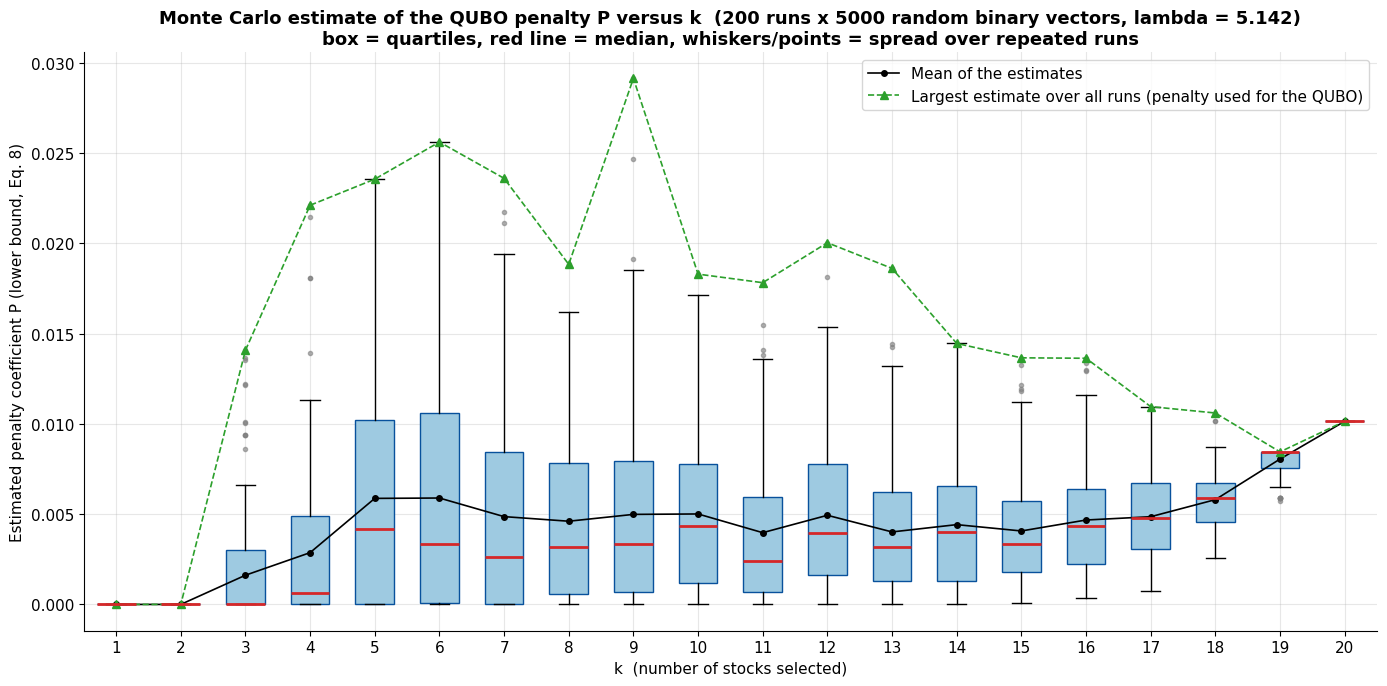

In [3]:
# =============================================================================
# SETUP (self-contained): loads the data, computes the full-period mu and Sigma and defines the helper functions.
# Identical to the code of your last cell (CELL 2, CELL 3 and CELL 5 parts); nothing needs to be run before this cell.
# Needs only  us_stock_data/adj_close_wide.csv  (written by your first cell).
# =============================================================================
# Same code as the notebook, as a plain script (run cell 1 first to create the CSV)

# =============================================================================
# CELL 2 | Settings, data and inputs (mu, Sigma) - computed ONCE from the full period
# Uses the adj_close_wide.csv written by cell 1.  Nothing is forecast: every optimiser
# below receives exactly the same table of expected returns and covariances.
# =============================================================================
import os, time, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import TwoSlopeNorm
from scipy.optimize import minimize
from IPython.display import display

warnings.filterwarnings("ignore")
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

# ----------------------------- user settings ---------------------------------
DATA_FILE   = "us_stock_data/adj_close_wide.csv"   # written by cell 1
OUT_DIR     = "qubo_fullperiod_outputs"            # figures and tables are saved here
START, END  = "2000-01-01", "2026-01-01"           # full period used for the single optimisation
TD          = 252                                  # trading days per year
RF          = 0.0                                  # risk-free rate (0 matches your Markowitz chart; 0.02 matches cell 3)
MAX_W       = 0.30                                 # cap per stock (1.0 = plain long-only Markowitz, but annealing then struggles; see notes)
GAMMA       = 4.0                                  # risk aversion in  gamma/2 * w'Sigma w - mu'w
UNITS       = 20                                   # weight grid: 1 unit = 1/UNITS of the portfolio (20 -> 5 %)
K_SELECT    = 8                                    # stocks held by the QUBO "select K" variant
PEN_MULT    = 2.0                                  # penalty strength for the budget / cardinality constraint
SA_CHAINS   = 128                                  # parallel annealing chains
SA_SWEEPS   = 150                                  # sweeps per chain
SEED        = 42
SHRINK_COV  = False                                # True -> Ledoit-Wolf shrinkage of the covariance matrix
X_AXIS      = "variance"                           # "variance" (like your chart) or "volatility"
SHOW_RANDOM = False                                # True -> add random portfolios behind the frontier
QUICK       = False                                # True -> smaller grids in the robustness cell

COLORS = {"EW": "#7f7f7f", "MinVar": "#1f77b4", "MaxSharpe": "#ff7f0e",
          "MeanVar": "#2ca02c", "QUBO-W": "#d62728", "QUBO-S": "#9467bd"}
LABELS = {"EW": "Equal weight (1/N)", "MinVar": "Min-variance", "MaxSharpe": "Max-Sharpe",
          "MeanVar": "Mean-variance (continuous)", "QUBO-W": "QUBO weights", "QUBO-S": "QUBO select-K"}

os.makedirs(OUT_DIR, exist_ok=True)
def savefig(name):
    plt.savefig(f"{OUT_DIR}/{name}.png", dpi=300, bbox_inches="tight")

# ------------------------------- data ----------------------------------------
prices = pd.read_csv(DATA_FILE, index_col="Date", parse_dates=True).sort_index().loc[START:END]
returns = prices.pct_change().iloc[1:]
n_rows = len(returns)
returns = returns.dropna()                          # only days on which every stock traded
tickers = list(returns.columns)
N = len(tickers)

def ledoit_wolf_cov(X):
    """Ledoit-Wolf shrinkage towards a scaled identity (same result as scikit-learn's LedoitWolf)."""
    X = X - X.mean(axis=0)
    T, n = X.shape
    S = X.T @ X / T
    m = np.trace(S) / n
    d2 = np.sum((S - m * np.eye(n)) ** 2)
    b2 = min((np.sum(np.sum(X ** 2, axis=1) ** 2) - T * np.sum(S ** 2)) / T ** 2, d2)
    sh = b2 / d2 if d2 > 0 else 0.0
    return (1 - sh) * S + sh * m * np.eye(n)

mu = returns.mean().to_numpy() * TD                                   # annualised mean return (arithmetic)
Sigma = (ledoit_wolf_cov(returns.to_numpy()) if SHRINK_COV else returns.cov().to_numpy()) * TD
assert np.all(np.linalg.eigvalsh(Sigma) > 0), "covariance matrix is not positive definite"

print(f"{N} stocks | {returns.index[0].date()} to {returns.index[-1].date()} | {len(returns)} daily returns "
      f"({n_rows - len(returns)} rows dropped for missing values)")
print(f"risk-free {RF:.1%} | weight cap {MAX_W:.0%} | gamma {GAMMA:g} | covariance: {'Ledoit-Wolf' if SHRINK_COV else 'sample'}")

def xs(var):
    """x-axis coordinate of a portfolio from its variance."""
    var = np.asarray(var, dtype=float)
    return var if X_AXIS == "variance" else np.sqrt(var)
XLABEL = "Annualised portfolio variance" if X_AXIS == "variance" else "Annualised volatility"


# =============================================================================
# CELL 3 | STEP 1: Classical Markowitz solutions (the reference the QUBO is compared with)
#   EW = equal weight | MinVar = minimum variance | MaxSharpe = tangency portfolio
#   MeanVar = minimise gamma/2 w'Sigma w - mu'w   (exactly the objective the QUBO encodes)
# All are long-only, fully invested, capped at MAX_W.
# =============================================================================
def equal_weight(n):
    return np.full(n, 1.0 / n)

def _slsqp(fun, jac, n, cap, starts):
    cons = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0, "jac": lambda w: np.ones(n)}]
    best = None
    for w0 in starts:
        res = minimize(fun, w0, jac=jac, method="SLSQP", bounds=[(0.0, cap)] * n,
                       constraints=cons, options={"maxiter": 1000, "ftol": 1e-12})
        if res.success and (best is None or res.fun < best.fun):
            best = res
    if best is None:
        return equal_weight(n)
    w = np.clip(best.x, 0.0, cap)
    return w / w.sum()

def min_variance(Sigma, cap):
    n = len(Sigma)
    return _slsqp(lambda w: w @ Sigma @ w, lambda w: 2 * Sigma @ w, n, cap, [equal_weight(n)])

def mean_variance(mu, Sigma, gamma, cap):
    n = len(mu)
    return _slsqp(lambda w: 0.5 * gamma * w @ Sigma @ w - mu @ w, lambda w: gamma * Sigma @ w - mu,
                  n, cap, [equal_weight(n), min_variance(Sigma, cap)])

def max_sharpe(mu, Sigma, cap, rf=RF):
    n = len(mu)
    def fun(w):
        return -(mu @ w - rf) / np.sqrt(w @ Sigma @ w)
    def jac(w):
        s = np.sqrt(w @ Sigma @ w)
        return -(mu / s - (mu @ w - rf) * (Sigma @ w) / s ** 3)
    return _slsqp(fun, jac, n, cap, [equal_weight(n), min_variance(Sigma, cap)])

def mv_objective(w, mu, Sigma, gamma):
    return 0.5 * gamma * w @ Sigma @ w - mu @ w

def port_stats(w, mu=mu, Sigma=Sigma):
    """(expected return, variance, volatility, Sharpe)"""
    ret, var = float(mu @ w), float(w @ Sigma @ w)
    return ret, var, np.sqrt(var), (ret - RF) / np.sqrt(var)

def frontier_points(mu, Sigma, cap, n_pts=80):
    """Long-only efficient frontier. Returns arrays (variance, return)."""
    n = len(mu)
    w_min = min_variance(Sigma, cap)
    order, w_hi, left = np.argsort(-mu), np.zeros(n), 1.0
    for i in order:                                    # highest return reachable under the cap
        take = min(cap, left); w_hi[i] = take; left -= take
        if left <= 1e-12: break
    pts = []
    for tr in np.linspace(mu @ w_min, mu @ w_hi, n_pts)[:-1]:
        cons = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0, "jac": lambda w: np.ones(n)},
                {"type": "eq", "fun": lambda w, tr=tr: mu @ w - tr, "jac": lambda w: mu}]
        res = minimize(lambda w: w @ Sigma @ w, w_min, jac=lambda w: 2 * Sigma @ w, method="SLSQP",
                       bounds=[(0.0, cap)] * n, constraints=cons, options={"maxiter": 1000, "ftol": 1e-12})
        if res.success:
            pts.append((res.fun, tr))
    pts.append((w_hi @ Sigma @ w_hi, mu @ w_hi))
    pts = np.array(pts)
    pts = pts[np.argsort(pts[:, 0])]
    return pts[:, 0], np.maximum.accumulate(pts[:, 1])      # variance ascending, return non-decreasing (efficient part only)

def frontier_return_at(var_target, mu, Sigma, cap, w_start):
    """Highest expected return reachable with variance <= var_target (long-only, capped): the exact frontier height at that risk."""
    n = len(mu)
    cons = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0, "jac": lambda w: np.ones(n)},
            {"type": "ineq", "fun": lambda w: var_target - w @ Sigma @ w, "jac": lambda w: -2 * Sigma @ w}]
    res = minimize(lambda w: -mu @ w, w_start, jac=lambda w: -mu, method="SLSQP", bounds=[(0.0, cap)] * n,
                   constraints=cons, options={"maxiter": 1000, "ftol": 1e-12})
    return float(mu @ res.x) if res.success else np.nan


t0 = time.time()
w_ew = equal_weight(N)
w_minvar = min_variance(Sigma, MAX_W)
w_maxsh = max_sharpe(mu, Sigma, MAX_W)
t_cls = time.time() - t0
t0 = time.time()
w_meanvar = mean_variance(mu, Sigma, GAMMA, MAX_W)
t_meanvar = time.time() - t0
f_var, f_ret = frontier_points(mu, Sigma, MAX_W)

# CELL 5 | STEP 3: QUBO solver - simulated annealing (pure NumPy, no extra packages)
#   simulated_annealing : many parallel chains, single-bit and two-bit flips
#   repair_units        : if a chain ends with a slightly broken budget, add / remove units greedily
#   decode_*            : bits -> weights
#   exact_select        : exhaustive search over all C(N,K) portfolios (exact optimum of QUBO-S)
# =============================================================================
def simulated_annealing(Q, n_chains=128, n_sweeps=150, rng=None, t_hi=None, t_lo=None, t_scale=0.1):
    """Minimise x'Qx over x in {0,1}^n. Returns final states (chains x n), energies (chains), (temperatures, mean energy per sweep).
    Each sweep proposes n single-bit flips and n two-bit flips (the two-bit moves swap one stock / weight unit for another)."""
    rng = rng if rng is not None else np.random.default_rng(SEED)
    Q = 0.5 * (Q + Q.T)
    n = Q.shape[0]
    d = np.diag(Q).copy()
    off = Q - np.diag(d)
    X = rng.integers(0, 2, size=(n_chains, n)).astype(float)
    H = X @ off
    E = np.einsum("ri,ri->r", X @ Q, X)
    if t_hi is None:                                   # start temperature: a fraction of the typical single-flip energy change
        t_hi = t_scale * np.median(np.abs((1 - 2 * X) * (d + 2 * H)))
    if t_lo is None:
        t_lo = t_hi * 1e-4
    temps = np.geomspace(t_hi, t_lo, n_sweeps)
    trace = np.empty(n_sweeps)
    for s, T in enumerate(temps):
        U1 = rng.random((n, n_chains))
        for j, i in enumerate(rng.permutation(n)):                      # single-bit flips
            delta = 1 - 2 * X[:, i]
            dE = delta * (d[i] + 2 * H[:, i])
            acc = (dE <= 0) | (U1[j] < np.exp(-np.maximum(dE, 0) / T))
            if acc.any():
                m = acc * delta
                X[:, i] += m; H += m[:, None] * off[i]; E += acc * dE
        U2 = rng.random((n, n_chains))
        pairs = np.array([rng.choice(n, 2, replace=False) for _ in range(n)])
        for j, (i, k) in enumerate(pairs):                              # two-bit flips
            di, dk = 1 - 2 * X[:, i], 1 - 2 * X[:, k]
            dE = di * (d[i] + 2 * H[:, i]) + dk * (d[k] + 2 * H[:, k]) + 2 * off[i, k] * di * dk
            acc = (dE <= 0) | (U2[j] < np.exp(-np.maximum(dE, 0) / T))
            if acc.any():
                mi, mk = acc * di, acc * dk
                X[:, i] += mi; X[:, k] += mk
                H += mi[:, None] * off[i] + mk[:, None] * off[k]; E += acc * dE
        trace[s] = E.mean()
    return X, np.einsum("ri,ri->r", X @ Q, X), (temps, trace)

def repair_units(u, f, total, cap_u):
    """Greedy repair: add / remove single units until sum(u) == total, always taking the best objective."""
    u = u.copy()
    while u.sum() > total:
        cand = np.flatnonzero(u > 0)
        vals = []
        for i in cand:
            u[i] -= 1; vals.append(f(u)); u[i] += 1
        u[cand[int(np.argmin(vals))]] -= 1
    while u.sum() < total:
        cand = np.flatnonzero(u < cap_u)
        vals = []
        for i in cand:
            u[i] += 1; vals.append(f(u)); u[i] -= 1
        u[cand[int(np.argmin(vals))]] += 1
    return u

def _units_w(X, q):
    return np.rint(X.reshape(len(X), q["n"], q["nb"]) @ q["a"]).astype(int)

def decode_weights(X, E, q, mu, Sigma, gamma, top=10):
    """Best QUBO-W portfolio among the `top` lowest-energy chains (after repair). Returns weights, info."""
    U = q["units"]
    f = lambda uu: mv_objective(uu / U, mu, Sigma, gamma)
    units_all = _units_w(X, q)
    best_u, best_f = None, np.inf
    for r in np.argsort(E)[:top]:
        u = repair_units(units_all[r], f, U, q["cap_u"])
        if f(u) < best_f:
            best_u, best_f = u, f(u)
    return best_u / U, dict(feasible_rate=float((units_all.sum(axis=1) == U).mean()), units=best_u)

def decode_select(X, E, q, mu, Sigma, gamma, top=10):
    k = q["k"]
    f = lambda uu: mv_objective(uu / k, mu, Sigma, gamma)
    best_u, best_f = None, np.inf
    for r in np.argsort(E)[:top]:
        u = repair_units(X[r].astype(int), f, k, 1)
        if f(u) < best_f:
            best_u, best_f = u, f(u)
    return best_u / k, dict(feasible_rate=float((X.sum(axis=1) == k).mean()), units=best_u)

def chain_objectives_w(X, q, mu, Sigma, gamma):
    """Objective of every chain's portfolio after repair (for the distribution plots)."""
    U = q["units"]
    f = lambda uu: mv_objective(uu / U, mu, Sigma, gamma)
    return np.array([f(repair_units(u, f, U, q["cap_u"])) for u in _units_w(X, q)])

def chain_objectives_s(X, q, mu, Sigma, gamma):
    k = q["k"]
    f = lambda uu: mv_objective(uu / k, mu, Sigma, gamma)
    return np.array([f(repair_units(z.astype(int), f, k, 1)) for z in X])

def exact_select(mu, Sigma, gamma, k, chunk=40000):
    """Exhaustive search over all C(N,k) equal-weight portfolios. Returns (best index set, best objective)."""
    n = len(mu)
    best_f, best_c = np.inf, None
    it = itertools.combinations(range(n), k)
    while True:
        block = list(itertools.islice(it, chunk))
        if not block:
            break
        c = np.array(block)
        var = Sigma[c[:, :, None], c[:, None, :]].sum(axis=(1, 2)) / k ** 2
        f = 0.5 * gamma * var - mu[c].sum(axis=1) / k
        j = int(np.argmin(f))
        if f[j] < best_f:
            best_f, best_c = float(f[j]), c[j]
    return best_c, best_f


# =============================================================================
# NEW CELL A | Monte Carlo estimate of the QUBO penalty coefficient P for k = 1 ... 20
#
# QUBO (select exactly k of the N stocks, equal weights 1/k, full-period mu and Sigma from the previous cell):
#     H(x) = f_k(x) + P * (sum(x) - k)^2 ,       f_k(x) = lambda/2 * (x'Sigma x)/k^2 - (mu'x)/k
# Penalty estimate = Algorithm 1 of the paper (Eq. 8) with  A = (1,...,1),  b = k :
#   1. Monte Carlo: draw MC_N random binary vectors x                        -> x_set
#   2. x_from = vector in x_set with the smallest constraint violation |A x - b|
#              (ties -> the one with the lowest f_k, the strongest feasible competitor)
#   3. x_to   = every vector in x_set with  f_k(x_to) < f_k(x_from)           (it "gains" by breaking the constraint)
#   4. candidate P = ( f_k(x_from) - f_k(x_to) ) / ( (A x_to - b)^2 - (A x_from - b)^2 )
#   5. lower bound of P = the largest candidate
# The whole procedure is repeated MC_RUNS times with new random samples -> spread of the estimate for every k.
# =============================================================================
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ----------------------------- settings --------------------------------------
K_LIST  = list(range(1, N + 1))        # k = 1 ... 20  (N = 20 stocks)
MC_N    = 5000                         # random binary vectors per Monte Carlo run
MC_RUNS = 200                          # independent repetitions (gives the spread shown in the chart)
MC_SEED = SEED + 7

# ----------------------------- risk aversion lambda -----------------------------
# lambda is NOT a free number: it is the value for which the continuous mean-variance problem
#     minimise  lambda/2 * w'Sigma w - mu'w     (long-only, fully invested)
# has the maximum-Sharpe portfolio of the previous cell as its exact optimum.  (First-order conditions of the
# tangency portfolio give  lambda = (R_t - RF) / sigma_t^2.)  So the QUBO uses the investor whose risk appetite
# corresponds to the best risk-adjusted portfolio on the efficient frontier; it comes from mu and Sigma only.
r_t, v_t, _, sh_t = port_stats(w_maxsh)
LAMBDA = (r_t - RF) / v_t
w_chk = mean_variance(mu, Sigma, LAMBDA, MAX_W)
print(f"lambda = (R_t - RF) / var_t = ({r_t:.4f} - {RF:.4f}) / {v_t:.5f} = {LAMBDA:.4f}")
print(f"check : continuous mean-variance optimum at this lambda vs max-Sharpe portfolio -> "
      f"max |weight difference| = {np.abs(w_chk - w_maxsh).max():.2e}  (largest weight {w_maxsh.max():.1%}, cap {MAX_W:.0%} not binding: {w_maxsh.max() < MAX_W - 1e-6})\n")

# ----------------------------- Monte Carlo ----------------------------------------
def mc_binary_samples(n, m, rng):
    """m random binary vectors; the number of ones of each vector is uniform on 0..n, the positions are random."""
    card = rng.integers(0, n + 1, size=m)
    rank = np.argsort(np.argsort(rng.random((m, n)), axis=1), axis=1)
    return (rank < card[:, None]).astype(float)

def penalty_lower_bound(q, lin, s, k, lam):
    """Algorithm 1 for one sample set. q = x'Sigma x, lin = mu'x, s = sum(x) for every sampled vector."""
    f = 0.5 * lam / k ** 2 * q - lin / k             # x'Hx  (objective part of the QUBO)
    viol = (s - k) ** 2                              # (A x - b)^2
    v_min = viol.min()
    f_from = f[viol == v_min].min()                  # x_from
    m = (f < f_from) & (viol > v_min)                # x_to  (positive denominator)
    if not m.any():
        return 0.0          # no sampled vector gains by breaking the constraint -> this run needs no penalty (P = 0)
    return ((f_from - f[m]) / (viol[m] - v_min)).max()          # Eq. 8, largest candidate

rng_mc = np.random.default_rng(MC_SEED)
MC_P = np.zeros((MC_RUNS, len(K_LIST)))
t0 = time.time()
for run in range(MC_RUNS):
    Xs = mc_binary_samples(N, MC_N, rng_mc)
    q, lin, s = np.einsum("ri,ij,rj->r", Xs, Sigma, Xs), Xs @ mu, Xs.sum(axis=1)
    for j, k in enumerate(K_LIST):
        MC_P[run, j] = penalty_lower_bound(q, lin, s, k, LAMBDA)
print(f"Monte Carlo finished in {time.time() - t0:.1f} s  ({MC_RUNS} runs x {MC_N} random binary vectors, k = {K_LIST[0]}..{K_LIST[-1]})")

P_K = MC_P.max(axis=0)                 # largest lower bound found for every k  -> penalty used by the next cell
no_gain = [k for k, p in zip(K_LIST, P_K) if p == 0]
if no_gain:
    print(f"k = {no_gain}: in none of the {MC_RUNS} runs did any sampled vector gain by breaking the constraint, "
          f"so the estimated penalty is P = 0 for these k (the constraint is never attractive to break).\n")

# ----------------------------- table ---------------------------------------------
P_TABLE = pd.DataFrame({
    "k": K_LIST,
    "P mean": MC_P.mean(axis=0), "P std": MC_P.std(axis=0, ddof=1),
    "P min": MC_P.min(axis=0), "P median": np.median(MC_P, axis=0),
    "P max (used)": P_K,
    "runs with P = 0 (no violation gains)": (MC_P == 0).sum(axis=0),
}).set_index("k")
display(P_TABLE.round(5))
P_TABLE.to_csv(f"{OUT_DIR}/mc_penalty_vs_k.csv")

# ----------------------------- chart: estimated penalty P versus k --------------------------
fig, ax = plt.subplots(figsize=(14, 7))
data = [MC_P[:, j] for j in range(len(K_LIST))]
bp = ax.boxplot(data, positions=K_LIST, widths=0.6, patch_artist=True, showfliers=True,
                boxprops=dict(facecolor="#9ecae1", edgecolor="#08519c"), medianprops=dict(color="#d62728", lw=2),
                flierprops=dict(marker="o", ms=3, markerfacecolor="grey", markeredgecolor="grey", alpha=0.6))
ax.plot(K_LIST, MC_P.mean(axis=0), color="black", marker="o", ms=4, lw=1.2, label="Mean of the estimates")
ax.plot(K_LIST, P_K, color="#2ca02c", marker="^", ms=6, lw=1.2, ls="--", label="Largest estimate over all runs (penalty used for the QUBO)")
ax.set_xticks(K_LIST)
ax.set_xlabel("k  (number of stocks selected)"); ax.set_ylabel("Estimated penalty coefficient P (lower bound, Eq. 8)")
ax.grid(True, alpha=0.3); ax.legend(loc="best")
ax.set_title(f"Monte Carlo estimate of the QUBO penalty P versus k  ({MC_RUNS} runs x {MC_N} random binary vectors, "
             f"lambda = {LAMBDA:.3f})\nbox = quartiles, red line = median, whiskers/points = spread over repeated runs",
             fontsize=13, fontweight="bold")
plt.tight_layout(); savefig("mc_penalty_vs_k"); plt.show()

Solved 20 QUBOs (annealing 128 chains x 150 sweeps + exhaustive check) in 4.4 s

k =  1 | JNJ  (each 100.00%)  |  return 10.24%, variance 0.0366, volatility 19.14%, Sharpe 0.535  |  matches exact optimum: True
k =  2 | AAPL, JNJ  (each 50.00%)  |  return 20.12%, variance 0.0544, volatility 23.31%, Sharpe 0.863  |  matches exact optimum: True
k =  3 | AAPL, MCD, UNH  (each 33.33%)  |  return 21.31%, variance 0.0498, volatility 22.31%, Sharpe 0.955  |  matches exact optimum: True
k =  4 | AAPL, NVDA, JNJ, UNH  (each 25.00%)  |  return 27.01%, variance 0.0660, volatility 25.70%, Sharpe 1.051  |  matches exact optimum: True
k =  5 | AAPL, NVDA, MCD, JNJ, UNH  (each 20.00%)  |  return 24.19%, variance 0.0513, volatility 22.65%, Sharpe 1.068  |  matches exact optimum: True
k =  6 | AAPL, NVDA, MCD, JNJ, UNH, BRK-B  (each 16.67%)  |  return 22.26%, variance 0.0431, volatility 20.75%, Sharpe 1.073  |  matches exact optimum: True
k =  7 | AAPL, NVDA, WMT, MCD, JNJ, UNH, BRK-B  (each 14.29%)  | 

,Weight each (%),Exp. return (%),Variance,Volatility (%),Sharpe,Objective (QUBO/SA),Objective (exact),SA = exact optimum,Chains feasible (%),Chains at exact optimum (%),P used
k,,,,,,,,,,,
1,100.0000,10.2369,0.0366,19.1362,0.5349,-0.0082,-0.0082,True,100.0000,100.0,0.0000
2,50.0000,20.1199,0.0544,23.3139,0.8630,-0.0615,-0.0615,True,100.0000,100.0,0.0000
3,33.3333,21.3059,0.0498,22.3104,0.9550,-0.0851,-0.0851,True,100.0000,100.0,0.0141
4,25.0000,27.0140,0.0660,25.6998,1.0511,-0.1003,-0.1003,True,100.0000,100.0,0.0221
5,20.0000,24.1908,0.0513,22.6474,1.0681,-0.1100,-0.1100,True,100.0000,100.0,0.0236
6,16.6667,22.2617,0.0431,20.7546,1.0726,-0.1119,-0.1119,True,100.0000,100.0,0.0256
7,14.2857,20.6062,0.0375,19.3578,1.0645,-0.1097,-0.1097,True,100.0000,100.0,0.0236
8,12.5000,21.1444,0.0403,20.0790,1.0531,-0.1078,-0.1078,True,100.0000,100.0,0.0188
9,11.1111,19.9810,0.0365,19.0999,1.0461,-0.1060,-0.1060,True,100.0000,100.0,0.0291


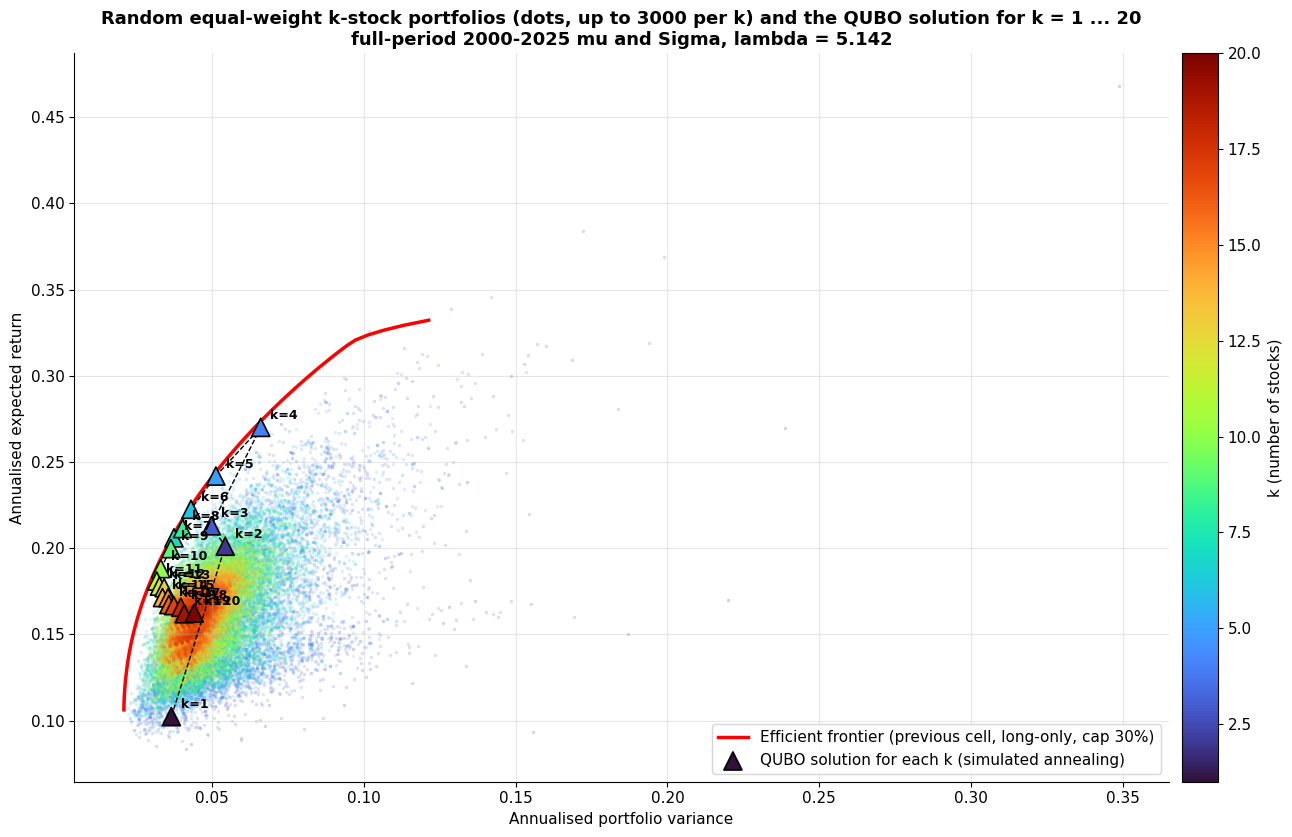

In [4]:
# =============================================================================
# NEW CELL B | QUBO solution for k = 1 ... 20  (simulated annealing + exact check)
# Needs the previous new cell (LAMBDA and the penalty P_K from the Monte Carlo) and the earlier cell's functions.
#     H(x) = lambda/2 * (x'Sigma x)/k^2 - (mu'x)/k + P_k * (sum(x) - k)^2 ,  x_i in {0,1}, weight of a chosen stock = 1/k
#     x'Qx + const  with  Q = lambda/(2k^2) Sigma - diag(mu/k) + P_k (11' - 2k I),  const = P_k k^2
# =============================================================================
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import comb

N_RANDOM = 3000                       # random k-stock portfolios drawn for each k (all of them if C(N,k) <= N_RANDOM)
QK_SEED  = SEED + 11

def build_qubo_select_P(mu, Sigma, lam, k, P):
    n = len(mu)
    Q = 0.5 * lam / k ** 2 * Sigma - np.diag(mu / k) + P * (np.ones((n, n)) - 2 * k * np.eye(n))
    return dict(Q=Q, const=P * k ** 2, n=n, k=k, P=P)

def random_subsets(n, k, m, rng):
    from itertools import combinations
    if comb(n, k) <= m:
        return np.array(list(combinations(range(n), k)))
    return np.argsort(rng.random((m, n)), axis=1)[:, :k]

rows, SOL = [], {}
rng_k = np.random.default_rng(QK_SEED)
t0 = time.time()
for j, k in enumerate(K_LIST):
    q = build_qubo_select_P(mu, Sigma, LAMBDA, k, P_K[j])
    X, E, _ = simulated_annealing(q["Q"], SA_CHAINS, SA_SWEEPS, rng=np.random.default_rng(SEED + 1000 + k))
    w, info = decode_select(X, E, q, mu, Sigma, LAMBDA)
    z = (w > 0).astype(float)
    # the QUBO energy of the chosen bit string must equal the objective (no penalty, the constraint holds)
    assert z.sum() == k and np.isclose(z @ q["Q"] @ z + q["const"], mv_objective(w, mu, Sigma, LAMBDA))
    sel_ex, f_ex = exact_select(mu, Sigma, LAMBDA, k)
    f_sa = mv_objective(w, mu, Sigma, LAMBDA)
    chain_f = chain_objectives_s(X, q, mu, Sigma, LAMBDA)
    ret, var, vol, sh = port_stats(w)
    SOL[k] = w
    rows.append({"k": k, "Selected stocks": ", ".join(t for t, wi in zip(tickers, w) if wi > 0),
                 "Weight each (%)": 100 / k, "Exp. return (%)": ret * 100, "Variance": var, "Volatility (%)": vol * 100,
                 "Sharpe": sh, "Objective (QUBO/SA)": f_sa, "Objective (exact)": f_ex,
                 "SA = exact optimum": bool(f_sa <= f_ex + 1e-10 and set(np.flatnonzero(w)) == set(sel_ex)),
                 "Chains feasible (%)": info["feasible_rate"] * 100,
                 "Chains at exact optimum (%)": float(np.mean(chain_f <= f_ex + 1e-10)) * 100,
                 "P used": P_K[j]})
print(f"Solved {len(K_LIST)} QUBOs (annealing {SA_CHAINS} chains x {SA_SWEEPS} sweeps + exhaustive check) in {time.time() - t0:.1f} s\n")

QK = pd.DataFrame(rows).set_index("k")
for k, r in QK.iterrows():
    print(f"k = {k:2d} | {r['Selected stocks']}  (each {r['Weight each (%)']:.2f}%)  |  return {r['Exp. return (%)']:.2f}%, "
          f"variance {r['Variance']:.4f}, volatility {r['Volatility (%)']:.2f}%, Sharpe {r['Sharpe']:.3f}  |  "
          f"matches exact optimum: {r['SA = exact optimum']}")
print()
display(QK.drop(columns=["Selected stocks"]).round(4))
QK.to_csv(f"{OUT_DIR}/qubo_solution_k_1_to_20.csv")
pd.DataFrame(SOL, index=tickers).T.mul(100).round(4).rename_axis("k").to_csv(f"{OUT_DIR}/qubo_weights_k_1_to_20.csv")

# ----------------------- chart: random k-stock portfolios and the QUBO solution of every k -----------------------
fig, ax = plt.subplots(figsize=(14, 8.5))
cmap = plt.get_cmap("turbo"); norm = plt.Normalize(K_LIST[0], K_LIST[-1])
for k in K_LIST:
    idx = random_subsets(N, k, N_RANDOM, rng_k)
    r_ = mu[idx].mean(axis=1)
    v_ = Sigma[idx[:, :, None], idx[:, None, :]].sum(axis=(1, 2)) / k ** 2
    ax.scatter(xs(v_), r_, s=6, alpha=0.18, color=cmap(norm(k)), linewidths=0, rasterized=True)
ax.plot(xs(f_var), f_ret, color="red", lw=2.5, label=f"Efficient frontier (previous cell, long-only, cap {MAX_W:.0%})", zorder=4)
qv = np.array([port_stats(SOL[k])[1] for k in K_LIST]); qr = np.array([port_stats(SOL[k])[0] for k in K_LIST])
ax.plot(xs(qv), qr, color="black", lw=1, ls="--", zorder=5)
ax.scatter(xs(qv), qr, c=K_LIST, cmap=cmap, norm=norm, marker="^", s=170, edgecolor="black", linewidths=1.2, zorder=6,
           label="QUBO solution for each k (simulated annealing)")
for k, x_, y_ in zip(K_LIST, xs(qv), qr):
    ax.annotate(f"k={k}", (x_, y_), xytext=(7, 6), textcoords="offset points", fontsize=9, fontweight="bold", zorder=7)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm); sm.set_array([])
cb = plt.colorbar(sm, ax=ax, pad=0.01); cb.set_label("k (number of stocks)")
ax.set_xlabel(XLABEL); ax.set_ylabel("Annualised expected return"); ax.grid(True, alpha=0.3); ax.legend(loc="lower right")
ax.set_title(f"Random equal-weight k-stock portfolios (dots, up to {N_RANDOM} per k) and the QUBO solution for k = 1 ... {N}\n"
             f"full-period {returns.index[0].year}-{returns.index[-1].year} mu and Sigma, lambda = {LAMBDA:.3f}",
             fontsize=13, fontweight="bold")
plt.tight_layout(); savefig("qubo_k_solutions_random_portfolios"); plt.show()

20 stocks | 2000-01-04 to 2025-12-31 | 6538 daily returns (0 rows dropped for missing values)
risk-free 0.0% | weight cap 30% | gamma 4 | covariance: sample
lambda = (R_t - RF) / var_t = (0.2272 - 0.0000) / 0.04418 = 5.1422   (check vs max-Sharpe portfolio: max |weight difference| = 2.6e-06)
QUBO solved for k = 1..20 in 5.4 s (annealing + exhaustive check).  Annealing = exact optimum for all k: True

QUBO RESULT: choose k = 6 of the 20 stocks, equal weight 16.67% each


,Annualised return (%),Volatility (%),Weight (%),Sharpe (stand-alone),Selected
AAPL,30.003,38.516,16.667,0.779,YES
NVDA,46.799,59.047,16.667,0.793,YES
MCD,12.898,22.726,16.667,0.568,YES
JNJ,10.237,19.136,16.667,0.535,YES
UNH,21.017,31.700,16.667,0.663,YES
BRK-B,12.617,21.877,16.667,0.577,YES
MSFT,14.555,30.005,0.000,0.485,-
AMZN,26.953,48.868,0.000,0.552,-
INTC,9.370,39.478,0.000,0.237,-
WMT,10.673,23.413,0.000,0.456,-



Full-period risk / return of the QUBO selection (same mu and Sigma for every row):


,Exp. return (%),Variance,Volatility (%),Sharpe,Objective,No. of stocks
QUBO selection (k = 6),22.2617,0.0431,20.7546,1.0726,-0.1119,6.0
"Equal weight, all 20 stocks",16.2444,0.0441,21.0050,0.7734,-0.0490,20.0
Markowitz max-Sharpe,22.7163,0.0442,21.0181,1.0808,-0.1136,9.0
Markowitz min-variance,10.6308,0.0210,14.4868,0.7338,-0.0523,10.0


QUBO solution for every k:


,Exp. return (%),Variance,Volatility (%),Sharpe,Objective,Objective (exact),SA = exact,P used
k,,,,,,,,
1,10.2369,0.0366,19.1362,0.5349,-0.0082,-0.0082,True,0.0000
2,20.1199,0.0544,23.3139,0.8630,-0.0615,-0.0615,True,0.0000
3,21.3059,0.0498,22.3104,0.9550,-0.0851,-0.0851,True,0.0141
4,27.0140,0.0660,25.6998,1.0511,-0.1003,-0.1003,True,0.0221
5,24.1908,0.0513,22.6474,1.0681,-0.1100,-0.1100,True,0.0236
6,22.2617,0.0431,20.7546,1.0726,-0.1119,-0.1119,True,0.0256
7,20.6062,0.0375,19.3578,1.0645,-0.1097,-0.1097,True,0.0236
8,21.1444,0.0403,20.0790,1.0531,-0.1078,-0.1078,True,0.0188
9,19.9810,0.0365,19.0999,1.0461,-0.1060,-0.1060,True,0.0291


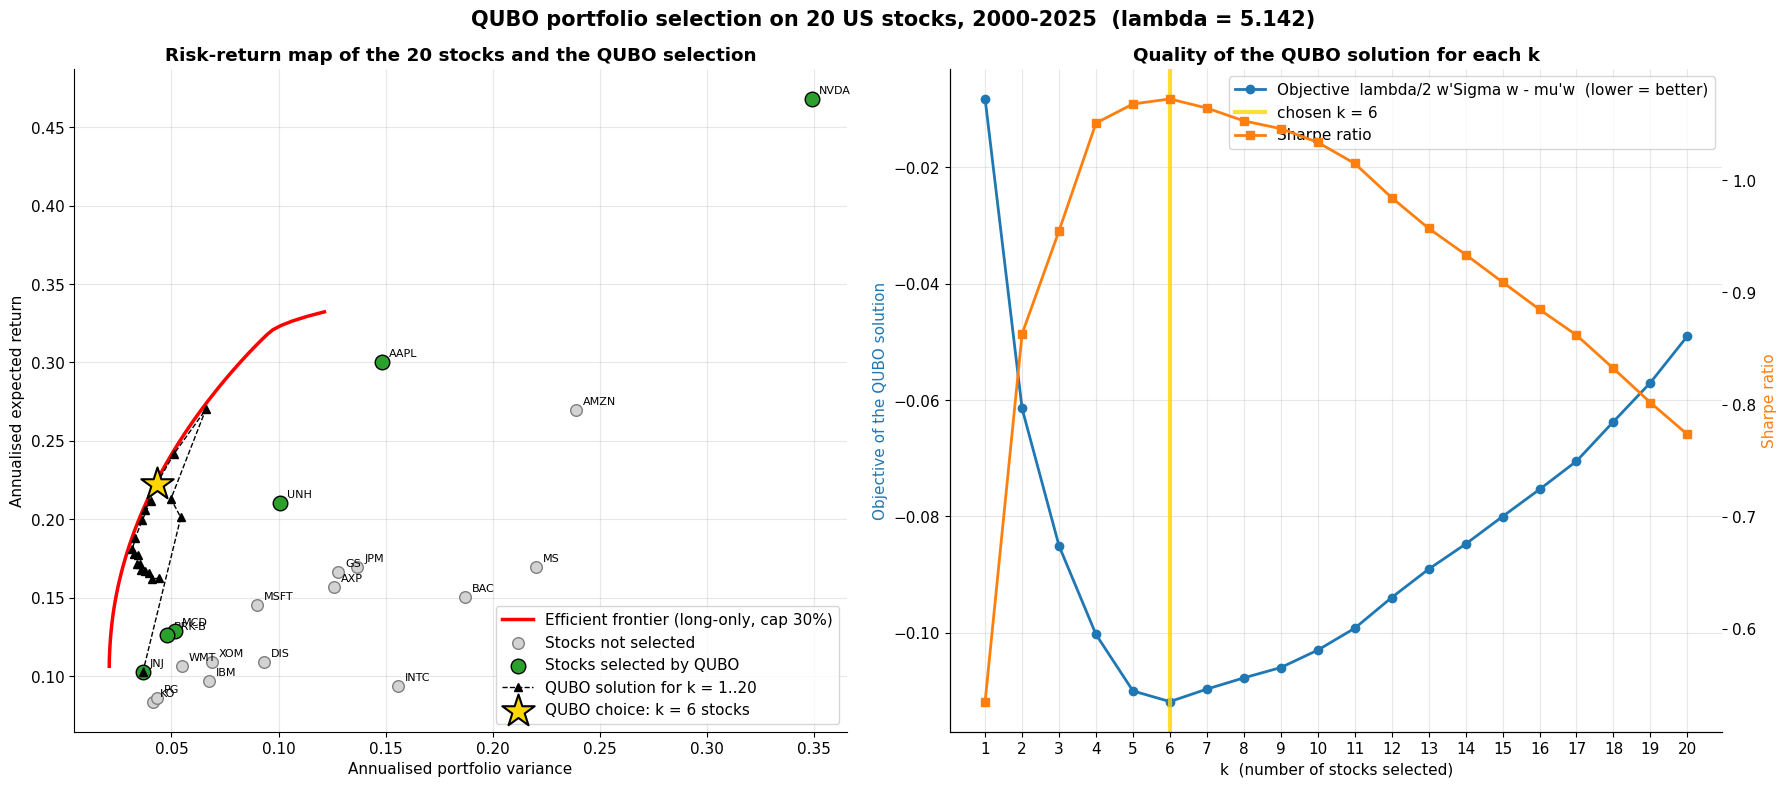

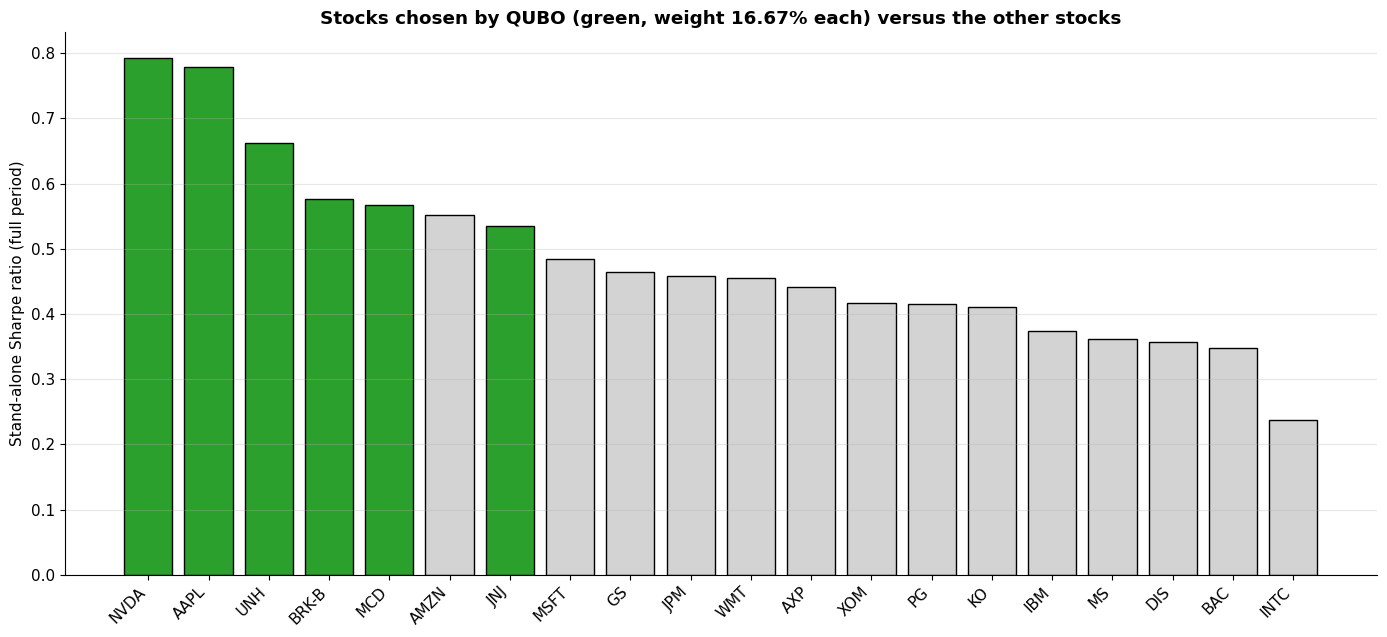

In [ ]:
# CELL 2 | Settings, data and inputs (mu, Sigma) - computed ONCE from the full period
# Uses the adj_close_wide.csv written by cell 1.  Nothing is forecast: every optimiser
# below receives exactly the same table of expected returns and covariances.

import os, time, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import TwoSlopeNorm
from scipy.optimize import minimize
from IPython.display import display

warnings.filterwarnings("ignore")
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

#  user settings
DATA_FILE   = "us_stock_data/adj_close_wide.csv"   # written by cell 1
OUT_DIR     = "qubo_fullperiod_outputs"            # figures and tables are saved here
START, END  = "2000-01-01", "2026-01-01"           # full period used for the single optimisation
TD          = 252                                  # trading days per year
RF          = 0.0                                  # risk-free rate (0 matches your Markowitz chart; 0.02 matches cell 3)
MAX_W       = 0.30                                 # cap per stock (1.0 = plain long-only Markowitz, but annealing then struggles; see notes)
GAMMA       = 4.0                                  # risk aversion in  gamma/2 * w'Sigma w - mu'w
UNITS       = 20                                   # weight grid: 1 unit = 1/UNITS of the portfolio (20 -> 5 %)
K_SELECT    = 8                                    # stocks held by the QUBO "select K" variant
PEN_MULT    = 2.0                                  # penalty strength for the budget / cardinality constraint
SA_CHAINS   = 128                                  # parallel annealing chains
SA_SWEEPS   = 150                                  # sweeps per chain
SEED        = 42
SHRINK_COV  = False                                # True -> Ledoit-Wolf shrinkage of the covariance matrix
X_AXIS      = "variance"                           # "variance" (like your chart) or "volatility"
SHOW_RANDOM = False                                # True -> add random portfolios behind the frontier
QUICK       = False                                # True -> smaller grids in the robustness cell

COLORS = {"EW": "#7f7f7f", "MinVar": "#1f77b4", "MaxSharpe": "#ff7f0e",
          "MeanVar": "#2ca02c", "QUBO-W": "#d62728", "QUBO-S": "#9467bd"}
LABELS = {"EW": "Equal weight (1/N)", "MinVar": "Min-variance", "MaxSharpe": "Max-Sharpe",
          "MeanVar": "Mean-variance (continuous)", "QUBO-W": "QUBO weights", "QUBO-S": "QUBO select-K"}

os.makedirs(OUT_DIR, exist_ok=True)
def savefig(name):
    plt.savefig(f"{OUT_DIR}/{name}.png", dpi=300, bbox_inches="tight")

#  data 
prices = pd.read_csv(DATA_FILE, index_col="Date", parse_dates=True).sort_index().loc[START:END]
returns = prices.pct_change().iloc[1:]
n_rows = len(returns)
returns = returns.dropna()                          # only days on which every stock traded
tickers = list(returns.columns)
N = len(tickers)

def ledoit_wolf_cov(X):
    """Ledoit-Wolf shrinkage towards a scaled identity (same result as scikit-learn's LedoitWolf)."""
    X = X - X.mean(axis=0)
    T, n = X.shape
    S = X.T @ X / T
    m = np.trace(S) / n
    d2 = np.sum((S - m * np.eye(n)) ** 2)
    b2 = min((np.sum(np.sum(X ** 2, axis=1) ** 2) - T * np.sum(S ** 2)) / T ** 2, d2)
    sh = b2 / d2 if d2 > 0 else 0.0
    return (1 - sh) * S + sh * m * np.eye(n)

mu = returns.mean().to_numpy() * TD                                   # annualised mean return (arithmetic)
Sigma = (ledoit_wolf_cov(returns.to_numpy()) if SHRINK_COV else returns.cov().to_numpy()) * TD
assert np.all(np.linalg.eigvalsh(Sigma) > 0), "covariance matrix is not positive definite"

print(f"{N} stocks | {returns.index[0].date()} to {returns.index[-1].date()} | {len(returns)} daily returns "
      f"({n_rows - len(returns)} rows dropped for missing values)")
print(f"risk-free {RF:.1%} | weight cap {MAX_W:.0%} | gamma {GAMMA:g} | covariance: {'Ledoit-Wolf' if SHRINK_COV else 'sample'}")

def xs(var):
    """x-axis coordinate of a portfolio from its variance."""
    var = np.asarray(var, dtype=float)
    return var if X_AXIS == "variance" else np.sqrt(var)
XLABEL = "Annualised portfolio variance" if X_AXIS == "variance" else "Annualised volatility"


# CELL 3 | STEP 1: Classical Markowitz solutions (the reference the QUBO is compared with)
#   EW = equal weight | MinVar = minimum variance | MaxSharpe = tangency portfolio
#   MeanVar = minimise gamma/2 w'Sigma w - mu'w   (exactly the objective the QUBO encodes)
# All are long-only, fully invested, capped at MAX_W.

def equal_weight(n):
    return np.full(n, 1.0 / n)

def _slsqp(fun, jac, n, cap, starts):
    cons = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0, "jac": lambda w: np.ones(n)}]
    best = None
    for w0 in starts:
        res = minimize(fun, w0, jac=jac, method="SLSQP", bounds=[(0.0, cap)] * n,
                       constraints=cons, options={"maxiter": 1000, "ftol": 1e-12})
        if res.success and (best is None or res.fun < best.fun):
            best = res
    if best is None:
        return equal_weight(n)
    w = np.clip(best.x, 0.0, cap)
    return w / w.sum()

def min_variance(Sigma, cap):
    n = len(Sigma)
    return _slsqp(lambda w: w @ Sigma @ w, lambda w: 2 * Sigma @ w, n, cap, [equal_weight(n)])

def mean_variance(mu, Sigma, gamma, cap):
    n = len(mu)
    return _slsqp(lambda w: 0.5 * gamma * w @ Sigma @ w - mu @ w, lambda w: gamma * Sigma @ w - mu,
                  n, cap, [equal_weight(n), min_variance(Sigma, cap)])

def max_sharpe(mu, Sigma, cap, rf=RF):
    n = len(mu)
    def fun(w):
        return -(mu @ w - rf) / np.sqrt(w @ Sigma @ w)
    def jac(w):
        s = np.sqrt(w @ Sigma @ w)
        return -(mu / s - (mu @ w - rf) * (Sigma @ w) / s ** 3)
    return _slsqp(fun, jac, n, cap, [equal_weight(n), min_variance(Sigma, cap)])

def mv_objective(w, mu, Sigma, gamma):
    return 0.5 * gamma * w @ Sigma @ w - mu @ w

def port_stats(w, mu=mu, Sigma=Sigma):
    """(expected return, variance, volatility, Sharpe)"""
    ret, var = float(mu @ w), float(w @ Sigma @ w)
    return ret, var, np.sqrt(var), (ret - RF) / np.sqrt(var)

def frontier_points(mu, Sigma, cap, n_pts=80):
    """Long-only efficient frontier. Returns arrays (variance, return)."""
    n = len(mu)
    w_min = min_variance(Sigma, cap)
    order, w_hi, left = np.argsort(-mu), np.zeros(n), 1.0
    for i in order:                                    # highest return reachable under the cap
        take = min(cap, left); w_hi[i] = take; left -= take
        if left <= 1e-12: break
    pts = []
    for tr in np.linspace(mu @ w_min, mu @ w_hi, n_pts)[:-1]:
        cons = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0, "jac": lambda w: np.ones(n)},
                {"type": "eq", "fun": lambda w, tr=tr: mu @ w - tr, "jac": lambda w: mu}]
        res = minimize(lambda w: w @ Sigma @ w, w_min, jac=lambda w: 2 * Sigma @ w, method="SLSQP",
                       bounds=[(0.0, cap)] * n, constraints=cons, options={"maxiter": 1000, "ftol": 1e-12})
        if res.success:
            pts.append((res.fun, tr))
    pts.append((w_hi @ Sigma @ w_hi, mu @ w_hi))
    pts = np.array(pts)
    pts = pts[np.argsort(pts[:, 0])]
    return pts[:, 0], np.maximum.accumulate(pts[:, 1])      # variance ascending, return non-decreasing (efficient part only)

def frontier_return_at(var_target, mu, Sigma, cap, w_start):
    """Highest expected return reachable with variance <= var_target (long-only, capped): the exact frontier height at that risk."""
    n = len(mu)
    cons = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0, "jac": lambda w: np.ones(n)},
            {"type": "ineq", "fun": lambda w: var_target - w @ Sigma @ w, "jac": lambda w: -2 * Sigma @ w}]
    res = minimize(lambda w: -mu @ w, w_start, jac=lambda w: -mu, method="SLSQP", bounds=[(0.0, cap)] * n,
                   constraints=cons, options={"maxiter": 1000, "ftol": 1e-12})
    return float(mu @ res.x) if res.success else np.nan


t0 = time.time()
w_ew = equal_weight(N)
w_minvar = min_variance(Sigma, MAX_W)
w_maxsh = max_sharpe(mu, Sigma, MAX_W)
t_cls = time.time() - t0
t0 = time.time()
w_meanvar = mean_variance(mu, Sigma, GAMMA, MAX_W)
t_meanvar = time.time() - t0
f_var, f_ret = frontier_points(mu, Sigma, MAX_W)

# CELL 5 | STEP 3: QUBO solver - simulated annealing (pure NumPy, no extra packages)
#   simulated_annealing : many parallel chains, single-bit and two-bit flips
#   repair_units        : if a chain ends with a slightly broken budget, add / remove units greedily
#   decode_*            : bits -> weights
#   exact_select        : exhaustive search over all C(N,K) portfolios (exact optimum of QUBO-S)

def simulated_annealing(Q, n_chains=128, n_sweeps=150, rng=None, t_hi=None, t_lo=None, t_scale=0.1):
    """Minimise x'Qx over x in {0,1}^n. Returns final states (chains x n), energies (chains), (temperatures, mean energy per sweep).
    Each sweep proposes n single-bit flips and n two-bit flips (the two-bit moves swap one stock / weight unit for another)."""
    rng = rng if rng is not None else np.random.default_rng(SEED)
    Q = 0.5 * (Q + Q.T)
    n = Q.shape[0]
    d = np.diag(Q).copy()
    off = Q - np.diag(d)
    X = rng.integers(0, 2, size=(n_chains, n)).astype(float)
    H = X @ off
    E = np.einsum("ri,ri->r", X @ Q, X)
    if t_hi is None:                                   # start temperature: a fraction of the typical single-flip energy change
        t_hi = t_scale * np.median(np.abs((1 - 2 * X) * (d + 2 * H)))
    if t_lo is None:
        t_lo = t_hi * 1e-4
    temps = np.geomspace(t_hi, t_lo, n_sweeps)
    trace = np.empty(n_sweeps)
    for s, T in enumerate(temps):
        U1 = rng.random((n, n_chains))
        for j, i in enumerate(rng.permutation(n)):                      # single-bit flips
            delta = 1 - 2 * X[:, i]
            dE = delta * (d[i] + 2 * H[:, i])
            acc = (dE <= 0) | (U1[j] < np.exp(-np.maximum(dE, 0) / T))
            if acc.any():
                m = acc * delta
                X[:, i] += m; H += m[:, None] * off[i]; E += acc * dE
        U2 = rng.random((n, n_chains))
        pairs = np.array([rng.choice(n, 2, replace=False) for _ in range(n)])
        for j, (i, k) in enumerate(pairs):                              # two-bit flips
            di, dk = 1 - 2 * X[:, i], 1 - 2 * X[:, k]
            dE = di * (d[i] + 2 * H[:, i]) + dk * (d[k] + 2 * H[:, k]) + 2 * off[i, k] * di * dk
            acc = (dE <= 0) | (U2[j] < np.exp(-np.maximum(dE, 0) / T))
            if acc.any():
                mi, mk = acc * di, acc * dk
                X[:, i] += mi; X[:, k] += mk
                H += mi[:, None] * off[i] + mk[:, None] * off[k]; E += acc * dE
        trace[s] = E.mean()
    return X, np.einsum("ri,ri->r", X @ Q, X), (temps, trace)

def repair_units(u, f, total, cap_u):
    """Greedy repair: add / remove single units until sum(u) == total, always taking the best objective."""
    u = u.copy()
    while u.sum() > total:
        cand = np.flatnonzero(u > 0)
        vals = []
        for i in cand:
            u[i] -= 1; vals.append(f(u)); u[i] += 1
        u[cand[int(np.argmin(vals))]] -= 1
    while u.sum() < total:
        cand = np.flatnonzero(u < cap_u)
        vals = []
        for i in cand:
            u[i] += 1; vals.append(f(u)); u[i] -= 1
        u[cand[int(np.argmin(vals))]] += 1
    return u

def _units_w(X, q):
    return np.rint(X.reshape(len(X), q["n"], q["nb"]) @ q["a"]).astype(int)

def decode_weights(X, E, q, mu, Sigma, gamma, top=10):
    """Best QUBO-W portfolio among the `top` lowest-energy chains (after repair). Returns weights, info."""
    U = q["units"]
    f = lambda uu: mv_objective(uu / U, mu, Sigma, gamma)
    units_all = _units_w(X, q)
    best_u, best_f = None, np.inf
    for r in np.argsort(E)[:top]:
        u = repair_units(units_all[r], f, U, q["cap_u"])
        if f(u) < best_f:
            best_u, best_f = u, f(u)
    return best_u / U, dict(feasible_rate=float((units_all.sum(axis=1) == U).mean()), units=best_u)

def decode_select(X, E, q, mu, Sigma, gamma, top=10):
    k = q["k"]
    f = lambda uu: mv_objective(uu / k, mu, Sigma, gamma)
    best_u, best_f = None, np.inf
    for r in np.argsort(E)[:top]:
        u = repair_units(X[r].astype(int), f, k, 1)
        if f(u) < best_f:
            best_u, best_f = u, f(u)
    return best_u / k, dict(feasible_rate=float((X.sum(axis=1) == k).mean()), units=best_u)

def chain_objectives_w(X, q, mu, Sigma, gamma):
    """Objective of every chain's portfolio after repair (for the distribution plots)."""
    U = q["units"]
    f = lambda uu: mv_objective(uu / U, mu, Sigma, gamma)
    return np.array([f(repair_units(u, f, U, q["cap_u"])) for u in _units_w(X, q)])

def chain_objectives_s(X, q, mu, Sigma, gamma):
    k = q["k"]
    f = lambda uu: mv_objective(uu / k, mu, Sigma, gamma)
    return np.array([f(repair_units(z.astype(int), f, k, 1)) for z in X])

def exact_select(mu, Sigma, gamma, k, chunk=40000):
    """Exhaustive search over all C(N,k) equal-weight portfolios. Returns (best index set, best objective)."""
    n = len(mu)
    best_f, best_c = np.inf, None
    it = itertools.combinations(range(n), k)
    while True:
        block = list(itertools.islice(it, chunk))
        if not block:
            break
        c = np.array(block)
        var = Sigma[c[:, :, None], c[:, None, :]].sum(axis=(1, 2)) / k ** 2
        f = 0.5 * gamma * var - mu[c].sum(axis=1) / k
        j = int(np.argmin(f))
        if f[j] < best_f:
            best_f, best_c = float(f[j]), c[j]
    return best_c, best_f



# QUBO STOCK SELECTION  |  picks the stocks of the 20 that give the best return for the risk taken
# (self-contained: nothing has to be run before this cell; needs us_stock_data/adj_close_wide.csv)
#
# Binary variable x_i = 1 if stock i is chosen; the chosen k stocks get equal weight 1/k.
#     H(x) = lambda/2 * (x'Sigma x)/k^2  -  (mu'x)/k  +  P_k * (sum(x) - k)^2           (QUBO: x'Qx + const)
#   mu, Sigma : full-period 2000-2025 annualised mean return and covariance (no train/test split, no backtest)
#   lambda    : risk aversion for which the continuous mean-variance optimum is the max-Sharpe portfolio
#               (lambda = (R_t - RF)/sigma_t^2, from mu and Sigma only)
#   P_k       : penalty from the Monte Carlo estimate (Algorithm 1 of the paper, Eq. 8), largest estimate of all runs
#   k         : the QUBO is solved for every k = 1..20 (simulated annealing + exhaustive check); the k whose QUBO
#               solution has the lowest value of the SAME risk-return objective  lambda/2 w'Sigma w - mu'w  is chosen.

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

K_LIST  = list(range(1, N + 1))
MC_N, MC_RUNS, MC_SEED = 5000, 200, SEED + 7

# lambda 
r_t, v_t, _, sh_t = port_stats(w_maxsh)
LAMBDA = (r_t - RF) / v_t
w_chk = mean_variance(mu, Sigma, LAMBDA, MAX_W)
print(f"lambda = (R_t - RF) / var_t = ({r_t:.4f} - {RF:.4f}) / {v_t:.5f} = {LAMBDA:.4f}   "
      f"(check vs max-Sharpe portfolio: max |weight difference| = {np.abs(w_chk - w_maxsh).max():.1e})")

# Monte Carlo penalty 
def mc_binary_samples(n, m, rng):
    card = rng.integers(0, n + 1, size=m)
    rank = np.argsort(np.argsort(rng.random((m, n)), axis=1), axis=1)
    return (rank < card[:, None]).astype(float)

def penalty_lower_bound(q, lin, s, k, lam):
    f = 0.5 * lam / k ** 2 * q - lin / k
    viol = (s - k) ** 2
    v_min = viol.min()
    f_from = f[viol == v_min].min()
    m = (f < f_from) & (viol > v_min)
    if not m.any():
        return 0.0
    return ((f_from - f[m]) / (viol[m] - v_min)).max()

rng_mc = np.random.default_rng(MC_SEED)
MC_P = np.zeros((MC_RUNS, len(K_LIST)))
for run in range(MC_RUNS):
    Xs = mc_binary_samples(N, MC_N, rng_mc)
    q_, lin_, s_ = np.einsum("ri,ij,rj->r", Xs, Sigma, Xs), Xs @ mu, Xs.sum(axis=1)
    for j, k in enumerate(K_LIST):
        MC_P[run, j] = penalty_lower_bound(q_, lin_, s_, k, LAMBDA)
P_K = MC_P.max(axis=0)

#  QUBO for every k 
def build_qubo_select_P(mu, Sigma, lam, k, P):
    n = len(mu)
    Q = 0.5 * lam / k ** 2 * Sigma - np.diag(mu / k) + P * (np.ones((n, n)) - 2 * k * np.eye(n))
    return dict(Q=Q, const=P * k ** 2, n=n, k=k, P=P)

rows, SOL = [], {}
t0 = time.time()
for j, k in enumerate(K_LIST):
    q = build_qubo_select_P(mu, Sigma, LAMBDA, k, P_K[j])
    X, E, _ = simulated_annealing(q["Q"], SA_CHAINS, SA_SWEEPS, rng=np.random.default_rng(SEED + 1000 + k))
    w, info = decode_select(X, E, q, mu, Sigma, LAMBDA)
    z = (w > 0).astype(float)
    assert z.sum() == k and np.isclose(z @ q["Q"] @ z + q["const"], mv_objective(w, mu, Sigma, LAMBDA))
    sel_ex, f_ex = exact_select(mu, Sigma, LAMBDA, k)
    f_sa = mv_objective(w, mu, Sigma, LAMBDA)
    ret, var, vol, sh = port_stats(w)
    SOL[k] = w
    rows.append({"k": k, "Exp. return (%)": ret * 100, "Variance": var, "Volatility (%)": vol * 100, "Sharpe": sh,
                 "Objective": f_sa, "Objective (exact)": f_ex,
                 "SA = exact": bool(f_sa <= f_ex + 1e-10 and set(np.flatnonzero(w)) == set(sel_ex)),
                 "P used": P_K[j]})
QK = pd.DataFrame(rows).set_index("k")
print(f"QUBO solved for k = 1..{N} in {time.time() - t0:.1f} s (annealing + exhaustive check).  "
      f"Annealing = exact optimum for all k: {bool(QK['SA = exact'].all())}\n")

#  choose k and report 
K_STAR = int(QK["Objective"].idxmin())
w_star = SOL[K_STAR]
sel = np.flatnonzero(w_star)
print("=" * 78)
print(f"QUBO RESULT: choose k = {K_STAR} of the {N} stocks, equal weight {100 / K_STAR:.2f}% each")
print("=" * 78)
stock_tab = pd.DataFrame({"Annualised return (%)": mu * 100, "Volatility (%)": np.sqrt(np.diag(Sigma)) * 100,
                          "Weight (%)": w_star * 100}, index=tickers)
stock_tab["Sharpe (stand-alone)"] = (mu - RF) / np.sqrt(np.diag(Sigma))
stock_tab["Selected"] = np.where(w_star > 0, "YES", "-")
display(stock_tab.sort_values(["Selected", "Weight (%)"], ascending=[False, False]).round(3))

cmp_rows = {}
for name, w_ in [(f"QUBO selection (k = {K_STAR})", w_star), ("Equal weight, all 20 stocks", w_ew),
                 ("Markowitz max-Sharpe", w_maxsh), ("Markowitz min-variance", w_minvar)]:
    r_, v_, s_, h_ = port_stats(w_)
    cmp_rows[name] = {"Exp. return (%)": r_ * 100, "Variance": v_, "Volatility (%)": s_ * 100, "Sharpe": h_,
                      "Objective": mv_objective(w_, mu, Sigma, LAMBDA), "No. of stocks": int((w_ > 1e-6).sum())}
CMP = pd.DataFrame(cmp_rows).T
print("\nFull-period risk / return of the QUBO selection (same mu and Sigma for every row):")
display(CMP.round(4))
print("QUBO solution for every k:")
display(QK.round(4))
QK.to_csv(f"{OUT_DIR}/qubo_selection_all_k.csv"); CMP.to_csv(f"{OUT_DIR}/qubo_selection_comparison.csv")
stock_tab.to_csv(f"{OUT_DIR}/qubo_selection_stocks.csv")

#  chart 1: risk-return map + choice of k 
sig2 = np.diag(Sigma)
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
ax = axes[0]
ax.plot(xs(f_var), f_ret, color="red", lw=2.5, label=f"Efficient frontier (long-only, cap {MAX_W:.0%})", zorder=2)
ax.scatter(xs(sig2[w_star == 0]), mu[w_star == 0], s=70, color="lightgrey", edgecolor="grey", label="Stocks not selected", zorder=3)
ax.scatter(xs(sig2[sel]), mu[sel], s=110, color="#2ca02c", edgecolor="black", label="Stocks selected by QUBO", zorder=4)
for i, t in enumerate(tickers):
    ax.annotate(t, (xs(sig2[i]), mu[i]), xytext=(5, 4), textcoords="offset points", fontsize=8)
qv = np.array([port_stats(SOL[k])[1] for k in K_LIST]); qr = np.array([port_stats(SOL[k])[0] for k in K_LIST])
ax.plot(xs(qv), qr, color="black", lw=1, ls="--", marker="^", ms=6, label="QUBO solution for k = 1..20", zorder=5)
rs, vs_, _, _ = port_stats(w_star)
ax.scatter(xs(vs_), rs, marker="*", s=600, color="gold", edgecolor="black", linewidths=1.5, zorder=6,
           label=f"QUBO choice: k = {K_STAR} stocks")
ax.set_xlabel(XLABEL); ax.set_ylabel("Annualised expected return"); ax.grid(True, alpha=0.3); ax.legend(loc="lower right")
ax.set_title("Risk-return map of the 20 stocks and the QUBO selection", fontweight="bold")

ax = axes[1]
ax.plot(K_LIST, QK["Objective"], color="#1f77b4", marker="o", lw=2, label="Objective  lambda/2 w'Sigma w - mu'w  (lower = better)")
ax.axvline(K_STAR, color="gold", lw=3, alpha=0.8, label=f"chosen k = {K_STAR}")
ax.set_xlabel("k  (number of stocks selected)"); ax.set_ylabel("Objective of the QUBO solution", color="#1f77b4")
ax.set_xticks(K_LIST); ax.grid(True, alpha=0.3)
ax2 = ax.twinx(); ax2.plot(K_LIST, QK["Sharpe"], color="#ff7f0e", marker="s", lw=2, label="Sharpe ratio"); ax2.set_ylabel("Sharpe ratio", color="#ff7f0e")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, loc="best")
ax.set_title("Quality of the QUBO solution for each k", fontweight="bold")
fig.suptitle(f"QUBO portfolio selection on {N} US stocks, {returns.index[0].year}-{returns.index[-1].year}  (lambda = {LAMBDA:.3f})",
             fontsize=15, fontweight="bold")
plt.tight_layout(); savefig("qubo_selection_riskreturn_and_k"); plt.show()

#  chart 2: the selected stocks 
order = np.argsort(-(mu - RF) / np.sqrt(sig2))
fig, ax = plt.subplots(figsize=(14, 6.5))
colors = ["#2ca02c" if w_star[i] > 0 else "lightgrey" for i in order]
ax.bar([tickers[i] for i in order], ((mu - RF) / np.sqrt(sig2))[order], color=colors, edgecolor="black")
ax.set_ylabel("Stand-alone Sharpe ratio (full period)"); ax.grid(True, axis="y", alpha=0.3)
ax.set_title(f"Stocks chosen by QUBO (green, weight {100 / K_STAR:.2f}% each) versus the other stocks", fontweight="bold")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); savefig("qubo_selection_stocks"); plt.show()


[01/20] MSFT - Microsoft Corporation
  -> 6539 rows (2000-01-03 to 2025-12-31)
[02/20] AAPL - Apple Inc.
  -> 6539 rows (2000-01-03 to 2025-12-31)
[03/20] NVDA - NVIDIA Corporation
  -> 6539 rows (2000-01-03 to 2025-12-31)
[04/20] AMZN - Amazon.com Inc.
  -> 6539 rows (2000-01-03 to 2025-12-31)
[05/20] INTC - Intel Corporation
  -> 6539 rows (2000-01-03 to 2025-12-31)
[06/20] WMT - Walmart Inc.
  -> 6539 rows (2000-01-03 to 2025-12-31)
[07/20] KO - The Coca-Cola Company
  -> 6539 rows (2000-01-03 to 2025-12-31)
[08/20] DIS - The Walt Disney Company
  -> 6539 rows (2000-01-03 to 2025-12-31)
[09/20] PG - The Procter & Gamble Company
  -> 6539 rows (2000-01-03 to 2025-12-31)
[10/20] IBM - International Business Machines
  -> 6539 rows (2000-01-03 to 2025-12-31)
[11/20] MCD - McDonald's Corporation
  -> 6539 rows (2000-01-03 to 2025-12-31)
[12/20] JPM - JPMorgan Chase & Co.
  -> 6539 rows (2000-01-03 to 2025-12-31)
[13/20] GS - The Goldman Sachs Group, Inc.
  -> 6539 rows (2000-01-03 to 2

,Annualised return (%),Volatility (%),Weight (%),Sharpe (stand-alone),Selected
AAPL,30.003,38.516,16.667,0.779,YES
NVDA,46.799,59.047,16.667,0.793,YES
MCD,12.898,22.726,16.667,0.568,YES
JNJ,10.237,19.136,16.667,0.535,YES
UNH,21.017,31.700,16.667,0.663,YES
BRK-B,12.617,21.877,16.667,0.577,YES
MSFT,14.555,30.005,0.000,0.485,-
AMZN,26.953,48.868,0.000,0.552,-
INTC,9.370,39.478,0.000,0.237,-
WMT,10.673,23.413,0.000,0.456,-



Full-period risk / return of the QUBO selection (same mu and Sigma for every row):


,Exp. return (%),Variance,Volatility (%),Sharpe,Objective,No. of stocks
QUBO selection (k = 6),22.2617,0.0431,20.7546,1.0726,-0.1119,6.0
"Equal weight, all 20 stocks",16.2444,0.0441,21.0050,0.7734,-0.0490,20.0
Markowitz max-Sharpe,22.7163,0.0442,21.0181,1.0808,-0.1136,9.0
Markowitz min-variance,10.6308,0.0210,14.4868,0.7338,-0.0523,10.0


QUBO solution for every k:


,Exp. return (%),Variance,Volatility (%),Sharpe,Objective,Objective (exact),SA = exact,P used
k,,,,,,,,
1,10.2369,0.0366,19.1362,0.5349,-0.0082,-0.0082,True,0.0000
2,20.1199,0.0544,23.3139,0.8630,-0.0615,-0.0615,True,0.0000
3,21.3059,0.0498,22.3104,0.9550,-0.0851,-0.0851,True,0.0141
4,27.0140,0.0660,25.6998,1.0511,-0.1003,-0.1003,True,0.0221
5,24.1908,0.0513,22.6474,1.0681,-0.1100,-0.1100,True,0.0236
6,22.2617,0.0431,20.7546,1.0726,-0.1119,-0.1119,True,0.0256
7,20.6062,0.0375,19.3578,1.0645,-0.1097,-0.1097,True,0.0236
8,21.1444,0.0403,20.0790,1.0531,-0.1078,-0.1078,True,0.0188
9,19.9810,0.0365,19.0999,1.0461,-0.1060,-0.1060,True,0.0291


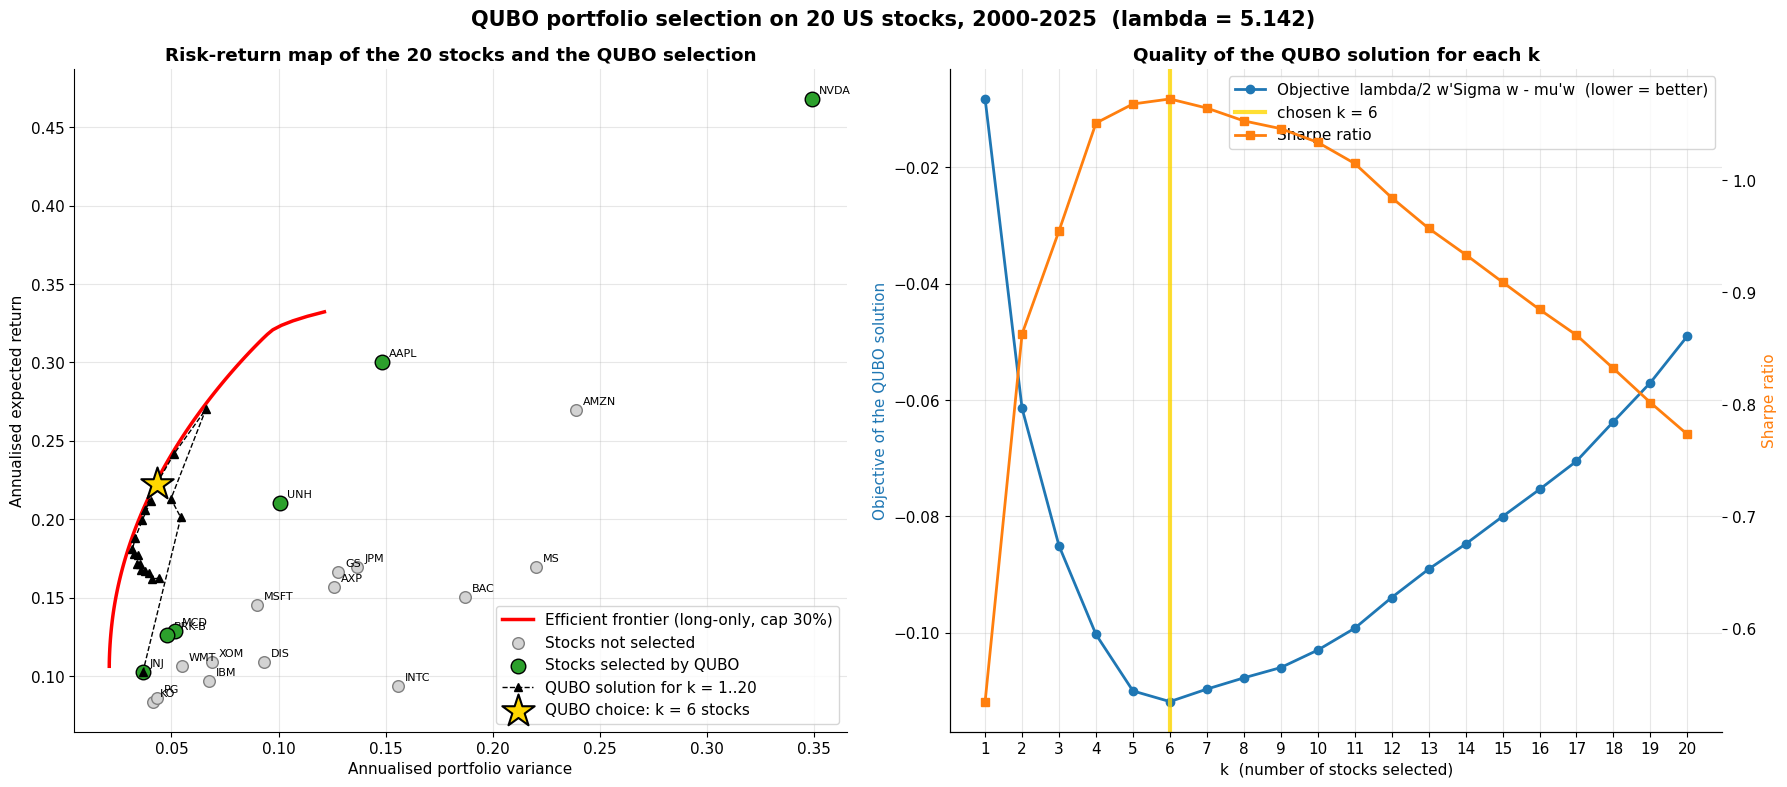

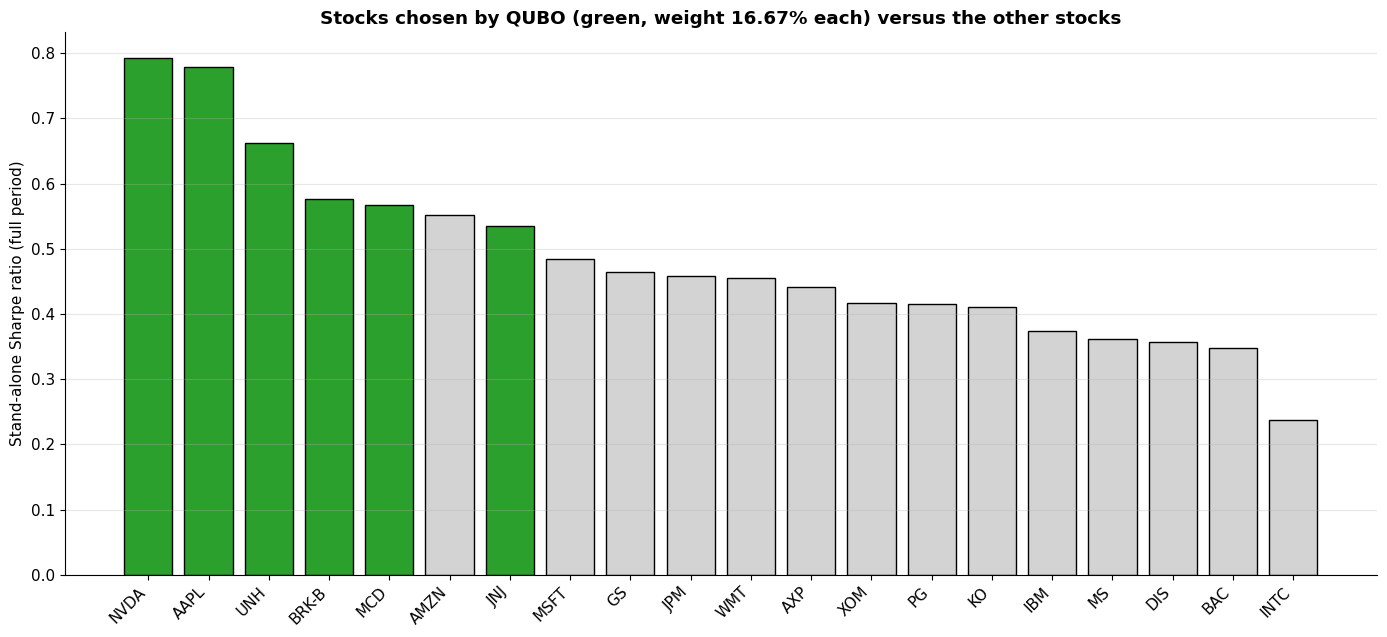

In [6]:
# =============================================================================
# PART 1 | Data collection (your cell 1, unchanged): downloads the 20 stocks with yfinance
#          and writes us_stock_data/adj_close_wide.csv  (needs internet + pip install yfinance)
# =============================================================================
"""
Collect daily price data for 20 US stocks using yfinance.
Period: 2000-01-01 to 2026-01-01

Outputs (in ./us_stock_data):
  - <TICKER>.csv          : per-stock OHLCV data
  - all_stocks_long.csv   : all stocks stacked (Date, Ticker, OHLCV)
  - adj_close_wide.csv    : Date x Ticker matrix of adjusted close prices
  - close_wide.csv        : Date x Ticker matrix of raw close prices
  - download_summary.csv  : rows, first/last date per ticker

Install:  pip install yfinance pandas
"""

import os
import time

import pandas as pd
import yfinance as yf

# ----------------------------------------------------------------------
# Configuration
# ----------------------------------------------------------------------
START_DATE = "2000-01-01"
END_DATE = "2026-01-01"   # yfinance 'end' is exclusive
OUTPUT_DIR = "us_stock_data"
MAX_RETRIES = 3

# Note: Yahoo Finance uses a hyphen for share classes: BRK.B -> BRK-B
# (BRK-A is also available; add it below if you want both share classes.)
STOCKS = {
    "MSFT":  "Microsoft Corporation",
    "AAPL":  "Apple Inc.",
    "NVDA":  "NVIDIA Corporation",
    "AMZN":  "Amazon.com Inc.",
    "INTC":  "Intel Corporation",
    "WMT":   "Walmart Inc.",
    "KO":    "The Coca-Cola Company",
    "DIS":   "The Walt Disney Company",
    "PG":    "The Procter & Gamble Company",
    "IBM":   "International Business Machines",
    "MCD":   "McDonald's Corporation",
    "JPM":   "JPMorgan Chase & Co.",
    "GS":    "The Goldman Sachs Group, Inc.",
    "MS":    "Morgan Stanley",
    "AXP":   "American Express Company",
    "BAC":   "Bank of America Corporation",
    "JNJ":   "Johnson & Johnson",
    "XOM":   "ExxonMobil Corporation",
    "UNH":   "UnitedHealth Group Incorporated",
    "BRK-B": "Berkshire Hathaway Inc. (Class B)",
    # "BRK-A": "Berkshire Hathaway Inc. (Class A)",
}


# ----------------------------------------------------------------------
# Download helper
# ----------------------------------------------------------------------
def download_ticker(ticker: str) -> pd.DataFrame:
    """Download daily OHLCV for one ticker, with retries.

    auto_adjust=False keeps both 'Close' (split-adjusted) and 'Adj Close'
    (split + dividend adjusted).
    """
    for attempt in range(1, MAX_RETRIES + 1):
        try:
            df = yf.download(
                ticker,
                start=START_DATE,
                end=END_DATE,
                interval="1d",
                auto_adjust=False,
                progress=False,
                threads=False,
            )
            if df is not None and not df.empty:
                # Newer yfinance versions return MultiIndex columns
                if isinstance(df.columns, pd.MultiIndex):
                    df.columns = df.columns.get_level_values(0)
                df.index = pd.to_datetime(df.index)
                df.index.name = "Date"
                df = df[["Open", "High", "Low", "Close", "Adj Close", "Volume"]]
                return df.dropna(how="all")
            print(f"  [{ticker}] empty result (attempt {attempt}/{MAX_RETRIES})")
        except Exception as e:
            print(f"  [{ticker}] error: {e} (attempt {attempt}/{MAX_RETRIES})")
        time.sleep(2 * attempt)
    return pd.DataFrame()


# ----------------------------------------------------------------------
# Main
# ----------------------------------------------------------------------
def main():
    os.makedirs(OUTPUT_DIR, exist_ok=True)

    data = {}
    summary = []
    failed = []

    print(f"Downloading {len(STOCKS)} stocks from {START_DATE} to {END_DATE}\n")

    for i, (ticker, name) in enumerate(STOCKS.items(), start=1):
        print(f"[{i:02d}/{len(STOCKS)}] {ticker} - {name}")
        df = download_ticker(ticker)

        if df.empty:
            failed.append(ticker)
            continue

        df.to_csv(os.path.join(OUTPUT_DIR, f"{ticker}.csv"))
        data[ticker] = df
        summary.append(
            {
                "Ticker": ticker,
                "Name": name,
                "Rows": len(df),
                "First_Date": df.index.min().date(),
                "Last_Date": df.index.max().date(),
                "Missing_Close": int(df["Close"].isna().sum()),
            }
        )
        print(f"  -> {len(df)} rows ({df.index.min().date()} to {df.index.max().date()})")
        time.sleep(0.5)  # be polite to Yahoo

    if not data:
        raise SystemExit("No data downloaded. Check your internet connection.")

    # Long format (all stocks stacked)
    long_df = (
        pd.concat(data, names=["Ticker", "Date"])
        .reset_index()
        .sort_values(["Ticker", "Date"])
    )
    long_df.to_csv(os.path.join(OUTPUT_DIR, "all_stocks_long.csv"), index=False)

    # Wide format matrices (Date x Ticker)
    adj_close = pd.DataFrame({t: d["Adj Close"] for t, d in data.items()}).sort_index()
    close = pd.DataFrame({t: d["Close"] for t, d in data.items()}).sort_index()
    adj_close.to_csv(os.path.join(OUTPUT_DIR, "adj_close_wide.csv"))
    close.to_csv(os.path.join(OUTPUT_DIR, "close_wide.csv"))

    # Summary
    summary_df = pd.DataFrame(summary)
    summary_df.to_csv(os.path.join(OUTPUT_DIR, "download_summary.csv"), index=False)

    print("\n" + "=" * 70)
    print(summary_df.to_string(index=False))
    print("=" * 70)
    print(f"Successful: {len(data)}/{len(STOCKS)}")
    if failed:
        print(f"Failed: {failed}")
    print(f"Files saved in: ./{OUTPUT_DIR}/")


if __name__ == "__main__":
    main()

# =============================================================================
# PART 2 | QUBO stock selection on the data collected above
# =============================================================================
# =============================================================================
# SETUP (self-contained): loads the data, computes the full-period mu and Sigma and defines the helper functions.
# Identical to the code of your last cell (CELL 2, CELL 3 and CELL 5 parts); nothing needs to be run before this cell.
# Needs only  us_stock_data/adj_close_wide.csv  (written by your first cell).
# =============================================================================
# Same code as the notebook, as a plain script (run cell 1 first to create the CSV)

# =============================================================================
# CELL 2 | Settings, data and inputs (mu, Sigma) - computed ONCE from the full period
# Uses the adj_close_wide.csv written by cell 1.  Nothing is forecast: every optimiser
# below receives exactly the same table of expected returns and covariances.
# =============================================================================
import os, time, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import TwoSlopeNorm
from scipy.optimize import minimize
from IPython.display import display

warnings.filterwarnings("ignore")
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

# ----------------------------- user settings ---------------------------------
DATA_FILE   = "us_stock_data/adj_close_wide.csv"   # written by cell 1
OUT_DIR     = "qubo_fullperiod_outputs"            # figures and tables are saved here
START, END  = "2000-01-01", "2026-01-01"           # full period used for the single optimisation
TD          = 252                                  # trading days per year
RF          = 0.0                                  # risk-free rate (0 matches your Markowitz chart; 0.02 matches cell 3)
MAX_W       = 0.30                                 # cap per stock (1.0 = plain long-only Markowitz, but annealing then struggles; see notes)
GAMMA       = 4.0                                  # risk aversion in  gamma/2 * w'Sigma w - mu'w
UNITS       = 20                                   # weight grid: 1 unit = 1/UNITS of the portfolio (20 -> 5 %)
K_SELECT    = 8                                    # stocks held by the QUBO "select K" variant
PEN_MULT    = 2.0                                  # penalty strength for the budget / cardinality constraint
SA_CHAINS   = 128                                  # parallel annealing chains
SA_SWEEPS   = 150                                  # sweeps per chain
SEED        = 42
SHRINK_COV  = False                                # True -> Ledoit-Wolf shrinkage of the covariance matrix
X_AXIS      = "variance"                           # "variance" (like your chart) or "volatility"
SHOW_RANDOM = False                                # True -> add random portfolios behind the frontier
QUICK       = False                                # True -> smaller grids in the robustness cell

COLORS = {"EW": "#7f7f7f", "MinVar": "#1f77b4", "MaxSharpe": "#ff7f0e",
          "MeanVar": "#2ca02c", "QUBO-W": "#d62728", "QUBO-S": "#9467bd"}
LABELS = {"EW": "Equal weight (1/N)", "MinVar": "Min-variance", "MaxSharpe": "Max-Sharpe",
          "MeanVar": "Mean-variance (continuous)", "QUBO-W": "QUBO weights", "QUBO-S": "QUBO select-K"}

os.makedirs(OUT_DIR, exist_ok=True)
def savefig(name):
    plt.savefig(f"{OUT_DIR}/{name}.png", dpi=300, bbox_inches="tight")

# ------------------------------- data ----------------------------------------
prices = pd.read_csv(DATA_FILE, index_col="Date", parse_dates=True).sort_index().loc[START:END]
returns = prices.pct_change().iloc[1:]
n_rows = len(returns)
returns = returns.dropna()                          # only days on which every stock traded
tickers = list(returns.columns)
N = len(tickers)

def ledoit_wolf_cov(X):
    """Ledoit-Wolf shrinkage towards a scaled identity (same result as scikit-learn's LedoitWolf)."""
    X = X - X.mean(axis=0)
    T, n = X.shape
    S = X.T @ X / T
    m = np.trace(S) / n
    d2 = np.sum((S - m * np.eye(n)) ** 2)
    b2 = min((np.sum(np.sum(X ** 2, axis=1) ** 2) - T * np.sum(S ** 2)) / T ** 2, d2)
    sh = b2 / d2 if d2 > 0 else 0.0
    return (1 - sh) * S + sh * m * np.eye(n)

mu = returns.mean().to_numpy() * TD                                   # annualised mean return (arithmetic)
Sigma = (ledoit_wolf_cov(returns.to_numpy()) if SHRINK_COV else returns.cov().to_numpy()) * TD
assert np.all(np.linalg.eigvalsh(Sigma) > 0), "covariance matrix is not positive definite"

print(f"{N} stocks | {returns.index[0].date()} to {returns.index[-1].date()} | {len(returns)} daily returns "
      f"({n_rows - len(returns)} rows dropped for missing values)")
print(f"risk-free {RF:.1%} | weight cap {MAX_W:.0%} | gamma {GAMMA:g} | covariance: {'Ledoit-Wolf' if SHRINK_COV else 'sample'}")

def xs(var):
    """x-axis coordinate of a portfolio from its variance."""
    var = np.asarray(var, dtype=float)
    return var if X_AXIS == "variance" else np.sqrt(var)
XLABEL = "Annualised portfolio variance" if X_AXIS == "variance" else "Annualised volatility"


# =============================================================================
# CELL 3 | STEP 1: Classical Markowitz solutions (the reference the QUBO is compared with)
#   EW = equal weight | MinVar = minimum variance | MaxSharpe = tangency portfolio
#   MeanVar = minimise gamma/2 w'Sigma w - mu'w   (exactly the objective the QUBO encodes)
# All are long-only, fully invested, capped at MAX_W.
# =============================================================================
def equal_weight(n):
    return np.full(n, 1.0 / n)

def _slsqp(fun, jac, n, cap, starts):
    cons = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0, "jac": lambda w: np.ones(n)}]
    best = None
    for w0 in starts:
        res = minimize(fun, w0, jac=jac, method="SLSQP", bounds=[(0.0, cap)] * n,
                       constraints=cons, options={"maxiter": 1000, "ftol": 1e-12})
        if res.success and (best is None or res.fun < best.fun):
            best = res
    if best is None:
        return equal_weight(n)
    w = np.clip(best.x, 0.0, cap)
    return w / w.sum()

def min_variance(Sigma, cap):
    n = len(Sigma)
    return _slsqp(lambda w: w @ Sigma @ w, lambda w: 2 * Sigma @ w, n, cap, [equal_weight(n)])

def mean_variance(mu, Sigma, gamma, cap):
    n = len(mu)
    return _slsqp(lambda w: 0.5 * gamma * w @ Sigma @ w - mu @ w, lambda w: gamma * Sigma @ w - mu,
                  n, cap, [equal_weight(n), min_variance(Sigma, cap)])

def max_sharpe(mu, Sigma, cap, rf=RF):
    n = len(mu)
    def fun(w):
        return -(mu @ w - rf) / np.sqrt(w @ Sigma @ w)
    def jac(w):
        s = np.sqrt(w @ Sigma @ w)
        return -(mu / s - (mu @ w - rf) * (Sigma @ w) / s ** 3)
    return _slsqp(fun, jac, n, cap, [equal_weight(n), min_variance(Sigma, cap)])

def mv_objective(w, mu, Sigma, gamma):
    return 0.5 * gamma * w @ Sigma @ w - mu @ w

def port_stats(w, mu=mu, Sigma=Sigma):
    """(expected return, variance, volatility, Sharpe)"""
    ret, var = float(mu @ w), float(w @ Sigma @ w)
    return ret, var, np.sqrt(var), (ret - RF) / np.sqrt(var)

def frontier_points(mu, Sigma, cap, n_pts=80):
    """Long-only efficient frontier. Returns arrays (variance, return)."""
    n = len(mu)
    w_min = min_variance(Sigma, cap)
    order, w_hi, left = np.argsort(-mu), np.zeros(n), 1.0
    for i in order:                                    # highest return reachable under the cap
        take = min(cap, left); w_hi[i] = take; left -= take
        if left <= 1e-12: break
    pts = []
    for tr in np.linspace(mu @ w_min, mu @ w_hi, n_pts)[:-1]:
        cons = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0, "jac": lambda w: np.ones(n)},
                {"type": "eq", "fun": lambda w, tr=tr: mu @ w - tr, "jac": lambda w: mu}]
        res = minimize(lambda w: w @ Sigma @ w, w_min, jac=lambda w: 2 * Sigma @ w, method="SLSQP",
                       bounds=[(0.0, cap)] * n, constraints=cons, options={"maxiter": 1000, "ftol": 1e-12})
        if res.success:
            pts.append((res.fun, tr))
    pts.append((w_hi @ Sigma @ w_hi, mu @ w_hi))
    pts = np.array(pts)
    pts = pts[np.argsort(pts[:, 0])]
    return pts[:, 0], np.maximum.accumulate(pts[:, 1])      # variance ascending, return non-decreasing (efficient part only)

def frontier_return_at(var_target, mu, Sigma, cap, w_start):
    """Highest expected return reachable with variance <= var_target (long-only, capped): the exact frontier height at that risk."""
    n = len(mu)
    cons = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0, "jac": lambda w: np.ones(n)},
            {"type": "ineq", "fun": lambda w: var_target - w @ Sigma @ w, "jac": lambda w: -2 * Sigma @ w}]
    res = minimize(lambda w: -mu @ w, w_start, jac=lambda w: -mu, method="SLSQP", bounds=[(0.0, cap)] * n,
                   constraints=cons, options={"maxiter": 1000, "ftol": 1e-12})
    return float(mu @ res.x) if res.success else np.nan


t0 = time.time()
w_ew = equal_weight(N)
w_minvar = min_variance(Sigma, MAX_W)
w_maxsh = max_sharpe(mu, Sigma, MAX_W)
t_cls = time.time() - t0
t0 = time.time()
w_meanvar = mean_variance(mu, Sigma, GAMMA, MAX_W)
t_meanvar = time.time() - t0
f_var, f_ret = frontier_points(mu, Sigma, MAX_W)

# CELL 5 | STEP 3: QUBO solver - simulated annealing (pure NumPy, no extra packages)
#   simulated_annealing : many parallel chains, single-bit and two-bit flips
#   repair_units        : if a chain ends with a slightly broken budget, add / remove units greedily
#   decode_*            : bits -> weights
#   exact_select        : exhaustive search over all C(N,K) portfolios (exact optimum of QUBO-S)
# =============================================================================
def simulated_annealing(Q, n_chains=128, n_sweeps=150, rng=None, t_hi=None, t_lo=None, t_scale=0.1):
    """Minimise x'Qx over x in {0,1}^n. Returns final states (chains x n), energies (chains), (temperatures, mean energy per sweep).
    Each sweep proposes n single-bit flips and n two-bit flips (the two-bit moves swap one stock / weight unit for another)."""
    rng = rng if rng is not None else np.random.default_rng(SEED)
    Q = 0.5 * (Q + Q.T)
    n = Q.shape[0]
    d = np.diag(Q).copy()
    off = Q - np.diag(d)
    X = rng.integers(0, 2, size=(n_chains, n)).astype(float)
    H = X @ off
    E = np.einsum("ri,ri->r", X @ Q, X)
    if t_hi is None:                                   # start temperature: a fraction of the typical single-flip energy change
        t_hi = t_scale * np.median(np.abs((1 - 2 * X) * (d + 2 * H)))
    if t_lo is None:
        t_lo = t_hi * 1e-4
    temps = np.geomspace(t_hi, t_lo, n_sweeps)
    trace = np.empty(n_sweeps)
    for s, T in enumerate(temps):
        U1 = rng.random((n, n_chains))
        for j, i in enumerate(rng.permutation(n)):                      # single-bit flips
            delta = 1 - 2 * X[:, i]
            dE = delta * (d[i] + 2 * H[:, i])
            acc = (dE <= 0) | (U1[j] < np.exp(-np.maximum(dE, 0) / T))
            if acc.any():
                m = acc * delta
                X[:, i] += m; H += m[:, None] * off[i]; E += acc * dE
        U2 = rng.random((n, n_chains))
        pairs = np.array([rng.choice(n, 2, replace=False) for _ in range(n)])
        for j, (i, k) in enumerate(pairs):                              # two-bit flips
            di, dk = 1 - 2 * X[:, i], 1 - 2 * X[:, k]
            dE = di * (d[i] + 2 * H[:, i]) + dk * (d[k] + 2 * H[:, k]) + 2 * off[i, k] * di * dk
            acc = (dE <= 0) | (U2[j] < np.exp(-np.maximum(dE, 0) / T))
            if acc.any():
                mi, mk = acc * di, acc * dk
                X[:, i] += mi; X[:, k] += mk
                H += mi[:, None] * off[i] + mk[:, None] * off[k]; E += acc * dE
        trace[s] = E.mean()
    return X, np.einsum("ri,ri->r", X @ Q, X), (temps, trace)

def repair_units(u, f, total, cap_u):
    """Greedy repair: add / remove single units until sum(u) == total, always taking the best objective."""
    u = u.copy()
    while u.sum() > total:
        cand = np.flatnonzero(u > 0)
        vals = []
        for i in cand:
            u[i] -= 1; vals.append(f(u)); u[i] += 1
        u[cand[int(np.argmin(vals))]] -= 1
    while u.sum() < total:
        cand = np.flatnonzero(u < cap_u)
        vals = []
        for i in cand:
            u[i] += 1; vals.append(f(u)); u[i] -= 1
        u[cand[int(np.argmin(vals))]] += 1
    return u

def _units_w(X, q):
    return np.rint(X.reshape(len(X), q["n"], q["nb"]) @ q["a"]).astype(int)

def decode_weights(X, E, q, mu, Sigma, gamma, top=10):
    """Best QUBO-W portfolio among the `top` lowest-energy chains (after repair). Returns weights, info."""
    U = q["units"]
    f = lambda uu: mv_objective(uu / U, mu, Sigma, gamma)
    units_all = _units_w(X, q)
    best_u, best_f = None, np.inf
    for r in np.argsort(E)[:top]:
        u = repair_units(units_all[r], f, U, q["cap_u"])
        if f(u) < best_f:
            best_u, best_f = u, f(u)
    return best_u / U, dict(feasible_rate=float((units_all.sum(axis=1) == U).mean()), units=best_u)

def decode_select(X, E, q, mu, Sigma, gamma, top=10):
    k = q["k"]
    f = lambda uu: mv_objective(uu / k, mu, Sigma, gamma)
    best_u, best_f = None, np.inf
    for r in np.argsort(E)[:top]:
        u = repair_units(X[r].astype(int), f, k, 1)
        if f(u) < best_f:
            best_u, best_f = u, f(u)
    return best_u / k, dict(feasible_rate=float((X.sum(axis=1) == k).mean()), units=best_u)

def chain_objectives_w(X, q, mu, Sigma, gamma):
    """Objective of every chain's portfolio after repair (for the distribution plots)."""
    U = q["units"]
    f = lambda uu: mv_objective(uu / U, mu, Sigma, gamma)
    return np.array([f(repair_units(u, f, U, q["cap_u"])) for u in _units_w(X, q)])

def chain_objectives_s(X, q, mu, Sigma, gamma):
    k = q["k"]
    f = lambda uu: mv_objective(uu / k, mu, Sigma, gamma)
    return np.array([f(repair_units(z.astype(int), f, k, 1)) for z in X])

def exact_select(mu, Sigma, gamma, k, chunk=40000):
    """Exhaustive search over all C(N,k) equal-weight portfolios. Returns (best index set, best objective)."""
    n = len(mu)
    best_f, best_c = np.inf, None
    it = itertools.combinations(range(n), k)
    while True:
        block = list(itertools.islice(it, chunk))
        if not block:
            break
        c = np.array(block)
        var = Sigma[c[:, :, None], c[:, None, :]].sum(axis=(1, 2)) / k ** 2
        f = 0.5 * gamma * var - mu[c].sum(axis=1) / k
        j = int(np.argmin(f))
        if f[j] < best_f:
            best_f, best_c = float(f[j]), c[j]
    return best_c, best_f


# =============================================================================
# QUBO STOCK SELECTION  |  picks the stocks of the 20 that give the best return for the risk taken
# (self-contained: nothing has to be run before this cell; needs us_stock_data/adj_close_wide.csv)
#
# Binary variable x_i = 1 if stock i is chosen; the chosen k stocks get equal weight 1/k.
#     H(x) = lambda/2 * (x'Sigma x)/k^2  -  (mu'x)/k  +  P_k * (sum(x) - k)^2           (QUBO: x'Qx + const)
#   mu, Sigma : full-period 2000-2025 annualised mean return and covariance (no train/test split, no backtest)
#   lambda    : risk aversion for which the continuous mean-variance optimum is the max-Sharpe portfolio
#               (lambda = (R_t - RF)/sigma_t^2, from mu and Sigma only)
#   P_k       : penalty from the Monte Carlo estimate (Algorithm 1 of the paper, Eq. 8), largest estimate of all runs
#   k         : the QUBO is solved for every k = 1..20 (simulated annealing + exhaustive check); the k whose QUBO
#               solution has the lowest value of the SAME risk-return objective  lambda/2 w'Sigma w - mu'w  is chosen.
# =============================================================================
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

K_LIST  = list(range(1, N + 1))
MC_N, MC_RUNS, MC_SEED = 5000, 200, SEED + 7

# ------------------------------ lambda ---------------------------------------------
r_t, v_t, _, sh_t = port_stats(w_maxsh)
LAMBDA = (r_t - RF) / v_t
w_chk = mean_variance(mu, Sigma, LAMBDA, MAX_W)
print(f"lambda = (R_t - RF) / var_t = ({r_t:.4f} - {RF:.4f}) / {v_t:.5f} = {LAMBDA:.4f}   "
      f"(check vs max-Sharpe portfolio: max |weight difference| = {np.abs(w_chk - w_maxsh).max():.1e})")

# ------------------------------ Monte Carlo penalty --------------------------------
def mc_binary_samples(n, m, rng):
    card = rng.integers(0, n + 1, size=m)
    rank = np.argsort(np.argsort(rng.random((m, n)), axis=1), axis=1)
    return (rank < card[:, None]).astype(float)

def penalty_lower_bound(q, lin, s, k, lam):
    f = 0.5 * lam / k ** 2 * q - lin / k
    viol = (s - k) ** 2
    v_min = viol.min()
    f_from = f[viol == v_min].min()
    m = (f < f_from) & (viol > v_min)
    if not m.any():
        return 0.0
    return ((f_from - f[m]) / (viol[m] - v_min)).max()

rng_mc = np.random.default_rng(MC_SEED)
MC_P = np.zeros((MC_RUNS, len(K_LIST)))
for run in range(MC_RUNS):
    Xs = mc_binary_samples(N, MC_N, rng_mc)
    q_, lin_, s_ = np.einsum("ri,ij,rj->r", Xs, Sigma, Xs), Xs @ mu, Xs.sum(axis=1)
    for j, k in enumerate(K_LIST):
        MC_P[run, j] = penalty_lower_bound(q_, lin_, s_, k, LAMBDA)
P_K = MC_P.max(axis=0)

# ------------------------------ QUBO for every k -----------------------------------
def build_qubo_select_P(mu, Sigma, lam, k, P):
    n = len(mu)
    Q = 0.5 * lam / k ** 2 * Sigma - np.diag(mu / k) + P * (np.ones((n, n)) - 2 * k * np.eye(n))
    return dict(Q=Q, const=P * k ** 2, n=n, k=k, P=P)

rows, SOL = [], {}
t0 = time.time()
for j, k in enumerate(K_LIST):
    q = build_qubo_select_P(mu, Sigma, LAMBDA, k, P_K[j])
    X, E, _ = simulated_annealing(q["Q"], SA_CHAINS, SA_SWEEPS, rng=np.random.default_rng(SEED + 1000 + k))
    w, info = decode_select(X, E, q, mu, Sigma, LAMBDA)
    z = (w > 0).astype(float)
    assert z.sum() == k and np.isclose(z @ q["Q"] @ z + q["const"], mv_objective(w, mu, Sigma, LAMBDA))
    sel_ex, f_ex = exact_select(mu, Sigma, LAMBDA, k)
    f_sa = mv_objective(w, mu, Sigma, LAMBDA)
    ret, var, vol, sh = port_stats(w)
    SOL[k] = w
    rows.append({"k": k, "Exp. return (%)": ret * 100, "Variance": var, "Volatility (%)": vol * 100, "Sharpe": sh,
                 "Objective": f_sa, "Objective (exact)": f_ex,
                 "SA = exact": bool(f_sa <= f_ex + 1e-10 and set(np.flatnonzero(w)) == set(sel_ex)),
                 "P used": P_K[j]})
QK = pd.DataFrame(rows).set_index("k")
print(f"QUBO solved for k = 1..{N} in {time.time() - t0:.1f} s (annealing + exhaustive check).  "
      f"Annealing = exact optimum for all k: {bool(QK['SA = exact'].all())}\n")

# ------------------------------ choose k and report --------------------------------
K_STAR = int(QK["Objective"].idxmin())
w_star = SOL[K_STAR]
sel = np.flatnonzero(w_star)
print("=" * 78)
print(f"QUBO RESULT: choose k = {K_STAR} of the {N} stocks, equal weight {100 / K_STAR:.2f}% each")
print("=" * 78)
stock_tab = pd.DataFrame({"Annualised return (%)": mu * 100, "Volatility (%)": np.sqrt(np.diag(Sigma)) * 100,
                          "Weight (%)": w_star * 100}, index=tickers)
stock_tab["Sharpe (stand-alone)"] = (mu - RF) / np.sqrt(np.diag(Sigma))
stock_tab["Selected"] = np.where(w_star > 0, "YES", "-")
display(stock_tab.sort_values(["Selected", "Weight (%)"], ascending=[False, False]).round(3))

cmp_rows = {}
for name, w_ in [(f"QUBO selection (k = {K_STAR})", w_star), ("Equal weight, all 20 stocks", w_ew),
                 ("Markowitz max-Sharpe", w_maxsh), ("Markowitz min-variance", w_minvar)]:
    r_, v_, s_, h_ = port_stats(w_)
    cmp_rows[name] = {"Exp. return (%)": r_ * 100, "Variance": v_, "Volatility (%)": s_ * 100, "Sharpe": h_,
                      "Objective": mv_objective(w_, mu, Sigma, LAMBDA), "No. of stocks": int((w_ > 1e-6).sum())}
CMP = pd.DataFrame(cmp_rows).T
print("\nFull-period risk / return of the QUBO selection (same mu and Sigma for every row):")
display(CMP.round(4))
print("QUBO solution for every k:")
display(QK.round(4))
QK.to_csv(f"{OUT_DIR}/qubo_selection_all_k.csv"); CMP.to_csv(f"{OUT_DIR}/qubo_selection_comparison.csv")
stock_tab.to_csv(f"{OUT_DIR}/qubo_selection_stocks.csv")

# ------------------------------ chart 1: risk-return map + choice of k ------------------
sig2 = np.diag(Sigma)
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
ax = axes[0]
ax.plot(xs(f_var), f_ret, color="red", lw=2.5, label=f"Efficient frontier (long-only, cap {MAX_W:.0%})", zorder=2)
ax.scatter(xs(sig2[w_star == 0]), mu[w_star == 0], s=70, color="lightgrey", edgecolor="grey", label="Stocks not selected", zorder=3)
ax.scatter(xs(sig2[sel]), mu[sel], s=110, color="#2ca02c", edgecolor="black", label="Stocks selected by QUBO", zorder=4)
for i, t in enumerate(tickers):
    ax.annotate(t, (xs(sig2[i]), mu[i]), xytext=(5, 4), textcoords="offset points", fontsize=8)
qv = np.array([port_stats(SOL[k])[1] for k in K_LIST]); qr = np.array([port_stats(SOL[k])[0] for k in K_LIST])
ax.plot(xs(qv), qr, color="black", lw=1, ls="--", marker="^", ms=6, label="QUBO solution for k = 1..20", zorder=5)
rs, vs_, _, _ = port_stats(w_star)
ax.scatter(xs(vs_), rs, marker="*", s=600, color="gold", edgecolor="black", linewidths=1.5, zorder=6,
           label=f"QUBO choice: k = {K_STAR} stocks")
ax.set_xlabel(XLABEL); ax.set_ylabel("Annualised expected return"); ax.grid(True, alpha=0.3); ax.legend(loc="lower right")
ax.set_title("Risk-return map of the 20 stocks and the QUBO selection", fontweight="bold")

ax = axes[1]
ax.plot(K_LIST, QK["Objective"], color="#1f77b4", marker="o", lw=2, label="Objective  lambda/2 w'Sigma w - mu'w  (lower = better)")
ax.axvline(K_STAR, color="gold", lw=3, alpha=0.8, label=f"chosen k = {K_STAR}")
ax.set_xlabel("k  (number of stocks selected)"); ax.set_ylabel("Objective of the QUBO solution", color="#1f77b4")
ax.set_xticks(K_LIST); ax.grid(True, alpha=0.3)
ax2 = ax.twinx(); ax2.plot(K_LIST, QK["Sharpe"], color="#ff7f0e", marker="s", lw=2, label="Sharpe ratio"); ax2.set_ylabel("Sharpe ratio", color="#ff7f0e")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, loc="best")
ax.set_title("Quality of the QUBO solution for each k", fontweight="bold")
fig.suptitle(f"QUBO portfolio selection on {N} US stocks, {returns.index[0].year}-{returns.index[-1].year}  (lambda = {LAMBDA:.3f})",
             fontsize=15, fontweight="bold")
plt.tight_layout(); savefig("qubo_selection_riskreturn_and_k"); plt.show()

# ------------------------------ chart 2: the selected stocks -------------------------------
order = np.argsort(-(mu - RF) / np.sqrt(sig2))
fig, ax = plt.subplots(figsize=(14, 6.5))
colors = ["#2ca02c" if w_star[i] > 0 else "lightgrey" for i in order]
ax.bar([tickers[i] for i in order], ((mu - RF) / np.sqrt(sig2))[order], color=colors, edgecolor="black")
ax.set_ylabel("Stand-alone Sharpe ratio (full period)"); ax.grid(True, axis="y", alpha=0.3)
ax.set_title(f"Stocks chosen by QUBO (green, weight {100 / K_STAR:.2f}% each) versus the other stocks", fontweight="bold")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); savefig("qubo_selection_stocks"); plt.show()


[01/20] MSFT - Microsoft Corporation
  -> 6539 rows (2000-01-03 to 2025-12-31)
[02/20] AAPL - Apple Inc.
  -> 6539 rows (2000-01-03 to 2025-12-31)
[03/20] NVDA - NVIDIA Corporation
  -> 6539 rows (2000-01-03 to 2025-12-31)
[04/20] AMZN - Amazon.com Inc.
  -> 6539 rows (2000-01-03 to 2025-12-31)
[05/20] INTC - Intel Corporation
  -> 6539 rows (2000-01-03 to 2025-12-31)
[06/20] WMT - Walmart Inc.
  -> 6539 rows (2000-01-03 to 2025-12-31)
[07/20] KO - The Coca-Cola Company
  -> 6539 rows (2000-01-03 to 2025-12-31)
[08/20] DIS - The Walt Disney Company
  -> 6539 rows (2000-01-03 to 2025-12-31)
[09/20] PG - The Procter & Gamble Company
  -> 6539 rows (2000-01-03 to 2025-12-31)
[10/20] IBM - International Business Machines
  -> 6539 rows (2000-01-03 to 2025-12-31)
[11/20] MCD - McDonald's Corporation
  -> 6539 rows (2000-01-03 to 2025-12-31)
[12/20] JPM - JPMorgan Chase & Co.
  -> 6539 rows (2000-01-03 to 2025-12-31)
[13/20] GS - The Goldman Sachs Group, Inc.
  -> 6539 rows (2000-01-03 to 2

,Annualised return (%),Volatility (%),Weight (%),Sharpe (stand-alone),Selected
AAPL,30.003,38.516,25.0,0.779,YES
NVDA,46.799,59.047,25.0,0.793,YES
JNJ,10.237,19.136,25.0,0.535,YES
UNH,21.017,31.700,25.0,0.663,YES
MSFT,14.555,30.005,0.0,0.485,-
AMZN,26.953,48.868,0.0,0.552,-
INTC,9.370,39.478,0.0,0.237,-
WMT,10.673,23.413,0.0,0.456,-
KO,8.382,20.369,0.0,0.411,-
DIS,10.889,30.550,0.0,0.356,-



Full-period risk / return (same mu and Sigma for every row):


,Exp. return (%),Variance,Volatility (%),Sharpe,Objective,No. of stocks
QUBO selection (k = 4),27.0140,0.0660,25.6998,1.0511,-0.1003,4.0
"Equal weight, all 20 stocks",16.2444,0.0441,21.0050,0.7734,-0.0490,20.0
Markowitz max-Sharpe,22.7163,0.0442,21.0181,1.0808,-0.1136,9.0
Markowitz min-variance,10.6308,0.0210,14.4868,0.7338,-0.0523,10.0


Correlation between the 4 selected stocks (full period):


,AAPL,NVDA,JNJ,UNH
AAPL,1.000,0.422,0.220,0.239
NVDA,0.422,1.000,0.126,0.177
JNJ,0.220,0.126,1.000,0.373
UNH,0.239,0.177,0.373,1.000


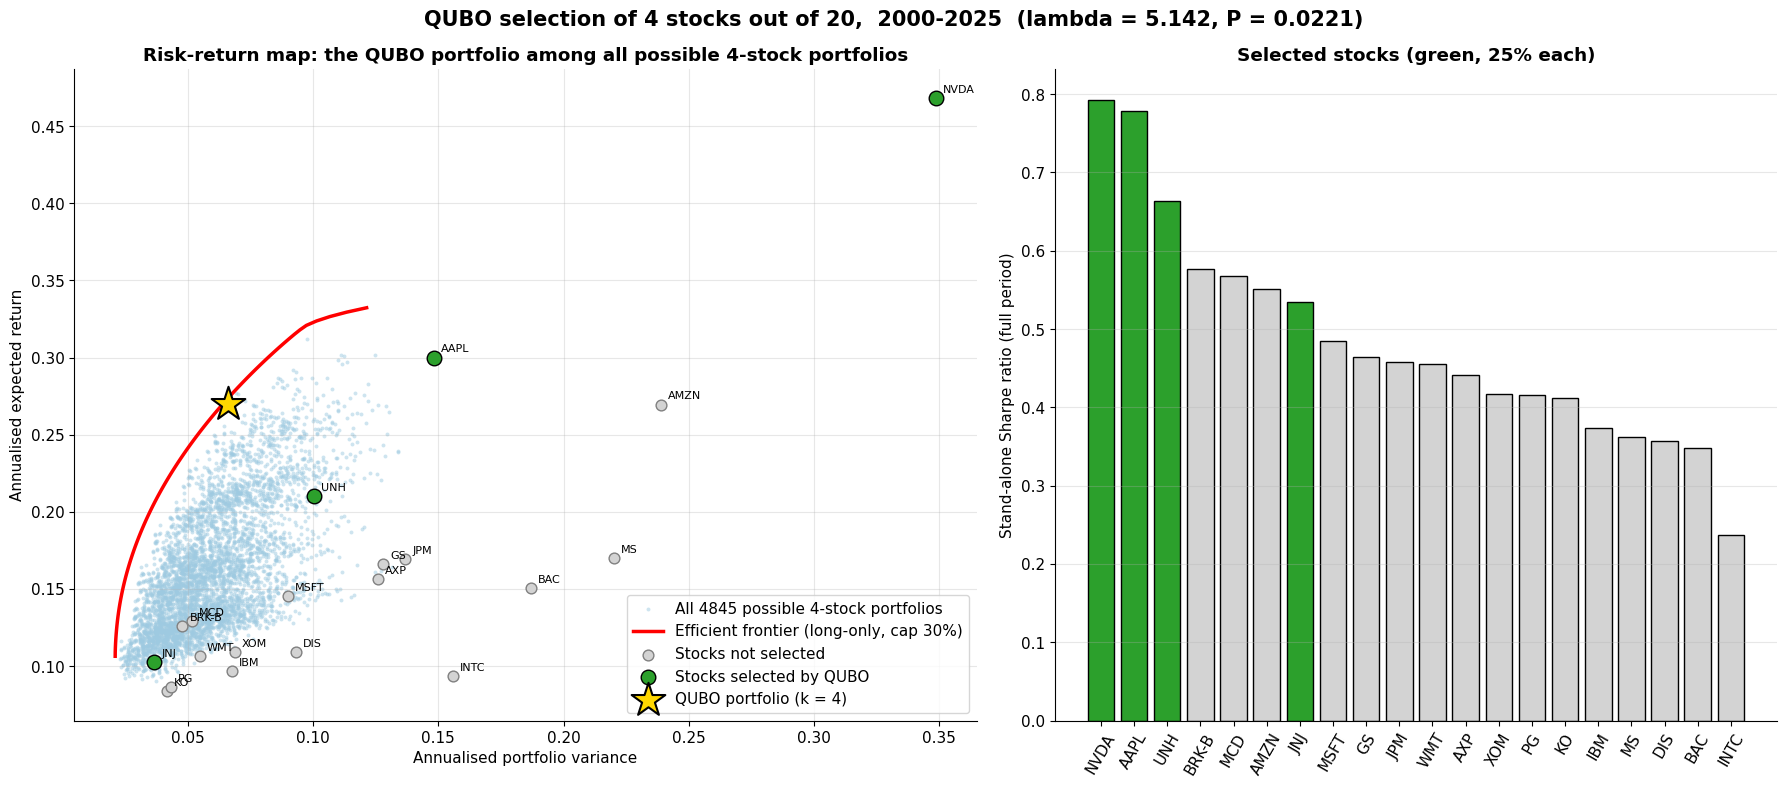

In [7]:
# =============================================================================
# PART 1 | Data collection (your cell 1, unchanged): downloads the 20 stocks with yfinance
#          and writes us_stock_data/adj_close_wide.csv  (needs internet + pip install yfinance)
# =============================================================================
"""
Collect daily price data for 20 US stocks using yfinance.
Period: 2000-01-01 to 2026-01-01

Outputs (in ./us_stock_data):
  - <TICKER>.csv          : per-stock OHLCV data
  - all_stocks_long.csv   : all stocks stacked (Date, Ticker, OHLCV)
  - adj_close_wide.csv    : Date x Ticker matrix of adjusted close prices
  - close_wide.csv        : Date x Ticker matrix of raw close prices
  - download_summary.csv  : rows, first/last date per ticker

Install:  pip install yfinance pandas
"""

import os
import time

import pandas as pd
import yfinance as yf

# ----------------------------------------------------------------------
# Configuration
# ----------------------------------------------------------------------
START_DATE = "2000-01-01"
END_DATE = "2026-01-01"   # yfinance 'end' is exclusive
OUTPUT_DIR = "us_stock_data"
MAX_RETRIES = 3

# Note: Yahoo Finance uses a hyphen for share classes: BRK.B -> BRK-B
# (BRK-A is also available; add it below if you want both share classes.)
STOCKS = {
    "MSFT":  "Microsoft Corporation",
    "AAPL":  "Apple Inc.",
    "NVDA":  "NVIDIA Corporation",
    "AMZN":  "Amazon.com Inc.",
    "INTC":  "Intel Corporation",
    "WMT":   "Walmart Inc.",
    "KO":    "The Coca-Cola Company",
    "DIS":   "The Walt Disney Company",
    "PG":    "The Procter & Gamble Company",
    "IBM":   "International Business Machines",
    "MCD":   "McDonald's Corporation",
    "JPM":   "JPMorgan Chase & Co.",
    "GS":    "The Goldman Sachs Group, Inc.",
    "MS":    "Morgan Stanley",
    "AXP":   "American Express Company",
    "BAC":   "Bank of America Corporation",
    "JNJ":   "Johnson & Johnson",
    "XOM":   "ExxonMobil Corporation",
    "UNH":   "UnitedHealth Group Incorporated",
    "BRK-B": "Berkshire Hathaway Inc. (Class B)",
    # "BRK-A": "Berkshire Hathaway Inc. (Class A)",
}


# ----------------------------------------------------------------------
# Download helper
# ----------------------------------------------------------------------
def download_ticker(ticker: str) -> pd.DataFrame:
    """Download daily OHLCV for one ticker, with retries.

    auto_adjust=False keeps both 'Close' (split-adjusted) and 'Adj Close'
    (split + dividend adjusted).
    """
    for attempt in range(1, MAX_RETRIES + 1):
        try:
            df = yf.download(
                ticker,
                start=START_DATE,
                end=END_DATE,
                interval="1d",
                auto_adjust=False,
                progress=False,
                threads=False,
            )
            if df is not None and not df.empty:
                # Newer yfinance versions return MultiIndex columns
                if isinstance(df.columns, pd.MultiIndex):
                    df.columns = df.columns.get_level_values(0)
                df.index = pd.to_datetime(df.index)
                df.index.name = "Date"
                df = df[["Open", "High", "Low", "Close", "Adj Close", "Volume"]]
                return df.dropna(how="all")
            print(f"  [{ticker}] empty result (attempt {attempt}/{MAX_RETRIES})")
        except Exception as e:
            print(f"  [{ticker}] error: {e} (attempt {attempt}/{MAX_RETRIES})")
        time.sleep(2 * attempt)
    return pd.DataFrame()


# ----------------------------------------------------------------------
# Main
# ----------------------------------------------------------------------
def main():
    os.makedirs(OUTPUT_DIR, exist_ok=True)

    data = {}
    summary = []
    failed = []

    print(f"Downloading {len(STOCKS)} stocks from {START_DATE} to {END_DATE}\n")

    for i, (ticker, name) in enumerate(STOCKS.items(), start=1):
        print(f"[{i:02d}/{len(STOCKS)}] {ticker} - {name}")
        df = download_ticker(ticker)

        if df.empty:
            failed.append(ticker)
            continue

        df.to_csv(os.path.join(OUTPUT_DIR, f"{ticker}.csv"))
        data[ticker] = df
        summary.append(
            {
                "Ticker": ticker,
                "Name": name,
                "Rows": len(df),
                "First_Date": df.index.min().date(),
                "Last_Date": df.index.max().date(),
                "Missing_Close": int(df["Close"].isna().sum()),
            }
        )
        print(f"  -> {len(df)} rows ({df.index.min().date()} to {df.index.max().date()})")
        time.sleep(0.5)  # be polite to Yahoo

    if not data:
        raise SystemExit("No data downloaded. Check your internet connection.")

    # Long format (all stocks stacked)
    long_df = (
        pd.concat(data, names=["Ticker", "Date"])
        .reset_index()
        .sort_values(["Ticker", "Date"])
    )
    long_df.to_csv(os.path.join(OUTPUT_DIR, "all_stocks_long.csv"), index=False)

    # Wide format matrices (Date x Ticker)
    adj_close = pd.DataFrame({t: d["Adj Close"] for t, d in data.items()}).sort_index()
    close = pd.DataFrame({t: d["Close"] for t, d in data.items()}).sort_index()
    adj_close.to_csv(os.path.join(OUTPUT_DIR, "adj_close_wide.csv"))
    close.to_csv(os.path.join(OUTPUT_DIR, "close_wide.csv"))

    # Summary
    summary_df = pd.DataFrame(summary)
    summary_df.to_csv(os.path.join(OUTPUT_DIR, "download_summary.csv"), index=False)

    print("\n" + "=" * 70)
    print(summary_df.to_string(index=False))
    print("=" * 70)
    print(f"Successful: {len(data)}/{len(STOCKS)}")
    if failed:
        print(f"Failed: {failed}")
    print(f"Files saved in: ./{OUTPUT_DIR}/")


if __name__ == "__main__":
    main()

# =============================================================================
# PART 2 | QUBO stock selection with k = 4 on the data collected above
# =============================================================================
# =============================================================================
# SETUP (self-contained): loads the data, computes the full-period mu and Sigma and defines the helper functions.
# Identical to the code of your last cell (CELL 2, CELL 3 and CELL 5 parts); nothing needs to be run before this cell.
# Needs only  us_stock_data/adj_close_wide.csv  (written by your first cell).
# =============================================================================
# Same code as the notebook, as a plain script (run cell 1 first to create the CSV)

# =============================================================================
# CELL 2 | Settings, data and inputs (mu, Sigma) - computed ONCE from the full period
# Uses the adj_close_wide.csv written by cell 1.  Nothing is forecast: every optimiser
# below receives exactly the same table of expected returns and covariances.
# =============================================================================
import os, time, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import TwoSlopeNorm
from scipy.optimize import minimize
from IPython.display import display

warnings.filterwarnings("ignore")
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

# ----------------------------- user settings ---------------------------------
DATA_FILE   = "us_stock_data/adj_close_wide.csv"   # written by cell 1
OUT_DIR     = "qubo_fullperiod_outputs"            # figures and tables are saved here
START, END  = "2000-01-01", "2026-01-01"           # full period used for the single optimisation
TD          = 252                                  # trading days per year
RF          = 0.0                                  # risk-free rate (0 matches your Markowitz chart; 0.02 matches cell 3)
MAX_W       = 0.30                                 # cap per stock (1.0 = plain long-only Markowitz, but annealing then struggles; see notes)
GAMMA       = 4.0                                  # risk aversion in  gamma/2 * w'Sigma w - mu'w
UNITS       = 20                                   # weight grid: 1 unit = 1/UNITS of the portfolio (20 -> 5 %)
K_SELECT    = 8                                    # stocks held by the QUBO "select K" variant
PEN_MULT    = 2.0                                  # penalty strength for the budget / cardinality constraint
SA_CHAINS   = 128                                  # parallel annealing chains
SA_SWEEPS   = 150                                  # sweeps per chain
SEED        = 42
SHRINK_COV  = False                                # True -> Ledoit-Wolf shrinkage of the covariance matrix
X_AXIS      = "variance"                           # "variance" (like your chart) or "volatility"
SHOW_RANDOM = False                                # True -> add random portfolios behind the frontier
QUICK       = False                                # True -> smaller grids in the robustness cell

COLORS = {"EW": "#7f7f7f", "MinVar": "#1f77b4", "MaxSharpe": "#ff7f0e",
          "MeanVar": "#2ca02c", "QUBO-W": "#d62728", "QUBO-S": "#9467bd"}
LABELS = {"EW": "Equal weight (1/N)", "MinVar": "Min-variance", "MaxSharpe": "Max-Sharpe",
          "MeanVar": "Mean-variance (continuous)", "QUBO-W": "QUBO weights", "QUBO-S": "QUBO select-K"}

os.makedirs(OUT_DIR, exist_ok=True)
def savefig(name):
    plt.savefig(f"{OUT_DIR}/{name}.png", dpi=300, bbox_inches="tight")

# ------------------------------- data ----------------------------------------
prices = pd.read_csv(DATA_FILE, index_col="Date", parse_dates=True).sort_index().loc[START:END]
returns = prices.pct_change().iloc[1:]
n_rows = len(returns)
returns = returns.dropna()                          # only days on which every stock traded
tickers = list(returns.columns)
N = len(tickers)

def ledoit_wolf_cov(X):
    """Ledoit-Wolf shrinkage towards a scaled identity (same result as scikit-learn's LedoitWolf)."""
    X = X - X.mean(axis=0)
    T, n = X.shape
    S = X.T @ X / T
    m = np.trace(S) / n
    d2 = np.sum((S - m * np.eye(n)) ** 2)
    b2 = min((np.sum(np.sum(X ** 2, axis=1) ** 2) - T * np.sum(S ** 2)) / T ** 2, d2)
    sh = b2 / d2 if d2 > 0 else 0.0
    return (1 - sh) * S + sh * m * np.eye(n)

mu = returns.mean().to_numpy() * TD                                   # annualised mean return (arithmetic)
Sigma = (ledoit_wolf_cov(returns.to_numpy()) if SHRINK_COV else returns.cov().to_numpy()) * TD
assert np.all(np.linalg.eigvalsh(Sigma) > 0), "covariance matrix is not positive definite"

print(f"{N} stocks | {returns.index[0].date()} to {returns.index[-1].date()} | {len(returns)} daily returns "
      f"({n_rows - len(returns)} rows dropped for missing values)")
print(f"risk-free {RF:.1%} | weight cap {MAX_W:.0%} | gamma {GAMMA:g} | covariance: {'Ledoit-Wolf' if SHRINK_COV else 'sample'}")

def xs(var):
    """x-axis coordinate of a portfolio from its variance."""
    var = np.asarray(var, dtype=float)
    return var if X_AXIS == "variance" else np.sqrt(var)
XLABEL = "Annualised portfolio variance" if X_AXIS == "variance" else "Annualised volatility"


# =============================================================================
# CELL 3 | STEP 1: Classical Markowitz solutions (the reference the QUBO is compared with)
#   EW = equal weight | MinVar = minimum variance | MaxSharpe = tangency portfolio
#   MeanVar = minimise gamma/2 w'Sigma w - mu'w   (exactly the objective the QUBO encodes)
# All are long-only, fully invested, capped at MAX_W.
# =============================================================================
def equal_weight(n):
    return np.full(n, 1.0 / n)

def _slsqp(fun, jac, n, cap, starts):
    cons = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0, "jac": lambda w: np.ones(n)}]
    best = None
    for w0 in starts:
        res = minimize(fun, w0, jac=jac, method="SLSQP", bounds=[(0.0, cap)] * n,
                       constraints=cons, options={"maxiter": 1000, "ftol": 1e-12})
        if res.success and (best is None or res.fun < best.fun):
            best = res
    if best is None:
        return equal_weight(n)
    w = np.clip(best.x, 0.0, cap)
    return w / w.sum()

def min_variance(Sigma, cap):
    n = len(Sigma)
    return _slsqp(lambda w: w @ Sigma @ w, lambda w: 2 * Sigma @ w, n, cap, [equal_weight(n)])

def mean_variance(mu, Sigma, gamma, cap):
    n = len(mu)
    return _slsqp(lambda w: 0.5 * gamma * w @ Sigma @ w - mu @ w, lambda w: gamma * Sigma @ w - mu,
                  n, cap, [equal_weight(n), min_variance(Sigma, cap)])

def max_sharpe(mu, Sigma, cap, rf=RF):
    n = len(mu)
    def fun(w):
        return -(mu @ w - rf) / np.sqrt(w @ Sigma @ w)
    def jac(w):
        s = np.sqrt(w @ Sigma @ w)
        return -(mu / s - (mu @ w - rf) * (Sigma @ w) / s ** 3)
    return _slsqp(fun, jac, n, cap, [equal_weight(n), min_variance(Sigma, cap)])

def mv_objective(w, mu, Sigma, gamma):
    return 0.5 * gamma * w @ Sigma @ w - mu @ w

def port_stats(w, mu=mu, Sigma=Sigma):
    """(expected return, variance, volatility, Sharpe)"""
    ret, var = float(mu @ w), float(w @ Sigma @ w)
    return ret, var, np.sqrt(var), (ret - RF) / np.sqrt(var)

def frontier_points(mu, Sigma, cap, n_pts=80):
    """Long-only efficient frontier. Returns arrays (variance, return)."""
    n = len(mu)
    w_min = min_variance(Sigma, cap)
    order, w_hi, left = np.argsort(-mu), np.zeros(n), 1.0
    for i in order:                                    # highest return reachable under the cap
        take = min(cap, left); w_hi[i] = take; left -= take
        if left <= 1e-12: break
    pts = []
    for tr in np.linspace(mu @ w_min, mu @ w_hi, n_pts)[:-1]:
        cons = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0, "jac": lambda w: np.ones(n)},
                {"type": "eq", "fun": lambda w, tr=tr: mu @ w - tr, "jac": lambda w: mu}]
        res = minimize(lambda w: w @ Sigma @ w, w_min, jac=lambda w: 2 * Sigma @ w, method="SLSQP",
                       bounds=[(0.0, cap)] * n, constraints=cons, options={"maxiter": 1000, "ftol": 1e-12})
        if res.success:
            pts.append((res.fun, tr))
    pts.append((w_hi @ Sigma @ w_hi, mu @ w_hi))
    pts = np.array(pts)
    pts = pts[np.argsort(pts[:, 0])]
    return pts[:, 0], np.maximum.accumulate(pts[:, 1])      # variance ascending, return non-decreasing (efficient part only)

def frontier_return_at(var_target, mu, Sigma, cap, w_start):
    """Highest expected return reachable with variance <= var_target (long-only, capped): the exact frontier height at that risk."""
    n = len(mu)
    cons = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0, "jac": lambda w: np.ones(n)},
            {"type": "ineq", "fun": lambda w: var_target - w @ Sigma @ w, "jac": lambda w: -2 * Sigma @ w}]
    res = minimize(lambda w: -mu @ w, w_start, jac=lambda w: -mu, method="SLSQP", bounds=[(0.0, cap)] * n,
                   constraints=cons, options={"maxiter": 1000, "ftol": 1e-12})
    return float(mu @ res.x) if res.success else np.nan


t0 = time.time()
w_ew = equal_weight(N)
w_minvar = min_variance(Sigma, MAX_W)
w_maxsh = max_sharpe(mu, Sigma, MAX_W)
t_cls = time.time() - t0
t0 = time.time()
w_meanvar = mean_variance(mu, Sigma, GAMMA, MAX_W)
t_meanvar = time.time() - t0
f_var, f_ret = frontier_points(mu, Sigma, MAX_W)

# CELL 5 | STEP 3: QUBO solver - simulated annealing (pure NumPy, no extra packages)
#   simulated_annealing : many parallel chains, single-bit and two-bit flips
#   repair_units        : if a chain ends with a slightly broken budget, add / remove units greedily
#   decode_*            : bits -> weights
#   exact_select        : exhaustive search over all C(N,K) portfolios (exact optimum of QUBO-S)
# =============================================================================
def simulated_annealing(Q, n_chains=128, n_sweeps=150, rng=None, t_hi=None, t_lo=None, t_scale=0.1):
    """Minimise x'Qx over x in {0,1}^n. Returns final states (chains x n), energies (chains), (temperatures, mean energy per sweep).
    Each sweep proposes n single-bit flips and n two-bit flips (the two-bit moves swap one stock / weight unit for another)."""
    rng = rng if rng is not None else np.random.default_rng(SEED)
    Q = 0.5 * (Q + Q.T)
    n = Q.shape[0]
    d = np.diag(Q).copy()
    off = Q - np.diag(d)
    X = rng.integers(0, 2, size=(n_chains, n)).astype(float)
    H = X @ off
    E = np.einsum("ri,ri->r", X @ Q, X)
    if t_hi is None:                                   # start temperature: a fraction of the typical single-flip energy change
        t_hi = t_scale * np.median(np.abs((1 - 2 * X) * (d + 2 * H)))
    if t_lo is None:
        t_lo = t_hi * 1e-4
    temps = np.geomspace(t_hi, t_lo, n_sweeps)
    trace = np.empty(n_sweeps)
    for s, T in enumerate(temps):
        U1 = rng.random((n, n_chains))
        for j, i in enumerate(rng.permutation(n)):                      # single-bit flips
            delta = 1 - 2 * X[:, i]
            dE = delta * (d[i] + 2 * H[:, i])
            acc = (dE <= 0) | (U1[j] < np.exp(-np.maximum(dE, 0) / T))
            if acc.any():
                m = acc * delta
                X[:, i] += m; H += m[:, None] * off[i]; E += acc * dE
        U2 = rng.random((n, n_chains))
        pairs = np.array([rng.choice(n, 2, replace=False) for _ in range(n)])
        for j, (i, k) in enumerate(pairs):                              # two-bit flips
            di, dk = 1 - 2 * X[:, i], 1 - 2 * X[:, k]
            dE = di * (d[i] + 2 * H[:, i]) + dk * (d[k] + 2 * H[:, k]) + 2 * off[i, k] * di * dk
            acc = (dE <= 0) | (U2[j] < np.exp(-np.maximum(dE, 0) / T))
            if acc.any():
                mi, mk = acc * di, acc * dk
                X[:, i] += mi; X[:, k] += mk
                H += mi[:, None] * off[i] + mk[:, None] * off[k]; E += acc * dE
        trace[s] = E.mean()
    return X, np.einsum("ri,ri->r", X @ Q, X), (temps, trace)

def repair_units(u, f, total, cap_u):
    """Greedy repair: add / remove single units until sum(u) == total, always taking the best objective."""
    u = u.copy()
    while u.sum() > total:
        cand = np.flatnonzero(u > 0)
        vals = []
        for i in cand:
            u[i] -= 1; vals.append(f(u)); u[i] += 1
        u[cand[int(np.argmin(vals))]] -= 1
    while u.sum() < total:
        cand = np.flatnonzero(u < cap_u)
        vals = []
        for i in cand:
            u[i] += 1; vals.append(f(u)); u[i] -= 1
        u[cand[int(np.argmin(vals))]] += 1
    return u

def _units_w(X, q):
    return np.rint(X.reshape(len(X), q["n"], q["nb"]) @ q["a"]).astype(int)

def decode_weights(X, E, q, mu, Sigma, gamma, top=10):
    """Best QUBO-W portfolio among the `top` lowest-energy chains (after repair). Returns weights, info."""
    U = q["units"]
    f = lambda uu: mv_objective(uu / U, mu, Sigma, gamma)
    units_all = _units_w(X, q)
    best_u, best_f = None, np.inf
    for r in np.argsort(E)[:top]:
        u = repair_units(units_all[r], f, U, q["cap_u"])
        if f(u) < best_f:
            best_u, best_f = u, f(u)
    return best_u / U, dict(feasible_rate=float((units_all.sum(axis=1) == U).mean()), units=best_u)

def decode_select(X, E, q, mu, Sigma, gamma, top=10):
    k = q["k"]
    f = lambda uu: mv_objective(uu / k, mu, Sigma, gamma)
    best_u, best_f = None, np.inf
    for r in np.argsort(E)[:top]:
        u = repair_units(X[r].astype(int), f, k, 1)
        if f(u) < best_f:
            best_u, best_f = u, f(u)
    return best_u / k, dict(feasible_rate=float((X.sum(axis=1) == k).mean()), units=best_u)

def chain_objectives_w(X, q, mu, Sigma, gamma):
    """Objective of every chain's portfolio after repair (for the distribution plots)."""
    U = q["units"]
    f = lambda uu: mv_objective(uu / U, mu, Sigma, gamma)
    return np.array([f(repair_units(u, f, U, q["cap_u"])) for u in _units_w(X, q)])

def chain_objectives_s(X, q, mu, Sigma, gamma):
    k = q["k"]
    f = lambda uu: mv_objective(uu / k, mu, Sigma, gamma)
    return np.array([f(repair_units(z.astype(int), f, k, 1)) for z in X])

def exact_select(mu, Sigma, gamma, k, chunk=40000):
    """Exhaustive search over all C(N,k) equal-weight portfolios. Returns (best index set, best objective)."""
    n = len(mu)
    best_f, best_c = np.inf, None
    it = itertools.combinations(range(n), k)
    while True:
        block = list(itertools.islice(it, chunk))
        if not block:
            break
        c = np.array(block)
        var = Sigma[c[:, :, None], c[:, None, :]].sum(axis=(1, 2)) / k ** 2
        f = 0.5 * gamma * var - mu[c].sum(axis=1) / k
        j = int(np.argmin(f))
        if f[j] < best_f:
            best_f, best_c = float(f[j]), c[j]
    return best_c, best_f


# =============================================================================
# QUBO STOCK SELECTION WITH k = 4  |  best 4 of the 20 stocks for return versus risk
# (self-contained after Part 1: needs us_stock_data/adj_close_wide.csv written by the download code above)
#
# x_i = 1 if stock i is chosen; the 4 chosen stocks get equal weight 1/4.
#     H(x) = lambda/2 * (x'Sigma x)/k^2  -  (mu'x)/k  +  P * (sum(x) - k)^2 ,   k = 4        (QUBO: x'Qx + const)
#   mu, Sigma : full-period 2000-2025 annualised mean return and covariance (no train/test split, no backtest)
#   lambda    : risk aversion for which the continuous mean-variance optimum is the max-Sharpe portfolio
#               (lambda = (R_t - RF)/sigma_t^2, from mu and Sigma only)
#   P         : penalty from the Monte Carlo estimate (Algorithm 1 of the paper, Eq. 8), largest estimate of all runs
#   solver    : simulated annealing on the QUBO, checked against exhaustive search over all C(20,4) = 4845 subsets
# =============================================================================
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations

K = 4
MC_N, MC_RUNS, MC_SEED = 5000, 200, SEED + 7

# ------------------------------ lambda ---------------------------------------------
r_t, v_t, _, sh_t = port_stats(w_maxsh)
LAMBDA = (r_t - RF) / v_t
w_chk = mean_variance(mu, Sigma, LAMBDA, MAX_W)
print(f"lambda = (R_t - RF) / var_t = ({r_t:.4f} - {RF:.4f}) / {v_t:.5f} = {LAMBDA:.4f}   "
      f"(check vs max-Sharpe portfolio: max |weight difference| = {np.abs(w_chk - w_maxsh).max():.1e})")

# ------------------------------ Monte Carlo penalty for k = 4 ----------------------------
def mc_binary_samples(n, m, rng):
    card = rng.integers(0, n + 1, size=m)
    rank = np.argsort(np.argsort(rng.random((m, n)), axis=1), axis=1)
    return (rank < card[:, None]).astype(float)

def penalty_lower_bound(q, lin, s, k, lam):
    f = 0.5 * lam / k ** 2 * q - lin / k
    viol = (s - k) ** 2
    v_min = viol.min()
    f_from = f[viol == v_min].min()
    m = (f < f_from) & (viol > v_min)
    if not m.any():
        return 0.0
    return ((f_from - f[m]) / (viol[m] - v_min)).max()

rng_mc = np.random.default_rng(MC_SEED)
mc_p = np.zeros(MC_RUNS)
for run in range(MC_RUNS):
    Xs = mc_binary_samples(N, MC_N, rng_mc)
    mc_p[run] = penalty_lower_bound(np.einsum("ri,ij,rj->r", Xs, Sigma, Xs), Xs @ mu, Xs.sum(axis=1), K, LAMBDA)
P = mc_p.max()
print(f"penalty P for k = {K}: Monte Carlo estimates over {MC_RUNS} runs -> mean {mc_p.mean():.5f}, "
      f"median {np.median(mc_p):.5f}, max (used) {P:.5f}")

# ------------------------------ QUBO for k = 4 and its solution ------------------------
Q = 0.5 * LAMBDA / K ** 2 * Sigma - np.diag(mu / K) + P * (np.ones((N, N)) - 2 * K * np.eye(N))
q = dict(Q=Q, const=P * K ** 2, n=N, k=K, P=P)
t0 = time.time()
X, E, _ = simulated_annealing(Q, SA_CHAINS, SA_SWEEPS, rng=np.random.default_rng(SEED + 1000 + K))
w_star, info = decode_select(X, E, q, mu, Sigma, LAMBDA)
z = (w_star > 0).astype(float)
assert z.sum() == K and np.isclose(z @ Q @ z + q["const"], mv_objective(w_star, mu, Sigma, LAMBDA))
sel_ex, f_ex = exact_select(mu, Sigma, LAMBDA, K)
f_sa = mv_objective(w_star, mu, Sigma, LAMBDA)
chain_f = chain_objectives_s(X, q, mu, Sigma, LAMBDA)
sel = np.flatnonzero(w_star)
print(f"QUBO solved in {time.time() - t0:.1f} s  |  annealing chains feasible: {info['feasible_rate'] * 100:.1f}%  |  "
      f"chains at the exact optimum: {np.mean(chain_f <= f_ex + 1e-10) * 100:.1f}%")
print(f"QUBO (annealing) objective {f_sa:.6f}  |  exact objective {f_ex:.6f}  |  "
      f"same stocks as exact search: {set(sel) == set(sel_ex)}\n")

# ------------------------------ result ---------------------------------------------------
print("=" * 78)
print(f"QUBO RESULT (k = {K}): " + ", ".join(tickers[i] for i in sel) + f"   -> {100 / K:.0f}% each")
print("=" * 78)
stock_tab = pd.DataFrame({"Annualised return (%)": mu * 100, "Volatility (%)": np.sqrt(np.diag(Sigma)) * 100,
                          "Weight (%)": w_star * 100}, index=tickers)
stock_tab["Sharpe (stand-alone)"] = (mu - RF) / np.sqrt(np.diag(Sigma))
stock_tab["Selected"] = np.where(w_star > 0, "YES", "-")
display(stock_tab.sort_values(["Selected", "Weight (%)"], ascending=[False, False]).round(3))

cmp_rows = {}
for name, w_ in [(f"QUBO selection (k = {K})", w_star), ("Equal weight, all 20 stocks", w_ew),
                 ("Markowitz max-Sharpe", w_maxsh), ("Markowitz min-variance", w_minvar)]:
    r_, v_, s_, h_ = port_stats(w_)
    cmp_rows[name] = {"Exp. return (%)": r_ * 100, "Variance": v_, "Volatility (%)": s_ * 100, "Sharpe": h_,
                      "Objective": mv_objective(w_, mu, Sigma, LAMBDA), "No. of stocks": int((w_ > 1e-6).sum())}
CMP = pd.DataFrame(cmp_rows).T
print("\nFull-period risk / return (same mu and Sigma for every row):")
display(CMP.round(4))
print("Correlation between the 4 selected stocks (full period):")
display(pd.DataFrame(Sigma[np.ix_(sel, sel)] / np.sqrt(np.outer(np.diag(Sigma)[sel], np.diag(Sigma)[sel])),
                     index=[tickers[i] for i in sel], columns=[tickers[i] for i in sel]).round(3))
CMP.to_csv(f"{OUT_DIR}/qubo_k4_comparison.csv"); stock_tab.to_csv(f"{OUT_DIR}/qubo_k4_stocks.csv")

# ------------------------------ charts ---------------------------------------------------
allc = np.array(list(combinations(range(N), K)))                       # all 4845 four-stock portfolios (equal weight)
rc = mu[allc].mean(axis=1)
vc = Sigma[allc[:, :, None], allc[:, None, :]].sum(axis=(1, 2)) / K ** 2
sig2 = np.diag(Sigma)
fig, axes = plt.subplots(1, 2, figsize=(18, 8), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
ax.scatter(xs(vc), rc, s=8, color="#9ecae1", alpha=0.5, linewidths=0, label=f"All {len(allc)} possible {K}-stock portfolios", zorder=1)
ax.plot(xs(f_var), f_ret, color="red", lw=2.5, label=f"Efficient frontier (long-only, cap {MAX_W:.0%})", zorder=2)
ax.scatter(xs(sig2[w_star == 0]), mu[w_star == 0], s=60, color="lightgrey", edgecolor="grey", label="Stocks not selected", zorder=3)
ax.scatter(xs(sig2[sel]), mu[sel], s=110, color="#2ca02c", edgecolor="black", label="Stocks selected by QUBO", zorder=4)
for i, t in enumerate(tickers):
    ax.annotate(t, (xs(sig2[i]), mu[i]), xytext=(5, 4), textcoords="offset points", fontsize=8)
rs, vs_, _, _ = port_stats(w_star)
ax.scatter(xs(vs_), rs, marker="*", s=650, color="gold", edgecolor="black", linewidths=1.5, zorder=6, label=f"QUBO portfolio (k = {K})")
ax.set_xlabel(XLABEL); ax.set_ylabel("Annualised expected return"); ax.grid(True, alpha=0.3); ax.legend(loc="lower right")
ax.set_title("Risk-return map: the QUBO portfolio among all possible 4-stock portfolios", fontweight="bold")

ax = axes[1]
order = np.argsort(-(mu - RF) / np.sqrt(sig2))
ax.bar([tickers[i] for i in order], ((mu - RF) / np.sqrt(sig2))[order],
       color=["#2ca02c" if w_star[i] > 0 else "lightgrey" for i in order], edgecolor="black")
ax.set_ylabel("Stand-alone Sharpe ratio (full period)"); ax.grid(True, axis="y", alpha=0.3)
ax.set_title(f"Selected stocks (green, {100 / K:.0f}% each)", fontweight="bold"); ax.tick_params(axis="x", rotation=60)
fig.suptitle(f"QUBO selection of {K} stocks out of {N},  {returns.index[0].year}-{returns.index[-1].year}  (lambda = {LAMBDA:.3f}, P = {P:.4f})",
             fontsize=15, fontweight="bold")
plt.tight_layout(); savefig("qubo_k4_selection"); plt.show()


[01/20] MSFT - Microsoft Corporation
  -> 6539 rows (2000-01-03 to 2025-12-31)
[02/20] AAPL - Apple Inc.
  -> 6539 rows (2000-01-03 to 2025-12-31)
[03/20] NVDA - NVIDIA Corporation
  -> 6539 rows (2000-01-03 to 2025-12-31)
[04/20] AMZN - Amazon.com Inc.
  -> 6539 rows (2000-01-03 to 2025-12-31)
[05/20] INTC - Intel Corporation
  -> 6539 rows (2000-01-03 to 2025-12-31)
[06/20] WMT - Walmart Inc.
  -> 6539 rows (2000-01-03 to 2025-12-31)
[07/20] KO - The Coca-Cola Company
  -> 6539 rows (2000-01-03 to 2025-12-31)
[08/20] DIS - The Walt Disney Company
  -> 6539 rows (2000-01-03 to 2025-12-31)
[09/20] PG - The Procter & Gamble Company
  -> 6539 rows (2000-01-03 to 2025-12-31)
[10/20] IBM - International Business Machines
  -> 6539 rows (2000-01-03 to 2025-12-31)
[11/20] MCD - McDonald's Corporation
  -> 6539 rows (2000-01-03 to 2025-12-31)
[12/20] JPM - JPMorgan Chase & Co.
  -> 6539 rows (2000-01-03 to 2025-12-31)
[13/20] GS - The Goldman Sachs Group, Inc.
  -> 6539 rows (2000-01-03 to 2

,Annualised return (%),Volatility (%),MIQP weight (%),Selected (z=1)
JNJ,10.237,19.136,34.850,YES
UNH,21.017,31.700,25.247,YES
AAPL,30.003,38.516,22.455,YES
NVDA,46.799,59.047,17.448,YES



Full-period risk / return (same mu, Sigma and lambda for every row):


,Exp. return (%),Variance,Volatility (%),Sharpe,Objective,No. of stocks
"MIQP (k = 4, optimal weights)",23.7763,0.0509,22.5704,1.0534,-0.1068,4.0
"QUBO-type equal weight (k = 4, exact optimum)",27.0140,0.0660,25.6998,1.0511,-0.1003,4.0
"Equal weight, all 20 stocks",16.2444,0.0441,21.0050,0.7734,-0.0490,20.0
Markowitz max-Sharpe,22.7163,0.0442,21.0181,1.0808,-0.1136,9.0
Markowitz min-variance,10.6308,0.0210,14.4868,0.7338,-0.0523,10.0


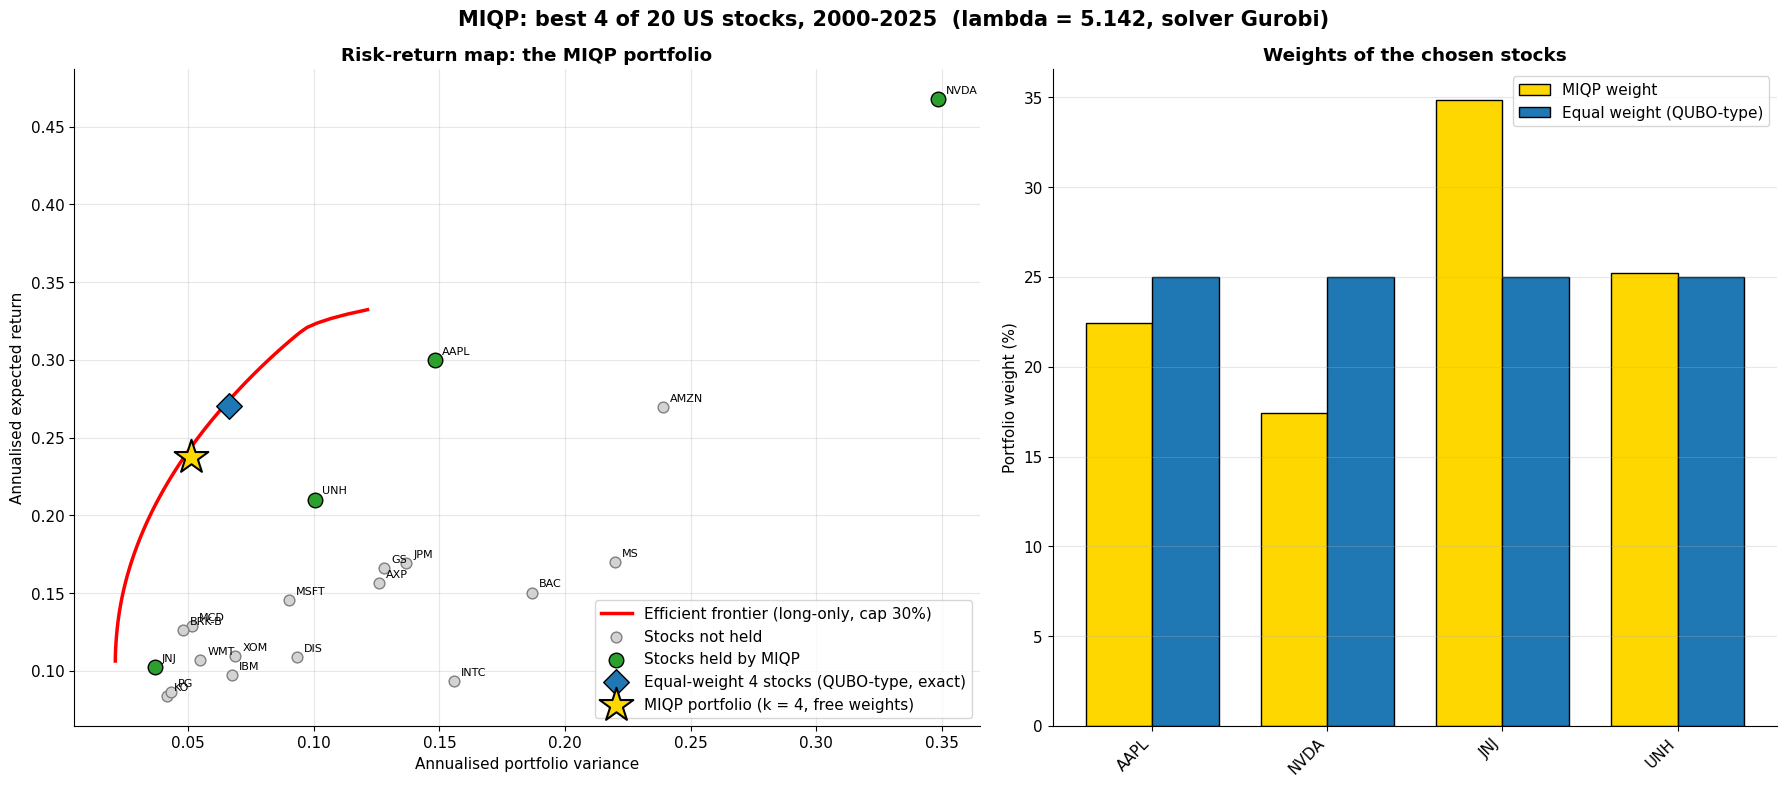

In [ ]:
"""
Collect daily price data for 20 US stocks using yfinance.
Period: 2000-01-01 to 2026-01-01

Outputs (in ./us_stock_data):
  - <TICKER>.csv          : per-stock OHLCV data
  - all_stocks_long.csv   : all stocks stacked (Date, Ticker, OHLCV)
  - adj_close_wide.csv    : Date x Ticker matrix of adjusted close prices
  - close_wide.csv        : Date x Ticker matrix of raw close prices
  - download_summary.csv  : rows, first/last date per ticker

Install:  pip install yfinance pandas
"""

import os
import time

import pandas as pd
import yfinance as yf


# Configuration

START_DATE = "2000-01-01"
END_DATE = "2026-01-01"   # yfinance 'end' is exclusive
OUTPUT_DIR = "us_stock_data"
MAX_RETRIES = 3

# Note: Yahoo Finance uses a hyphen for share classes: BRK.B -> BRK-B
# (BRK-A is also available; add it below if you want both share classes.)
STOCKS = {
    "MSFT":  "Microsoft Corporation",
    "AAPL":  "Apple Inc.",
    "NVDA":  "NVIDIA Corporation",
    "AMZN":  "Amazon.com Inc.",
    "INTC":  "Intel Corporation",
    "WMT":   "Walmart Inc.",
    "KO":    "The Coca-Cola Company",
    "DIS":   "The Walt Disney Company",
    "PG":    "The Procter & Gamble Company",
    "IBM":   "International Business Machines",
    "MCD":   "McDonald's Corporation",
    "JPM":   "JPMorgan Chase & Co.",
    "GS":    "The Goldman Sachs Group, Inc.",
    "MS":    "Morgan Stanley",
    "AXP":   "American Express Company",
    "BAC":   "Bank of America Corporation",
    "JNJ":   "Johnson & Johnson",
    "XOM":   "ExxonMobil Corporation",
    "UNH":   "UnitedHealth Group Incorporated",
    "BRK-B": "Berkshire Hathaway Inc. (Class B)",
    # "BRK-A": "Berkshire Hathaway Inc. (Class A)",
}



# Download helper

def download_ticker(ticker: str) -> pd.DataFrame:
    """Download daily OHLCV for one ticker, with retries.

    auto_adjust=False keeps both 'Close' (split-adjusted) and 'Adj Close'
    (split + dividend adjusted).
    """
    for attempt in range(1, MAX_RETRIES + 1):
        try:
            df = yf.download(
                ticker,
                start=START_DATE,
                end=END_DATE,
                interval="1d",
                auto_adjust=False,
                progress=False,
                threads=False,
            )
            if df is not None and not df.empty:
                # Newer yfinance versions return MultiIndex columns
                if isinstance(df.columns, pd.MultiIndex):
                    df.columns = df.columns.get_level_values(0)
                df.index = pd.to_datetime(df.index)
                df.index.name = "Date"
                df = df[["Open", "High", "Low", "Close", "Adj Close", "Volume"]]
                return df.dropna(how="all")
            print(f"  [{ticker}] empty result (attempt {attempt}/{MAX_RETRIES})")
        except Exception as e:
            print(f"  [{ticker}] error: {e} (attempt {attempt}/{MAX_RETRIES})")
        time.sleep(2 * attempt)
    return pd.DataFrame()



# Main

def main():
    os.makedirs(OUTPUT_DIR, exist_ok=True)

    data = {}
    summary = []
    failed = []

    print(f"Downloading {len(STOCKS)} stocks from {START_DATE} to {END_DATE}\n")

    for i, (ticker, name) in enumerate(STOCKS.items(), start=1):
        print(f"[{i:02d}/{len(STOCKS)}] {ticker} - {name}")
        df = download_ticker(ticker)

        if df.empty:
            failed.append(ticker)
            continue

        df.to_csv(os.path.join(OUTPUT_DIR, f"{ticker}.csv"))
        data[ticker] = df
        summary.append(
            {
                "Ticker": ticker,
                "Name": name,
                "Rows": len(df),
                "First_Date": df.index.min().date(),
                "Last_Date": df.index.max().date(),
                "Missing_Close": int(df["Close"].isna().sum()),
            }
        )
        print(f"  -> {len(df)} rows ({df.index.min().date()} to {df.index.max().date()})")
        time.sleep(0.5)  # be polite to Yahoo

    if not data:
        raise SystemExit("No data downloaded. Check your internet connection.")

    # Long format (all stocks stacked)
    long_df = (
        pd.concat(data, names=["Ticker", "Date"])
        .reset_index()
        .sort_values(["Ticker", "Date"])
    )
    long_df.to_csv(os.path.join(OUTPUT_DIR, "all_stocks_long.csv"), index=False)

    # Wide format matrices (Date x Ticker)
    adj_close = pd.DataFrame({t: d["Adj Close"] for t, d in data.items()}).sort_index()
    close = pd.DataFrame({t: d["Close"] for t, d in data.items()}).sort_index()
    adj_close.to_csv(os.path.join(OUTPUT_DIR, "adj_close_wide.csv"))
    close.to_csv(os.path.join(OUTPUT_DIR, "close_wide.csv"))

    # Summary
    summary_df = pd.DataFrame(summary)
    summary_df.to_csv(os.path.join(OUTPUT_DIR, "download_summary.csv"), index=False)

    print("\n" + "=" * 70)
    print(summary_df.to_string(index=False))
    print("=" * 70)
    print(f"Successful: {len(data)}/{len(STOCKS)}")
    if failed:
        print(f"Failed: {failed}")
    print(f"Files saved in: ./{OUTPUT_DIR}/")


if __name__ == "__main__":
    main()


# PART 2 | MIQP on the data collected above

# SETUP (self-contained): loads the data, computes the full-period mu and Sigma and defines the helper functions.
# Identical to the code of your last cell (data / Markowitz helper parts); needs us_stock_data/adj_close_wide.csv.

# Same code as the notebook, as a plain script (run cell 1 first to create the CSV)


# CELL 2 | Settings, data and inputs (mu, Sigma) - computed ONCE from the full period
# Uses the adj_close_wide.csv written by cell 1.  Nothing is forecast: every optimiser
# below receives exactly the same table of expected returns and covariances.

import os, time, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import TwoSlopeNorm
from scipy.optimize import minimize
from IPython.display import display

warnings.filterwarnings("ignore")
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

# settings 
DATA_FILE   = "us_stock_data/adj_close_wide.csv"   # written by cell 1
OUT_DIR     = "qubo_fullperiod_outputs"            # figures and tables are saved here
START, END  = "2000-01-01", "2026-01-01"           # full period used for the single optimisation
TD          = 252                                  # trading days per year
RF          = 0.0                                  # risk-free rate (0 matches your Markowitz chart; 0.02 matches cell 3)
MAX_W       = 0.30                                 # cap per stock (1.0 = plain long-only Markowitz, but annealing then struggles; see notes)
GAMMA       = 4.0                                  # risk aversion in  gamma/2 * w'Sigma w - mu'w
UNITS       = 20                                   # weight grid: 1 unit = 1/UNITS of the portfolio (20 -> 5 %)
K_SELECT    = 8                                    # stocks held by the QUBO "select K" variant
PEN_MULT    = 2.0                                  # penalty strength for the budget / cardinality constraint
SA_CHAINS   = 128                                  # parallel annealing chains
SA_SWEEPS   = 150                                  # sweeps per chain
SEED        = 42
SHRINK_COV  = False                                # True -> Ledoit-Wolf shrinkage of the covariance matrix
X_AXIS      = "variance"                           # "variance" (like your chart) or "volatility"
SHOW_RANDOM = False                                # True -> add random portfolios behind the frontier
QUICK       = False                                # True -> smaller grids in the robustness cell

COLORS = {"EW": "#7f7f7f", "MinVar": "#1f77b4", "MaxSharpe": "#ff7f0e",
          "MeanVar": "#2ca02c", "QUBO-W": "#d62728", "QUBO-S": "#9467bd"}
LABELS = {"EW": "Equal weight (1/N)", "MinVar": "Min-variance", "MaxSharpe": "Max-Sharpe",
          "MeanVar": "Mean-variance (continuous)", "QUBO-W": "QUBO weights", "QUBO-S": "QUBO select-K"}

os.makedirs(OUT_DIR, exist_ok=True)
def savefig(name):
    plt.savefig(f"{OUT_DIR}/{name}.png", dpi=300, bbox_inches="tight")


prices = pd.read_csv(DATA_FILE, index_col="Date", parse_dates=True).sort_index().loc[START:END]
returns = prices.pct_change().iloc[1:]
n_rows = len(returns)
returns = returns.dropna()                          # only days on which every stock traded
tickers = list(returns.columns)
N = len(tickers)

def ledoit_wolf_cov(X):
    """Ledoit-Wolf shrinkage towards a scaled identity (same result as scikit-learn's LedoitWolf)."""
    X = X - X.mean(axis=0)
    T, n = X.shape
    S = X.T @ X / T
    m = np.trace(S) / n
    d2 = np.sum((S - m * np.eye(n)) ** 2)
    b2 = min((np.sum(np.sum(X ** 2, axis=1) ** 2) - T * np.sum(S ** 2)) / T ** 2, d2)
    sh = b2 / d2 if d2 > 0 else 0.0
    return (1 - sh) * S + sh * m * np.eye(n)

mu = returns.mean().to_numpy() * TD                                   # annualised mean return (arithmetic)
Sigma = (ledoit_wolf_cov(returns.to_numpy()) if SHRINK_COV else returns.cov().to_numpy()) * TD
assert np.all(np.linalg.eigvalsh(Sigma) > 0), "covariance matrix is not positive definite"

print(f"{N} stocks | {returns.index[0].date()} to {returns.index[-1].date()} | {len(returns)} daily returns "
      f"({n_rows - len(returns)} rows dropped for missing values)")
print(f"risk-free {RF:.1%} | weight cap {MAX_W:.0%} | gamma {GAMMA:g} | covariance: {'Ledoit-Wolf' if SHRINK_COV else 'sample'}")

def xs(var):
    """x-axis coordinate of a portfolio from its variance."""
    var = np.asarray(var, dtype=float)
    return var if X_AXIS == "variance" else np.sqrt(var)
XLABEL = "Annualised portfolio variance" if X_AXIS == "variance" else "Annualised volatility"



# CELL 3 | STEP 1: Classical Markowitz solutions (the reference the QUBO is compared with)
#   EW = equal weight | MinVar = minimum variance | MaxSharpe = tangency portfolio
#   MeanVar = minimise gamma/2 w'Sigma w - mu'w   (exactly the objective the QUBO encodes)
# All are long-only, fully invested, capped at MAX_W.

def equal_weight(n):
    return np.full(n, 1.0 / n)

def _slsqp(fun, jac, n, cap, starts):
    cons = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0, "jac": lambda w: np.ones(n)}]
    best = None
    for w0 in starts:
        res = minimize(fun, w0, jac=jac, method="SLSQP", bounds=[(0.0, cap)] * n,
                       constraints=cons, options={"maxiter": 1000, "ftol": 1e-12})
        if res.success and (best is None or res.fun < best.fun):
            best = res
    if best is None:
        return equal_weight(n)
    w = np.clip(best.x, 0.0, cap)
    return w / w.sum()

def min_variance(Sigma, cap):
    n = len(Sigma)
    return _slsqp(lambda w: w @ Sigma @ w, lambda w: 2 * Sigma @ w, n, cap, [equal_weight(n)])

def mean_variance(mu, Sigma, gamma, cap):
    n = len(mu)
    return _slsqp(lambda w: 0.5 * gamma * w @ Sigma @ w - mu @ w, lambda w: gamma * Sigma @ w - mu,
                  n, cap, [equal_weight(n), min_variance(Sigma, cap)])

def max_sharpe(mu, Sigma, cap, rf=RF):
    n = len(mu)
    def fun(w):
        return -(mu @ w - rf) / np.sqrt(w @ Sigma @ w)
    def jac(w):
        s = np.sqrt(w @ Sigma @ w)
        return -(mu / s - (mu @ w - rf) * (Sigma @ w) / s ** 3)
    return _slsqp(fun, jac, n, cap, [equal_weight(n), min_variance(Sigma, cap)])

def mv_objective(w, mu, Sigma, gamma):
    return 0.5 * gamma * w @ Sigma @ w - mu @ w

def port_stats(w, mu=mu, Sigma=Sigma):
    """(expected return, variance, volatility, Sharpe)"""
    ret, var = float(mu @ w), float(w @ Sigma @ w)
    return ret, var, np.sqrt(var), (ret - RF) / np.sqrt(var)

def frontier_points(mu, Sigma, cap, n_pts=80):
    """Long-only efficient frontier. Returns arrays (variance, return)."""
    n = len(mu)
    w_min = min_variance(Sigma, cap)
    order, w_hi, left = np.argsort(-mu), np.zeros(n), 1.0
    for i in order:                                    # highest return reachable under the cap
        take = min(cap, left); w_hi[i] = take; left -= take
        if left <= 1e-12: break
    pts = []
    for tr in np.linspace(mu @ w_min, mu @ w_hi, n_pts)[:-1]:
        cons = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0, "jac": lambda w: np.ones(n)},
                {"type": "eq", "fun": lambda w, tr=tr: mu @ w - tr, "jac": lambda w: mu}]
        res = minimize(lambda w: w @ Sigma @ w, w_min, jac=lambda w: 2 * Sigma @ w, method="SLSQP",
                       bounds=[(0.0, cap)] * n, constraints=cons, options={"maxiter": 1000, "ftol": 1e-12})
        if res.success:
            pts.append((res.fun, tr))
    pts.append((w_hi @ Sigma @ w_hi, mu @ w_hi))
    pts = np.array(pts)
    pts = pts[np.argsort(pts[:, 0])]
    return pts[:, 0], np.maximum.accumulate(pts[:, 1])      # variance ascending, return non-decreasing (efficient part only)

def frontier_return_at(var_target, mu, Sigma, cap, w_start):
    """Highest expected return reachable with variance <= var_target (long-only, capped): the exact frontier height at that risk."""
    n = len(mu)
    cons = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0, "jac": lambda w: np.ones(n)},
            {"type": "ineq", "fun": lambda w: var_target - w @ Sigma @ w, "jac": lambda w: -2 * Sigma @ w}]
    res = minimize(lambda w: -mu @ w, w_start, jac=lambda w: -mu, method="SLSQP", bounds=[(0.0, cap)] * n,
                   constraints=cons, options={"maxiter": 1000, "ftol": 1e-12})
    return float(mu @ res.x) if res.success else np.nan


t0 = time.time()
w_ew = equal_weight(N)
w_minvar = min_variance(Sigma, MAX_W)
w_maxsh = max_sharpe(mu, Sigma, MAX_W)
t_cls = time.time() - t0
t0 = time.time()
w_meanvar = mean_variance(mu, Sigma, GAMMA, MAX_W)
t_meanvar = time.time() - t0
f_var, f_ret = frontier_points(mu, Sigma, MAX_W)


# MIQP  (Mixed-Integer Quadratic Programming) for the k-stock Markowitz problem
#
#     minimise    lambda/2 * w'Sigma w  -  mu'w
#     subject to  sum(w) = 1 ,   sum(z) = k ,   0 <= w_i <= z_i ,   z_i in {0,1}
#
#   z_i = 1  : stock i may be held        w_i : continuous portfolio weight (not forced to be equal)
#   mu, Sigma : full-period 2000-2025 annualised mean return / covariance (no train/test split, no backtest)
#   lambda    : the same risk aversion as in the QUBO code: the value for which the continuous mean-variance optimum is the
#               max-Sharpe portfolio,  lambda = (R_t - RF)/sigma_t^2  (from mu and Sigma only)
#   solver    : exact branch-and-bound by a MIQP solver (Gurobi or SCIP); the result is verified by solving the
#               convex QP of every possible k-stock subset (exhaustive check).
# Needs:  gurobipy (Gurobi; the pip licence is large enough) and/or pyscipopt (SCIP, free). Missing packages are installed automatically
#         into the Python that runs the notebook. No cvxpy needed.

import time
from math import comb
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

K        = 4            # number of stocks held (cardinality)
W_MIN    = 0.0          # 0 -> exactly your model (0 <= w_i <= z_i). Set e.g. 0.05 to force every chosen stock to weigh >= 5%
ENUM_CHECK = comb(N, K) <= 6000      # exhaustive verification of the MIQP answer (4845 subsets for k = 4)

# ------------------------------ lambda ---------------------------------------------
r_t, v_t, _, sh_t = port_stats(w_maxsh)
LAMBDA = (r_t - RF) / v_t
w_chk = mean_variance(mu, Sigma, LAMBDA, MAX_W)
print(f"lambda = (R_t - RF) / var_t = ({r_t:.4f} - {RF:.4f}) / {v_t:.5f} = {LAMBDA:.4f}   "
      f"(check vs max-Sharpe portfolio: max |weight difference| = {np.abs(w_chk - w_maxsh).max():.1e})")
obj = lambda w: 0.5 * LAMBDA * float(w @ Sigma @ w) - float(mu @ w)

# ------------------------------ MIQP model ---------------------------------------------
import sys, subprocess, importlib

def _ensure(module, pip_name):
    """import a package; if it is missing, install it into the Python that runs THIS notebook, then import it."""
    try:
        return importlib.import_module(module)
    except ImportError:
        print(f"'{module}' not found in {sys.executable} -> installing '{pip_name}' ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])
        importlib.invalidate_caches()
        return importlib.import_module(module)

ev, V = np.linalg.eigh(Sigma)
Sigma_psd = (V * np.clip(ev, 0, None)) @ V.T                    # Sigma without tiny negative rounding eigenvalues (convex objective)

def solve_gurobi():
    gp = _ensure("gurobipy", "gurobipy")
    from gurobipy import GRB
    m = gp.Model("miqp_k_stocks"); m.Params.OutputFlag = 0; m.Params.MIPGap = 1e-9; m.Params.MIPGapAbs = 1e-12
    w = m.addMVar(N, lb=0.0, ub=1.0, name="w"); z = m.addMVar(N, vtype=GRB.BINARY, name="z")
    m.setObjective(0.5 * LAMBDA * (w @ Sigma_psd @ w) - mu @ w, GRB.MINIMIZE)
    m.addConstr(w.sum() == 1); m.addConstr(z.sum() == K); m.addConstr(w <= z); m.addConstr(w >= W_MIN * z)
    m.optimize()
    if m.SolCount == 0:
        raise RuntimeError(f"Gurobi status {m.Status}")
    return w.X.copy(), z.X.copy(), f"status {m.Status} (2 = optimal), MIP gap {m.MIPGap:.1e}"

def solve_scip():
    sc = _ensure("pyscipopt", "pyscipopt")
    m = sc.Model("miqp_k_stocks"); m.hideOutput(); m.setParam("limits/gap", 0.0); m.setParam("limits/absgap", 0.0)
    w = [m.addVar(lb=0.0, ub=1.0, name=f"w{i}") for i in range(N)]
    z = [m.addVar(vtype="B", name=f"z{i}") for i in range(N)]
    t = m.addVar(lb=None, name="t")                                 # epigraph variable: t >= lambda/2 w'Sigma w - mu'w
    m.setObjective(t, "minimize")
    m.addCons(t >= 0.5 * LAMBDA * sc.quicksum(float(Sigma_psd[i, j]) * w[i] * w[j] for i in range(N) for j in range(N))
              - sc.quicksum(float(mu[i]) * w[i] for i in range(N)))
    m.addCons(sc.quicksum(w) == 1); m.addCons(sc.quicksum(z) == K)
    for i in range(N):
        m.addCons(w[i] <= z[i]); m.addCons(w[i] >= W_MIN * z[i])
    m.optimize()
    if m.getNSols() == 0:
        raise RuntimeError(f"SCIP status {m.getStatus()}")
    return (np.array([m.getVal(v) for v in w]), np.array([m.getVal(v) for v in z]),
            f"status {m.getStatus()}, gap {m.getGap():.1e}")

SOLVER, t0 = None, time.time()
for name, fn in [("Gurobi", solve_gurobi), ("SCIP", solve_scip)]:
    try:
        w_raw, z_raw, status = fn(); SOLVER = name; break
    except Exception as e:
        print(f"{name} could not be used: {e}")
if SOLVER is None:
    raise RuntimeError("No MIQP solver worked. In a notebook cell run:  %pip install gurobipy pyscipopt   then restart the kernel.")
t_miqp = time.time() - t0
w_miqp = np.where(w_raw < 1e-8, 0.0, w_raw); w_miqp /= w_miqp.sum()
z_miqp = np.flatnonzero(np.round(z_raw) > 0.5)
print(f"MIQP solved with {SOLVER} in {t_miqp:.2f} s  |  {status}  |  objective {obj(w_miqp):.6f}")

# ------------------------------ exhaustive verification ---------------------------------
def qp_subset(idx):
    Ss, ms = Sigma[np.ix_(idx, idx)], mu[idx]
    f = lambda x: 0.5 * LAMBDA * x @ Ss @ x - ms @ x
    g = lambda x: LAMBDA * Ss @ x - ms
    r = minimize(f, np.full(len(idx), 1 / len(idx)), jac=g, method="SLSQP", bounds=[(max(W_MIN, 0), 1)] * len(idx),
                 constraints=[{"type": "eq", "fun": lambda x: x.sum() - 1, "jac": lambda x: np.ones(len(x))}],
                 options={"ftol": 1e-14, "maxiter": 500})
    return r.fun, r.x

best_enum = None
if ENUM_CHECK:
    t0 = time.time()
    res = [(qp_subset(np.array(c)), c) for c in combinations(range(N), K)]
    (f_en, x_en), c_en = min(res, key=lambda t: t[0][0])
    w_en = np.zeros(N); w_en[list(c_en)] = x_en
    best_enum = (f_en, c_en)
    print(f"Exhaustive check: {len(res)} subsets x convex QP in {time.time() - t0:.1f} s  |  best objective {f_en:.6f}  |  "
          f"same stocks as MIQP: {set(c_en) == set(z_miqp)}  |  objective difference {abs(f_en - obj(w_miqp)):.2e}")

# ------------------------------ comparison with the equal-weight QUBO solution ---------------
if comb(N, K) <= 300000:
    allc = np.array(list(combinations(range(N), K)))
    fe = (0.5 * LAMBDA * Sigma[allc[:, :, None], allc[:, None, :]].sum(axis=(1, 2)) / K ** 2 - mu[allc].sum(axis=1) / K)
    c_eq = allc[np.argmin(fe)]
    w_eq = np.zeros(N); w_eq[c_eq] = 1 / K              # exact optimum of the equal-weight (QUBO) formulation
else:
    w_eq = None

# ------------------------------ result ---------------------------------------------------
held = np.flatnonzero(w_miqp > 1e-6)
print("\n" + "=" * 78)
print(f"MIQP RESULT (k = {K}): " + ",  ".join(f"{tickers[i]} {w_miqp[i] * 100:.2f}%" for i in held[np.argsort(-w_miqp[held])]))
print("=" * 78)
if len(held) < K:
    print(f"Note: z selects {K} stocks but only {len(held)} receive a positive weight (the model allows w_i = 0 for a selected stock).")
tab = pd.DataFrame({"Annualised return (%)": mu * 100, "Volatility (%)": np.sqrt(np.diag(Sigma)) * 100,
                    "MIQP weight (%)": w_miqp * 100}, index=tickers)
tab["Selected (z=1)"] = np.where(np.isin(np.arange(N), z_miqp), "YES", "-")
display(tab[tab["Selected (z=1)"] == "YES"].sort_values("MIQP weight (%)", ascending=False).round(3))

rows = {f"MIQP (k = {K}, optimal weights)": w_miqp}
if w_eq is not None:
    rows[f"QUBO-type equal weight (k = {K}, exact optimum)"] = w_eq
rows.update({"Equal weight, all 20 stocks": w_ew, "Markowitz max-Sharpe": w_maxsh, "Markowitz min-variance": w_minvar})
cmp_rows = {}
for name, w_ in rows.items():
    r_, v_, s_, h_ = port_stats(w_)
    cmp_rows[name] = {"Exp. return (%)": r_ * 100, "Variance": v_, "Volatility (%)": s_ * 100, "Sharpe": h_,
                      "Objective": obj(w_), "No. of stocks": int((w_ > 1e-6).sum())}
CMP = pd.DataFrame(cmp_rows).T
print("\nFull-period risk / return (same mu, Sigma and lambda for every row):")
display(CMP.round(4))
CMP.to_csv(f"{OUT_DIR}/miqp_k{K}_comparison.csv"); tab.to_csv(f"{OUT_DIR}/miqp_k{K}_weights.csv")

# ------------------------------ charts ---------------------------------------------------
sig2 = np.diag(Sigma)
fig, axes = plt.subplots(1, 2, figsize=(18, 8), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
ax.plot(xs(f_var), f_ret, color="red", lw=2.5, label=f"Efficient frontier (long-only, cap {MAX_W:.0%})", zorder=2)
ax.scatter(xs(sig2[w_miqp == 0]), mu[w_miqp == 0], s=60, color="lightgrey", edgecolor="grey", label="Stocks not held", zorder=3)
ax.scatter(xs(sig2[held]), mu[held], s=110, color="#2ca02c", edgecolor="black", label="Stocks held by MIQP", zorder=4)
for i, t in enumerate(tickers):
    ax.annotate(t, (xs(sig2[i]), mu[i]), xytext=(5, 4), textcoords="offset points", fontsize=8)
if w_eq is not None:
    r_, v_, _, _ = port_stats(w_eq)
    ax.scatter(xs(v_), r_, marker="D", s=170, color="#1f77b4", edgecolor="black", zorder=5, label=f"Equal-weight {K} stocks (QUBO-type, exact)")
r_, v_, _, _ = port_stats(w_miqp)
ax.scatter(xs(v_), r_, marker="*", s=650, color="gold", edgecolor="black", linewidths=1.5, zorder=6, label=f"MIQP portfolio (k = {K}, free weights)")
ax.set_xlabel(XLABEL); ax.set_ylabel("Annualised expected return"); ax.grid(True, alpha=0.3); ax.legend(loc="lower right")
ax.set_title("Risk-return map: the MIQP portfolio", fontweight="bold")

ax = axes[1]
idx = np.array(sorted(set(held) | (set(np.flatnonzero(w_eq)) if w_eq is not None else set())))
x_ = np.arange(len(idx)); bw = 0.38
ax.bar(x_ - bw / 2, w_miqp[idx] * 100, bw, color="gold", edgecolor="black", label="MIQP weight")
if w_eq is not None:
    ax.bar(x_ + bw / 2, w_eq[idx] * 100, bw, color="#1f77b4", edgecolor="black", label="Equal weight (QUBO-type)")
ax.set_xticks(x_); ax.set_xticklabels([tickers[i] for i in idx], rotation=45, ha="right")
ax.set_ylabel("Portfolio weight (%)"); ax.grid(True, axis="y", alpha=0.3); ax.legend()
ax.set_title("Weights of the chosen stocks", fontweight="bold")
fig.suptitle(f"MIQP: best {K} of {N} US stocks, {returns.index[0].year}-{returns.index[-1].year}  (lambda = {LAMBDA:.3f}, solver {SOLVER})",
             fontsize=15, fontweight="bold")
plt.tight_layout(); savefig(f"miqp_k{K}_selection"); plt.show()

In [12]:
import time
import numpy as np
import pandas as pd
import dimod

# ----------------------------- settings --------------------------------------
K_RUN         = [3, 4, 6, 8]     # which k to run on hardware (each QPU run costs access time)
RUN_LOCAL_SA  = True             # free, local: ALWAYS run this first to debug
RUN_QPU       = False            # True -> real quantum annealer (uses your QPU minutes)
RUN_HYBRID    = False            # True -> Leap hybrid solver (also uses Leap time)
NUM_READS     = 1000             # annealing reads per QPU call
ANNEAL_US     = 20               # annealing time per read, microseconds
P_FLOOR       = 0.01             # on hardware never use P = 0 (noise would break the constraint)
P_SCALE       = 1.0              # try 0.5, 1, 2, 4: the penalty strength is the main tuning knob
HYBRID_TIME_S = 5                # hybrid solver time limit (seconds; the service has a minimum)
OUT_CSV       = "qubo_fullperiod_outputs/dwave_results.csv"

# ----------------------------- QUBO -> BQM -----------------------------------
def to_bqm(Q, const):
    """Your Q is a full N x N matrix with energy x'Qx + const; dimod wants linear + upper-triangular terms."""
    n = Q.shape[0]
    lin = {i: float(Q[i, i]) for i in range(n)}
    quad = {(i, j): float(Q[i, j] + Q[j, i]) for i in range(n) for j in range(i + 1, n)}
    return dimod.BinaryQuadraticModel(lin, quad, float(const), dimod.BINARY)

def check_bqm(bqm, Q, const, trials=200, seed=0):
    """Same kind of check you already do: BQM energy must equal x'Qx + const for random bit strings."""
    rng = np.random.default_rng(seed)
    for _ in range(trials):
        x = rng.integers(0, 2, Q.shape[0]).astype(float)
        e_bqm = bqm.energy({i: int(x[i]) for i in range(len(x))})
        assert np.isclose(e_bqm, x @ Q @ x + const, atol=1e-9), "BQM energy != QUBO energy"

def summarise(sampleset, k, Q, const, f_exact, sel_exact, label, extra=None):
    """Feasibility, hit-rate and best objective from a dimod SampleSet."""
    rec = sampleset.record
    X = np.array([[s[i] for i in range(N)] for s in sampleset.samples()], dtype=float)   # one row per read
    occ = rec.num_occurrences
    feas = X.sum(axis=1) == k
    best_obj, best_sel = np.nan, None
    hit = 0.0
    if feas.any():
        w = X[feas] / k
        objs = np.array([mv_objective(wi, mu, Sigma, LAMBDA) for wi in w])
        j = int(np.argmin(objs)); best_obj = float(objs[j]); best_sel = set(np.flatnonzero(X[feas][j]))
        hit = float(occ[feas][np.isclose(objs, f_exact, atol=1e-9)].sum() / occ.sum() * 100)
    row = {"k": k, "solver": label,
           "feasible reads (%)": float(occ[feas].sum() / occ.sum() * 100),
           "reads at exact optimum (%)": hit,
           "best objective": best_obj, "exact objective": f_exact,
           "same stocks as exact": best_sel == set(sel_exact) if best_sel is not None else False,
           "stocks": ", ".join(tickers[i] for i in sorted(best_sel)) if best_sel else ""}
    if extra:
        row.update(extra)
    return row

# ----------------------------- solvers ---------------------------------------
rows = []
for k in K_RUN:
    P = max(P_K[k - 1], P_FLOOR) * P_SCALE
    q = build_qubo_select_P(mu, Sigma, LAMBDA, k, P)
    bqm = to_bqm(q["Q"], q["const"]); check_bqm(bqm, q["Q"], q["const"])
    sel_ex, f_ex = exact_select(mu, Sigma, LAMBDA, k)

    if RUN_LOCAL_SA:                                           # free, local simulated annealing (dwave-samplers)
        from dwave.samplers import SimulatedAnnealingSampler
        t0 = time.time()
        ss = SimulatedAnnealingSampler().sample(bqm, num_reads=NUM_READS, seed=42)
        rows.append(summarise(ss, k, q["Q"], q["const"], f_ex, sel_ex, "Local SA (dwave-samplers)",
                              {"wall time (s)": time.time() - t0, "P used": P}))

    if RUN_QPU:                                                # real annealer
        from dwave.system import DWaveSampler, EmbeddingComposite
        from dwave.embedding.chain_strength import uniform_torque_compensation
        qpu = DWaveSampler()                                   # picks the default QPU of your account
        sampler = EmbeddingComposite(qpu)
        t0 = time.time()
        ss = sampler.sample(bqm, num_reads=NUM_READS, annealing_time=ANNEAL_US,
                            chain_strength=uniform_torque_compensation(bqm, prefactor=1.414),
                            return_embedding=True, label=f"portfolio-qubo-k{k}")
        emb = ss.info["embedding_context"]["embedding"]
        rows.append(summarise(ss, k, q["Q"], q["const"], f_ex, sel_ex, f"QPU ({qpu.properties.get('chip_id', 'unknown')})", {
            "wall time (s)": time.time() - t0, "P used": P,
            "qpu access time (ms)": ss.info["timing"]["qpu_access_time"] / 1000,
            "physical qubits used": sum(len(c) for c in emb.values()),
            "max chain length": max(len(c) for c in emb.values()),
            "mean chain break fraction": float(np.mean(ss.record.chain_break_fraction)),
        }))

    if RUN_HYBRID:                                             # Leap hybrid solver (classical + QPU)
        from dwave.system import LeapHybridSampler
        t0 = time.time()
        ss = LeapHybridSampler().sample(bqm, time_limit=HYBRID_TIME_S, label=f"portfolio-qubo-k{k}-hybrid")
        rows.append(summarise(ss, k, q["Q"], q["const"], f_ex, sel_ex, "Leap hybrid",
                              {"wall time (s)": time.time() - t0, "P used": P,
                               "charged time (ms)": ss.info.get("charge_time", np.nan) / 1000}))

DW = pd.DataFrame(rows)
display(DW.round(4))
DW.to_csv(OUT_CSV, index=False)
print(f"saved {OUT_CSV}")

,k,solver,feasible reads (%),reads at exact optimum (%),best objective,exact objective,same stocks as exact,stocks,wall time (s),P used
0,3,Local SA (dwave-samplers),99.5,18.8,-0.0851,-0.0851,True,"AAPL, MCD, UNH",0.7816,0.0141
1,4,Local SA (dwave-samplers),99.6,9.0,-0.1003,-0.1003,True,"AAPL, NVDA, JNJ, UNH",0.7957,0.0221
2,6,Local SA (dwave-samplers),99.8,4.3,-0.1119,-0.1119,True,"AAPL, NVDA, MCD, JNJ, UNH, BRK-B",0.8317,0.0256
3,8,Local SA (dwave-samplers),99.4,1.9,-0.1078,-0.1078,True,"AAPL, NVDA, AMZN, PG, MCD, JNJ, UNH, BRK-B",0.9216,0.0188


saved qubo_fullperiod_outputs/dwave_results.csv



[01/20] MSFT - Microsoft Corporation
  -> 6539 rows (2000-01-03 to 2025-12-31)
[02/20] AAPL - Apple Inc.
  -> 6539 rows (2000-01-03 to 2025-12-31)
[03/20] NVDA - NVIDIA Corporation
  -> 6539 rows (2000-01-03 to 2025-12-31)
[04/20] AMZN - Amazon.com Inc.
  -> 6539 rows (2000-01-03 to 2025-12-31)
[05/20] INTC - Intel Corporation
  -> 6539 rows (2000-01-03 to 2025-12-31)
[06/20] WMT - Walmart Inc.
  -> 6539 rows (2000-01-03 to 2025-12-31)
[07/20] KO - The Coca-Cola Company
  -> 6539 rows (2000-01-03 to 2025-12-31)
[08/20] DIS - The Walt Disney Company
  -> 6539 rows (2000-01-03 to 2025-12-31)
[09/20] PG - The Procter & Gamble Company
  -> 6539 rows (2000-01-03 to 2025-12-31)
[10/20] IBM - International Business Machines
  -> 6539 rows (2000-01-03 to 2025-12-31)
[11/20] MCD - McDonald's Corporation
  -> 6539 rows (2000-01-03 to 2025-12-31)
[12/20] JPM - JPMorgan Chase & Co.
  -> 6539 rows (2000-01-03 to 2025-12-31)
[13/20] GS - The Goldman Sachs Group, Inc.
  -> 6539 rows (2000-01-03 to 2

,Stocks held (w>0),Exp. return (%),Variance,Volatility (%),Sharpe,Objective (MIQP),"Objective (equal weight, exact)",Gain from free weights,Solver status,Solve time (s),Exhaustive check
k,,,,,,,,,,,
1,1,10.23686,0.03662,19.13623,0.53495,-0.00822,-0.00822,0.00000,"optimal, gap 0e+00",0.25498,match
2,2,19.81575,0.04940,22.22619,0.89155,-0.07114,-0.06145,0.00969,"optimal, gap 4e-07",0.07362,match
3,3,22.23822,0.05046,22.46355,0.98997,-0.09264,-0.08508,0.00756,"optimal, gap 0e+00",0.05002,match
4,4,23.77629,0.05094,22.57041,1.05343,-0.10678,-0.10032,0.00646,"optimal, gap 2e-07",0.03691,match
5,5,23.14081,0.04677,21.62604,1.07004,-0.11116,-0.11003,0.00113,"optimal, gap 0e+00",0.01676,match
6,6,22.76022,0.04474,21.15285,1.07599,-0.11256,-0.11187,0.00069,"optimal, gap 0e+00",0.01784,n/a (too many subsets)
7,7,22.86547,0.04480,21.16629,1.08028,-0.11347,-0.10972,0.00375,"optimal, gap 0e+00",0.01337,n/a (too many subsets)
8,8,22.76121,0.04436,21.06196,1.08068,-0.11356,-0.10779,0.00577,"optimal, gap 0e+00",0.01262,n/a (too many subsets)
9,9,22.71626,0.04418,21.01811,1.08079,-0.11358,-0.10601,0.00757,"optimal, gap 0e+00",0.00916,n/a (too many subsets)


Note: with 0 <= w_i <= z_i a selected stock may get weight 0, so for larger k the MIQP can hold fewer than k stocks (the objective can only improve or stay equal as k grows). Set W_MIN > 0 to force every chosen stock to be held.


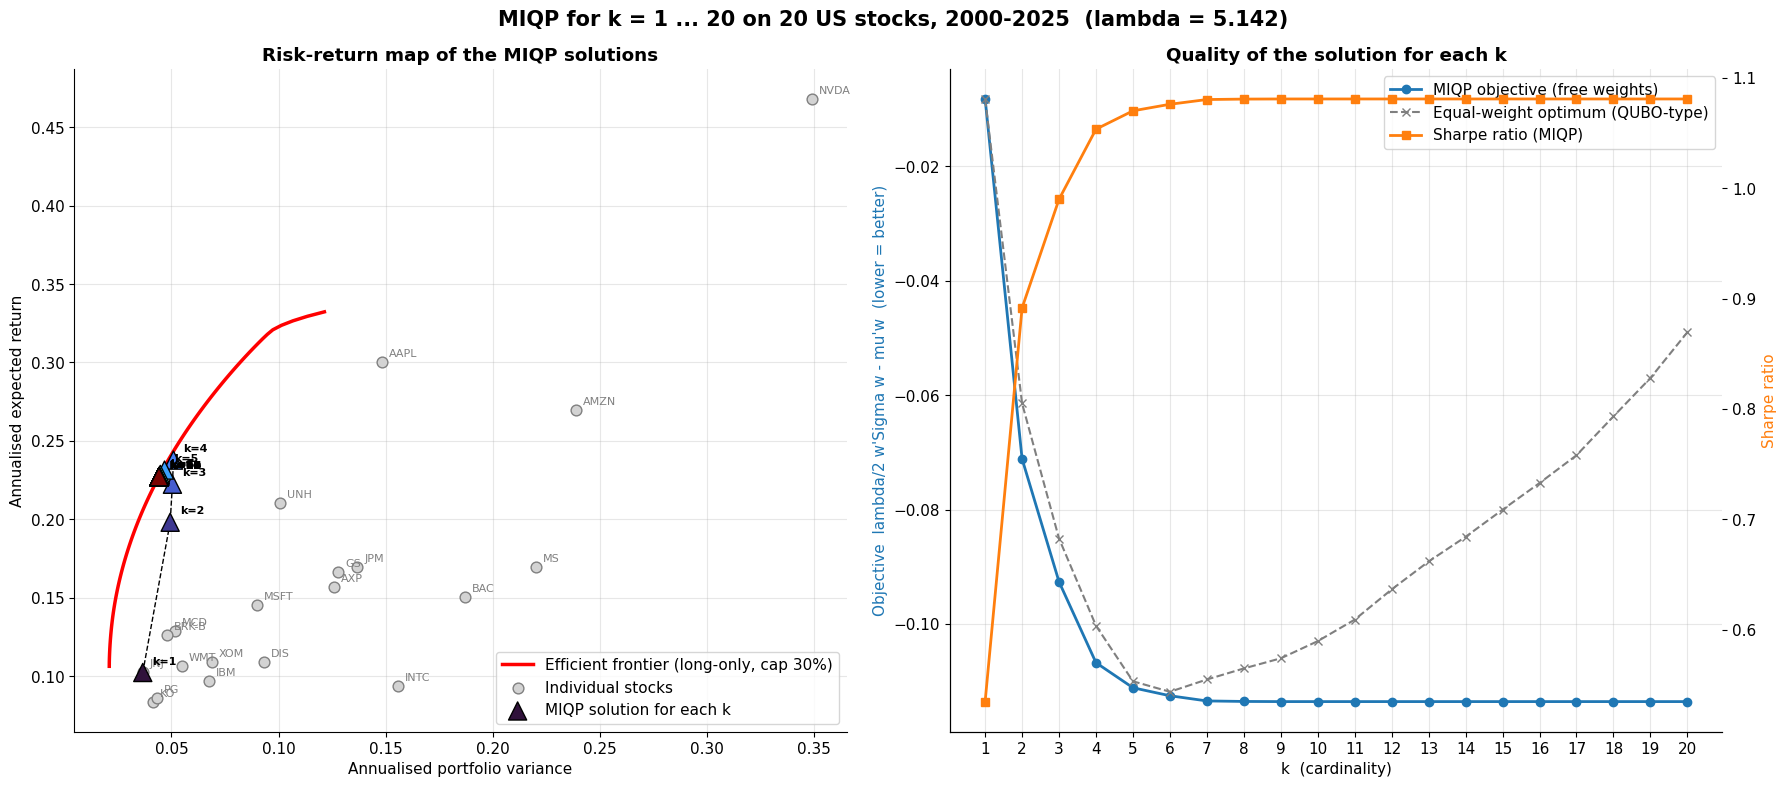

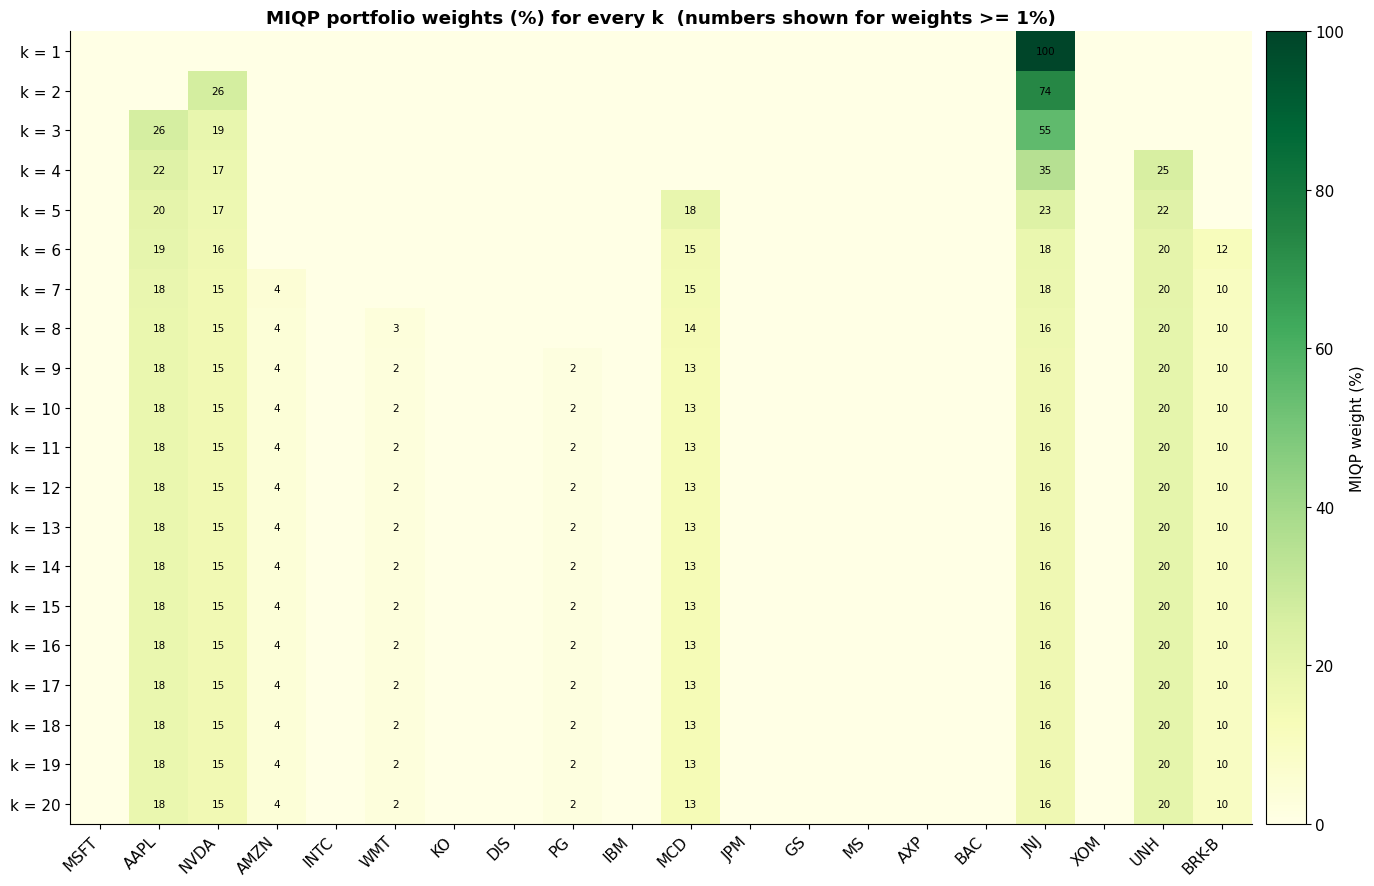

In [13]:
"""
Collect daily price data for 20 US stocks using yfinance.
Period: 2000-01-01 to 2026-01-01

Outputs (in ./us_stock_data):
  - <TICKER>.csv          : per-stock OHLCV data
  - all_stocks_long.csv   : all stocks stacked (Date, Ticker, OHLCV)
  - adj_close_wide.csv    : Date x Ticker matrix of adjusted close prices
  - close_wide.csv        : Date x Ticker matrix of raw close prices
  - download_summary.csv  : rows, first/last date per ticker

Install:  pip install yfinance pandas
"""

import os
import time

import pandas as pd
import yfinance as yf


# Configuration

START_DATE = "2000-01-01"
END_DATE = "2026-01-01"   # yfinance 'end' is exclusive
OUTPUT_DIR = "us_stock_data"
MAX_RETRIES = 3

# Note: Yahoo Finance uses a hyphen for share classes: BRK.B -> BRK-B
# (BRK-A is also available; add it below if you want both share classes.)
STOCKS = {
    "MSFT":  "Microsoft Corporation",
    "AAPL":  "Apple Inc.",
    "NVDA":  "NVIDIA Corporation",
    "AMZN":  "Amazon.com Inc.",
    "INTC":  "Intel Corporation",
    "WMT":   "Walmart Inc.",
    "KO":    "The Coca-Cola Company",
    "DIS":   "The Walt Disney Company",
    "PG":    "The Procter & Gamble Company",
    "IBM":   "International Business Machines",
    "MCD":   "McDonald's Corporation",
    "JPM":   "JPMorgan Chase & Co.",
    "GS":    "The Goldman Sachs Group, Inc.",
    "MS":    "Morgan Stanley",
    "AXP":   "American Express Company",
    "BAC":   "Bank of America Corporation",
    "JNJ":   "Johnson & Johnson",
    "XOM":   "ExxonMobil Corporation",
    "UNH":   "UnitedHealth Group Incorporated",
    "BRK-B": "Berkshire Hathaway Inc. (Class B)",
    # "BRK-A": "Berkshire Hathaway Inc. (Class A)",
}


# ----------------------------------------------------------------------
# Download helper
# ----------------------------------------------------------------------
def download_ticker(ticker: str) -> pd.DataFrame:
    """Download daily OHLCV for one ticker, with retries.

    auto_adjust=False keeps both 'Close' (split-adjusted) and 'Adj Close'
    (split + dividend adjusted).
    """
    for attempt in range(1, MAX_RETRIES + 1):
        try:
            df = yf.download(
                ticker,
                start=START_DATE,
                end=END_DATE,
                interval="1d",
                auto_adjust=False,
                progress=False,
                threads=False,
            )
            if df is not None and not df.empty:
                # Newer yfinance versions return MultiIndex columns
                if isinstance(df.columns, pd.MultiIndex):
                    df.columns = df.columns.get_level_values(0)
                df.index = pd.to_datetime(df.index)
                df.index.name = "Date"
                df = df[["Open", "High", "Low", "Close", "Adj Close", "Volume"]]
                return df.dropna(how="all")
            print(f"  [{ticker}] empty result (attempt {attempt}/{MAX_RETRIES})")
        except Exception as e:
            print(f"  [{ticker}] error: {e} (attempt {attempt}/{MAX_RETRIES})")
        time.sleep(2 * attempt)
    return pd.DataFrame()


# ----------------------------------------------------------------------
# Main
# ----------------------------------------------------------------------
def main():
    os.makedirs(OUTPUT_DIR, exist_ok=True)

    data = {}
    summary = []
    failed = []

    print(f"Downloading {len(STOCKS)} stocks from {START_DATE} to {END_DATE}\n")

    for i, (ticker, name) in enumerate(STOCKS.items(), start=1):
        print(f"[{i:02d}/{len(STOCKS)}] {ticker} - {name}")
        df = download_ticker(ticker)

        if df.empty:
            failed.append(ticker)
            continue

        df.to_csv(os.path.join(OUTPUT_DIR, f"{ticker}.csv"))
        data[ticker] = df
        summary.append(
            {
                "Ticker": ticker,
                "Name": name,
                "Rows": len(df),
                "First_Date": df.index.min().date(),
                "Last_Date": df.index.max().date(),
                "Missing_Close": int(df["Close"].isna().sum()),
            }
        )
        print(f"  -> {len(df)} rows ({df.index.min().date()} to {df.index.max().date()})")
        time.sleep(0.5)  # be polite to Yahoo

    if not data:
        raise SystemExit("No data downloaded. Check your internet connection.")

    # Long format (all stocks stacked)
    long_df = (
        pd.concat(data, names=["Ticker", "Date"])
        .reset_index()
        .sort_values(["Ticker", "Date"])
    )
    long_df.to_csv(os.path.join(OUTPUT_DIR, "all_stocks_long.csv"), index=False)

    # Wide format matrices (Date x Ticker)
    adj_close = pd.DataFrame({t: d["Adj Close"] for t, d in data.items()}).sort_index()
    close = pd.DataFrame({t: d["Close"] for t, d in data.items()}).sort_index()
    adj_close.to_csv(os.path.join(OUTPUT_DIR, "adj_close_wide.csv"))
    close.to_csv(os.path.join(OUTPUT_DIR, "close_wide.csv"))

    # Summary
    summary_df = pd.DataFrame(summary)
    summary_df.to_csv(os.path.join(OUTPUT_DIR, "download_summary.csv"), index=False)

    print("\n" + "=" * 70)
    print(summary_df.to_string(index=False))
    print("=" * 70)
    print(f"Successful: {len(data)}/{len(STOCKS)}")
    if failed:
        print(f"Failed: {failed}")
    print(f"Files saved in: ./{OUTPUT_DIR}/")


if __name__ == "__main__":
    main()

# =============================================================================
# PART 2 | MIQP on the data collected above
# =============================================================================
# =============================================================================
# SETUP (self-contained): loads the data, computes the full-period mu and Sigma and defines the helper functions.
# Identical to the code of your last cell (data / Markowitz helper parts); needs us_stock_data/adj_close_wide.csv.
# =============================================================================
# Same code as the notebook, as a plain script (run cell 1 first to create the CSV)

# =============================================================================
# CELL 2 | Settings, data and inputs (mu, Sigma) - computed ONCE from the full period
# Uses the adj_close_wide.csv written by cell 1.  Nothing is forecast: every optimiser
# below receives exactly the same table of expected returns and covariances.
# =============================================================================
import os, time, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import TwoSlopeNorm
from scipy.optimize import minimize
from IPython.display import display

warnings.filterwarnings("ignore")
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

# ----------------------------- user settings ---------------------------------
DATA_FILE   = "us_stock_data/adj_close_wide.csv"   # written by cell 1
OUT_DIR     = "qubo_fullperiod_outputs"            # figures and tables are saved here
START, END  = "2000-01-01", "2026-01-01"           # full period used for the single optimisation
TD          = 252                                  # trading days per year
RF          = 0.0                                  # risk-free rate (0 matches your Markowitz chart; 0.02 matches cell 3)
MAX_W       = 0.30                                 # cap per stock (1.0 = plain long-only Markowitz, but annealing then struggles; see notes)
GAMMA       = 4.0                                  # risk aversion in  gamma/2 * w'Sigma w - mu'w
UNITS       = 20                                   # weight grid: 1 unit = 1/UNITS of the portfolio (20 -> 5 %)
K_SELECT    = 8                                    # stocks held by the QUBO "select K" variant
PEN_MULT    = 2.0                                  # penalty strength for the budget / cardinality constraint
SA_CHAINS   = 128                                  # parallel annealing chains
SA_SWEEPS   = 150                                  # sweeps per chain
SEED        = 42
SHRINK_COV  = False                                # True -> Ledoit-Wolf shrinkage of the covariance matrix
X_AXIS      = "variance"                           # "variance" (like your chart) or "volatility"
SHOW_RANDOM = False                                # True -> add random portfolios behind the frontier
QUICK       = False                                # True -> smaller grids in the robustness cell

COLORS = {"EW": "#7f7f7f", "MinVar": "#1f77b4", "MaxSharpe": "#ff7f0e",
          "MeanVar": "#2ca02c", "QUBO-W": "#d62728", "QUBO-S": "#9467bd"}
LABELS = {"EW": "Equal weight (1/N)", "MinVar": "Min-variance", "MaxSharpe": "Max-Sharpe",
          "MeanVar": "Mean-variance (continuous)", "QUBO-W": "QUBO weights", "QUBO-S": "QUBO select-K"}

os.makedirs(OUT_DIR, exist_ok=True)
def savefig(name):
    plt.savefig(f"{OUT_DIR}/{name}.png", dpi=300, bbox_inches="tight")

# ------------------------------- data ----------------------------------------
prices = pd.read_csv(DATA_FILE, index_col="Date", parse_dates=True).sort_index().loc[START:END]
returns = prices.pct_change().iloc[1:]
n_rows = len(returns)
returns = returns.dropna()                          # only days on which every stock traded
tickers = list(returns.columns)
N = len(tickers)

def ledoit_wolf_cov(X):
    """Ledoit-Wolf shrinkage towards a scaled identity (same result as scikit-learn's LedoitWolf)."""
    X = X - X.mean(axis=0)
    T, n = X.shape
    S = X.T @ X / T
    m = np.trace(S) / n
    d2 = np.sum((S - m * np.eye(n)) ** 2)
    b2 = min((np.sum(np.sum(X ** 2, axis=1) ** 2) - T * np.sum(S ** 2)) / T ** 2, d2)
    sh = b2 / d2 if d2 > 0 else 0.0
    return (1 - sh) * S + sh * m * np.eye(n)

mu = returns.mean().to_numpy() * TD                                   # annualised mean return (arithmetic)
Sigma = (ledoit_wolf_cov(returns.to_numpy()) if SHRINK_COV else returns.cov().to_numpy()) * TD
assert np.all(np.linalg.eigvalsh(Sigma) > 0), "covariance matrix is not positive definite"

print(f"{N} stocks | {returns.index[0].date()} to {returns.index[-1].date()} | {len(returns)} daily returns "
      f"({n_rows - len(returns)} rows dropped for missing values)")
print(f"risk-free {RF:.1%} | weight cap {MAX_W:.0%} | gamma {GAMMA:g} | covariance: {'Ledoit-Wolf' if SHRINK_COV else 'sample'}")

def xs(var):
    """x-axis coordinate of a portfolio from its variance."""
    var = np.asarray(var, dtype=float)
    return var if X_AXIS == "variance" else np.sqrt(var)
XLABEL = "Annualised portfolio variance" if X_AXIS == "variance" else "Annualised volatility"


# =============================================================================
# CELL 3 | STEP 1: Classical Markowitz solutions (the reference the QUBO is compared with)
#   EW = equal weight | MinVar = minimum variance | MaxSharpe = tangency portfolio
#   MeanVar = minimise gamma/2 w'Sigma w - mu'w   (exactly the objective the QUBO encodes)
# All are long-only, fully invested, capped at MAX_W.
# =============================================================================
def equal_weight(n):
    return np.full(n, 1.0 / n)

def _slsqp(fun, jac, n, cap, starts):
    cons = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0, "jac": lambda w: np.ones(n)}]
    best = None
    for w0 in starts:
        res = minimize(fun, w0, jac=jac, method="SLSQP", bounds=[(0.0, cap)] * n,
                       constraints=cons, options={"maxiter": 1000, "ftol": 1e-12})
        if res.success and (best is None or res.fun < best.fun):
            best = res
    if best is None:
        return equal_weight(n)
    w = np.clip(best.x, 0.0, cap)
    return w / w.sum()

def min_variance(Sigma, cap):
    n = len(Sigma)
    return _slsqp(lambda w: w @ Sigma @ w, lambda w: 2 * Sigma @ w, n, cap, [equal_weight(n)])

def mean_variance(mu, Sigma, gamma, cap):
    n = len(mu)
    return _slsqp(lambda w: 0.5 * gamma * w @ Sigma @ w - mu @ w, lambda w: gamma * Sigma @ w - mu,
                  n, cap, [equal_weight(n), min_variance(Sigma, cap)])

def max_sharpe(mu, Sigma, cap, rf=RF):
    n = len(mu)
    def fun(w):
        return -(mu @ w - rf) / np.sqrt(w @ Sigma @ w)
    def jac(w):
        s = np.sqrt(w @ Sigma @ w)
        return -(mu / s - (mu @ w - rf) * (Sigma @ w) / s ** 3)
    return _slsqp(fun, jac, n, cap, [equal_weight(n), min_variance(Sigma, cap)])

def mv_objective(w, mu, Sigma, gamma):
    return 0.5 * gamma * w @ Sigma @ w - mu @ w

def port_stats(w, mu=mu, Sigma=Sigma):
    """(expected return, variance, volatility, Sharpe)"""
    ret, var = float(mu @ w), float(w @ Sigma @ w)
    return ret, var, np.sqrt(var), (ret - RF) / np.sqrt(var)

def frontier_points(mu, Sigma, cap, n_pts=80):
    """Long-only efficient frontier. Returns arrays (variance, return)."""
    n = len(mu)
    w_min = min_variance(Sigma, cap)
    order, w_hi, left = np.argsort(-mu), np.zeros(n), 1.0
    for i in order:                                    # highest return reachable under the cap
        take = min(cap, left); w_hi[i] = take; left -= take
        if left <= 1e-12: break
    pts = []
    for tr in np.linspace(mu @ w_min, mu @ w_hi, n_pts)[:-1]:
        cons = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0, "jac": lambda w: np.ones(n)},
                {"type": "eq", "fun": lambda w, tr=tr: mu @ w - tr, "jac": lambda w: mu}]
        res = minimize(lambda w: w @ Sigma @ w, w_min, jac=lambda w: 2 * Sigma @ w, method="SLSQP",
                       bounds=[(0.0, cap)] * n, constraints=cons, options={"maxiter": 1000, "ftol": 1e-12})
        if res.success:
            pts.append((res.fun, tr))
    pts.append((w_hi @ Sigma @ w_hi, mu @ w_hi))
    pts = np.array(pts)
    pts = pts[np.argsort(pts[:, 0])]
    return pts[:, 0], np.maximum.accumulate(pts[:, 1])      # variance ascending, return non-decreasing (efficient part only)

def frontier_return_at(var_target, mu, Sigma, cap, w_start):
    """Highest expected return reachable with variance <= var_target (long-only, capped): the exact frontier height at that risk."""
    n = len(mu)
    cons = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0, "jac": lambda w: np.ones(n)},
            {"type": "ineq", "fun": lambda w: var_target - w @ Sigma @ w, "jac": lambda w: -2 * Sigma @ w}]
    res = minimize(lambda w: -mu @ w, w_start, jac=lambda w: -mu, method="SLSQP", bounds=[(0.0, cap)] * n,
                   constraints=cons, options={"maxiter": 1000, "ftol": 1e-12})
    return float(mu @ res.x) if res.success else np.nan


t0 = time.time()
w_ew = equal_weight(N)
w_minvar = min_variance(Sigma, MAX_W)
w_maxsh = max_sharpe(mu, Sigma, MAX_W)
t_cls = time.time() - t0
t0 = time.time()
w_meanvar = mean_variance(mu, Sigma, GAMMA, MAX_W)
t_meanvar = time.time() - t0
f_var, f_ret = frontier_points(mu, Sigma, MAX_W)

# =============================================================================
# MIQP  (Mixed-Integer Quadratic Programming) for the k-stock Markowitz problem, solved for EVERY k = 1 ... 20
#
#     minimise    lambda/2 * w'Sigma w  -  mu'w
#     subject to  sum(w) = 1 ,   sum(z) = k ,   0 <= w_i <= z_i ,   z_i in {0,1}
#
#   z_i = 1  : stock i may be held        w_i : continuous portfolio weight (not forced to be equal)
#   mu, Sigma : full-period 2000-2025 annualised mean return / covariance (no train/test split, no backtest)
#   lambda    : same risk aversion as in the QUBO code: the value for which the continuous mean-variance optimum is the
#               max-Sharpe portfolio,  lambda = (R_t - RF)/sigma_t^2  (from mu and Sigma only)
#   solver    : exact branch-and-bound (Gurobi, else SCIP); where the number of subsets C(20,k) is small enough, the answer is
#               verified by solving the convex QP of every k-stock subset.
# Needs gurobipy and/or pyscipopt; missing packages are installed automatically into the Python that runs the notebook.
# =============================================================================
import sys, subprocess, importlib, time
from math import comb
from itertools import combinations, islice
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

K_LIST     = list(range(1, N + 1))     # k = 1 ... 20
W_MIN      = 0.0                       # 0 -> exactly your model (0 <= w_i <= z_i). e.g. 0.05 forces every chosen stock to weigh >= 5%
ENUM_MAX   = 20000                     # exhaustive verification of the MIQP answer when C(20,k) <= this many subsets

# ------------------------------ lambda ---------------------------------------------
r_t, v_t, _, sh_t = port_stats(w_maxsh)
LAMBDA = (r_t - RF) / v_t
w_chk = mean_variance(mu, Sigma, LAMBDA, MAX_W)
print(f"lambda = (R_t - RF) / var_t = ({r_t:.4f} - {RF:.4f}) / {v_t:.5f} = {LAMBDA:.4f}   "
      f"(check vs max-Sharpe portfolio: max |weight difference| = {np.abs(w_chk - w_maxsh).max():.1e})")
obj = lambda w: 0.5 * LAMBDA * float(w @ Sigma @ w) - float(mu @ w)

# ------------------------------ MIQP models ---------------------------------------------
def _ensure(module, pip_name):
    """import a package; if it is missing, install it into the Python that runs THIS notebook, then import it."""
    try:
        return importlib.import_module(module)
    except ImportError:
        print(f"'{module}' not found in {sys.executable} -> installing '{pip_name}' ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])
        importlib.invalidate_caches()
        return importlib.import_module(module)

ev, V = np.linalg.eigh(Sigma)
Sigma_psd = (V * np.clip(ev, 0, None)) @ V.T                    # Sigma without tiny negative rounding eigenvalues (convex objective)

def solve_gurobi(K):
    gp = _ensure("gurobipy", "gurobipy")
    from gurobipy import GRB
    m = gp.Model("miqp_k_stocks"); m.Params.OutputFlag = 0; m.Params.MIPGap = 1e-9; m.Params.MIPGapAbs = 1e-12
    w = m.addMVar(N, lb=0.0, ub=1.0, name="w"); z = m.addMVar(N, vtype=GRB.BINARY, name="z")
    m.setObjective(0.5 * LAMBDA * (w @ Sigma_psd @ w) - mu @ w, GRB.MINIMIZE)
    m.addConstr(w.sum() == 1); m.addConstr(z.sum() == K); m.addConstr(w <= z); m.addConstr(w >= W_MIN * z)
    m.optimize()
    if m.SolCount == 0:
        raise RuntimeError(f"Gurobi status {m.Status}")
    return w.X.copy(), z.X.copy(), f"optimal, gap {m.MIPGap:.0e}" if m.Status == 2 else f"status {m.Status}"

def solve_scip(K):
    sc = _ensure("pyscipopt", "pyscipopt")
    m = sc.Model("miqp_k_stocks"); m.hideOutput(); m.setParam("limits/gap", 0.0); m.setParam("limits/absgap", 0.0)
    w = [m.addVar(lb=0.0, ub=1.0, name=f"w{i}") for i in range(N)]
    z = [m.addVar(vtype="B", name=f"z{i}") for i in range(N)]
    t = m.addVar(lb=None, name="t")                                 # epigraph variable: t >= lambda/2 w'Sigma w - mu'w
    m.setObjective(t, "minimize")
    m.addCons(t >= 0.5 * LAMBDA * sc.quicksum(float(Sigma_psd[i, j]) * w[i] * w[j] for i in range(N) for j in range(N))
              - sc.quicksum(float(mu[i]) * w[i] for i in range(N)))
    m.addCons(sc.quicksum(w) == 1); m.addCons(sc.quicksum(z) == K)
    for i in range(N):
        m.addCons(w[i] <= z[i]); m.addCons(w[i] >= W_MIN * z[i])
    m.optimize()
    if m.getNSols() == 0:
        raise RuntimeError(f"SCIP status {m.getStatus()}")
    return (np.array([m.getVal(v) for v in w]), np.array([m.getVal(v) for v in z]),
            f"{m.getStatus()}, gap {m.getGap():.0e}")

ACTIVE = [("Gurobi", solve_gurobi), ("SCIP", solve_scip)]
def solve_miqp(K):
    global ACTIVE
    for name, fn in list(ACTIVE):
        try:
            out = fn(K); ACTIVE = [(name, fn)]; return (name,) + out
        except Exception as e:
            print(f"{name} could not be used: {e}")
    raise RuntimeError("No MIQP solver worked. In a notebook cell run:  %pip install gurobipy pyscipopt   then restart the kernel.")

# ------------------------------ helpers for the checks -----------------------------------
def qp_subset(idx):
    """convex QP (long-only, fully invested) on a fixed set of stocks"""
    Ss, ms = Sigma[np.ix_(idx, idx)], mu[idx]
    r = minimize(lambda x: 0.5 * LAMBDA * x @ Ss @ x - ms @ x, np.full(len(idx), 1 / len(idx)),
                 jac=lambda x: LAMBDA * Ss @ x - ms, method="SLSQP", bounds=[(max(W_MIN, 0), 1)] * len(idx),
                 constraints=[{"type": "eq", "fun": lambda x: x.sum() - 1, "jac": lambda x: np.ones(len(x))}],
                 options={"ftol": 1e-14, "maxiter": 500})
    return r.fun, r.x

def best_equal_weight(K, chunk=40000):
    """exact optimum of the equal-weight (1/k) problem = the QUBO-type solution, by enumeration"""
    best_f, best_c, it = np.inf, None, combinations(range(N), K)
    while True:
        c = np.array(list(islice(it, chunk)))
        if len(c) == 0:
            return best_f, best_c
        f = 0.5 * LAMBDA * Sigma[c[:, :, None], c[:, None, :]].sum(axis=(1, 2)) / K ** 2 - mu[c].sum(axis=1) / K
        if f.min() < best_f:
            best_f, best_c = float(f.min()), c[int(np.argmin(f))]

# ------------------------------ solve every k --------------------------------------------
rows, W_ALL = [], {}
t_all = time.time()
for K in K_LIST:
    t0 = time.time()
    solver, w_raw, z_raw, status = solve_miqp(K)
    t_k = time.time() - t0
    w_k = np.where(w_raw < 1e-8, 0.0, w_raw); w_k /= w_k.sum()
    z_k = set(np.flatnonzero(np.round(z_raw) > 0.5))
    held = np.flatnonzero(w_k > 1e-6)
    check = "n/a (too many subsets)"
    if comb(N, K) <= ENUM_MAX:
        res = [(qp_subset(np.array(c)), c) for c in combinations(range(N), K)]
        f_en = min(r[0][0] for r in res)
        check = "match" if abs(f_en - obj(w_k)) < 1e-6 else f"DIFFERENT ({f_en:.6f})"
    f_eq, _ = best_equal_weight(K)
    ret, var, vol, sh = port_stats(w_k)
    W_ALL[K] = w_k
    rows.append({"k": K, "Stocks held (w>0)": len(held), "Exp. return (%)": ret * 100, "Variance": var, "Volatility (%)": vol * 100,
                 "Sharpe": sh, "Objective (MIQP)": obj(w_k), "Objective (equal weight, exact)": f_eq,
                 "Gain from free weights": f_eq - obj(w_k), "Solver status": status, "Solve time (s)": t_k, "Exhaustive check": check})
    print(f"k = {K:2d} | " + ",  ".join(f"{tickers[i]} {w_k[i] * 100:.2f}%" for i in held[np.argsort(-w_k[held])]) +
          f"\n        objective {obj(w_k):.6f} | {solver}: {status} | {t_k:.2f} s | exhaustive check: {check}")
print(f"\nAll {len(K_LIST)} MIQPs solved in {time.time() - t_all:.1f} s with {solver}.\n")

RES = pd.DataFrame(rows).set_index("k")
display(RES.round(5))
W_DF = pd.DataFrame(W_ALL, index=tickers).T.mul(100).rename_axis("k")
RES.to_csv(f"{OUT_DIR}/miqp_all_k_summary.csv"); W_DF.round(4).to_csv(f"{OUT_DIR}/miqp_all_k_weights.csv")
if (RES["Stocks held (w>0)"] < RES.index).any():
    print("Note: with 0 <= w_i <= z_i a selected stock may get weight 0, so for larger k the MIQP can hold fewer than k stocks "
          "(the objective can only improve or stay equal as k grows). Set W_MIN > 0 to force every chosen stock to be held.")

# ------------------------------ chart 1: risk-return map and objective versus k -----------------------
sig2 = np.diag(Sigma)
mv = np.array([port_stats(W_ALL[k])[1] for k in K_LIST]); mr = np.array([port_stats(W_ALL[k])[0] for k in K_LIST])
cmap = plt.get_cmap("turbo"); norm = plt.Normalize(K_LIST[0], K_LIST[-1])
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
ax = axes[0]
ax.plot(xs(f_var), f_ret, color="red", lw=2.5, label=f"Efficient frontier (long-only, cap {MAX_W:.0%})", zorder=2)
ax.scatter(xs(sig2), mu, s=60, color="lightgrey", edgecolor="grey", label="Individual stocks", zorder=3)
for i, t in enumerate(tickers):
    ax.annotate(t, (xs(sig2[i]), mu[i]), xytext=(5, 4), textcoords="offset points", fontsize=8, color="grey")
ax.plot(xs(mv), mr, color="black", lw=1, ls="--", zorder=4)
ax.scatter(xs(mv), mr, c=K_LIST, cmap=cmap, norm=norm, marker="^", s=170, edgecolor="black", zorder=5, label="MIQP solution for each k")
for k, x_, y_ in zip(K_LIST, xs(mv), mr):
    ax.annotate(f"k={k}", (x_, y_), xytext=(7, 6), textcoords="offset points", fontsize=8, fontweight="bold", zorder=6)
ax.set_xlabel(XLABEL); ax.set_ylabel("Annualised expected return"); ax.grid(True, alpha=0.3); ax.legend(loc="lower right")
ax.set_title("Risk-return map of the MIQP solutions", fontweight="bold")

ax = axes[1]
ax.plot(K_LIST, RES["Objective (MIQP)"], color="#1f77b4", marker="o", lw=2, label="MIQP objective (free weights)")
ax.plot(K_LIST, RES["Objective (equal weight, exact)"], color="#7f7f7f", marker="x", lw=1.5, ls="--", label="Equal-weight optimum (QUBO-type)")
ax.set_xlabel("k  (cardinality)"); ax.set_ylabel("Objective  lambda/2 w'Sigma w - mu'w  (lower = better)", color="#1f77b4")
ax.set_xticks(K_LIST); ax.grid(True, alpha=0.3)
ax2 = ax.twinx(); ax2.plot(K_LIST, RES["Sharpe"], color="#ff7f0e", marker="s", lw=2, label="Sharpe ratio (MIQP)"); ax2.set_ylabel("Sharpe ratio", color="#ff7f0e")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, loc="best")
ax.set_title("Quality of the solution for each k", fontweight="bold")
fig.suptitle(f"MIQP for k = 1 ... {N} on {N} US stocks, {returns.index[0].year}-{returns.index[-1].year}  (lambda = {LAMBDA:.3f})",
             fontsize=15, fontweight="bold")
plt.tight_layout(); savefig("miqp_all_k_riskreturn_and_objective"); plt.show()

# ------------------------------ chart 2: weights for every k ----------------------------------------
fig, ax = plt.subplots(figsize=(15, 9))
im = ax.imshow(W_DF.values, aspect="auto", cmap="YlGn", vmin=0, vmax=max(40, W_DF.values.max()))
ax.set_xticks(range(N)); ax.set_xticklabels(tickers, rotation=45, ha="right")
ax.set_yticks(range(len(K_LIST))); ax.set_yticklabels([f"k = {k}" for k in K_LIST])
for i in range(len(K_LIST)):
    for j in range(N):
        if W_DF.values[i, j] >= 1:
            ax.text(j, i, f"{W_DF.values[i, j]:.0f}", ha="center", va="center", fontsize=7.5)
plt.colorbar(im, ax=ax, pad=0.01).set_label("MIQP weight (%)")
ax.set_title("MIQP portfolio weights (%) for every k  (numbers shown for weights >= 1%)", fontweight="bold")
plt.tight_layout(); savefig("miqp_all_k_weights_heatmap"); plt.show()


[01/20] MSFT - Microsoft Corporation
  -> 6539 rows (2000-01-03 to 2025-12-31)
[02/20] AAPL - Apple Inc.
  -> 6539 rows (2000-01-03 to 2025-12-31)
[03/20] NVDA - NVIDIA Corporation
  -> 6539 rows (2000-01-03 to 2025-12-31)
[04/20] AMZN - Amazon.com Inc.
  -> 6539 rows (2000-01-03 to 2025-12-31)
[05/20] INTC - Intel Corporation
  -> 6539 rows (2000-01-03 to 2025-12-31)
[06/20] WMT - Walmart Inc.
  -> 6539 rows (2000-01-03 to 2025-12-31)
[07/20] KO - The Coca-Cola Company
  -> 6539 rows (2000-01-03 to 2025-12-31)
[08/20] DIS - The Walt Disney Company
  -> 6539 rows (2000-01-03 to 2025-12-31)
[09/20] PG - The Procter & Gamble Company
  -> 6539 rows (2000-01-03 to 2025-12-31)
[10/20] IBM - International Business Machines
  -> 6539 rows (2000-01-03 to 2025-12-31)
[11/20] MCD - McDonald's Corporation
  -> 6539 rows (2000-01-03 to 2025-12-31)
[12/20] JPM - JPMorgan Chase & Co.
  -> 6539 rows (2000-01-03 to 2025-12-31)
[13/20] GS - The Goldman Sachs Group, Inc.
  -> 6539 rows (2000-01-03 to 2

,Stocks,Reads,Energy,Exactly k stocks,Objective,Gap to exact optimum
0,"AAPL, NVDA, JNJ, UNH",88,-0.100324,True,-0.100324,0.000000
1,"AAPL, NVDA, MCD, UNH",54,-0.098404,True,-0.098404,0.001920
2,"NVDA, MCD, JNJ, UNH",62,-0.097905,True,-0.097905,0.002419
3,"AAPL, NVDA, PG, UNH",41,-0.097343,True,-0.097343,0.002982
4,"AAPL, NVDA, UNH, BRK-B",43,-0.096019,True,-0.096019,0.004305
5,"NVDA, JNJ, UNH, BRK-B",39,-0.095433,True,-0.095433,0.004892
6,"NVDA, MCD, UNH, BRK-B",29,-0.095025,True,-0.095025,0.005299
7,"AAPL, NVDA, KO, UNH",21,-0.094288,True,-0.094288,0.006036
8,"AAPL, NVDA, MCD, JNJ",21,-0.094224,True,-0.094224,0.006100
9,"NVDA, PG, MCD, UNH",21,-0.094090,True,-0.094090,0.006235


Best sample portfolio: return 27.01% | variance 0.0660 | volatility 25.70% | Sharpe 1.051


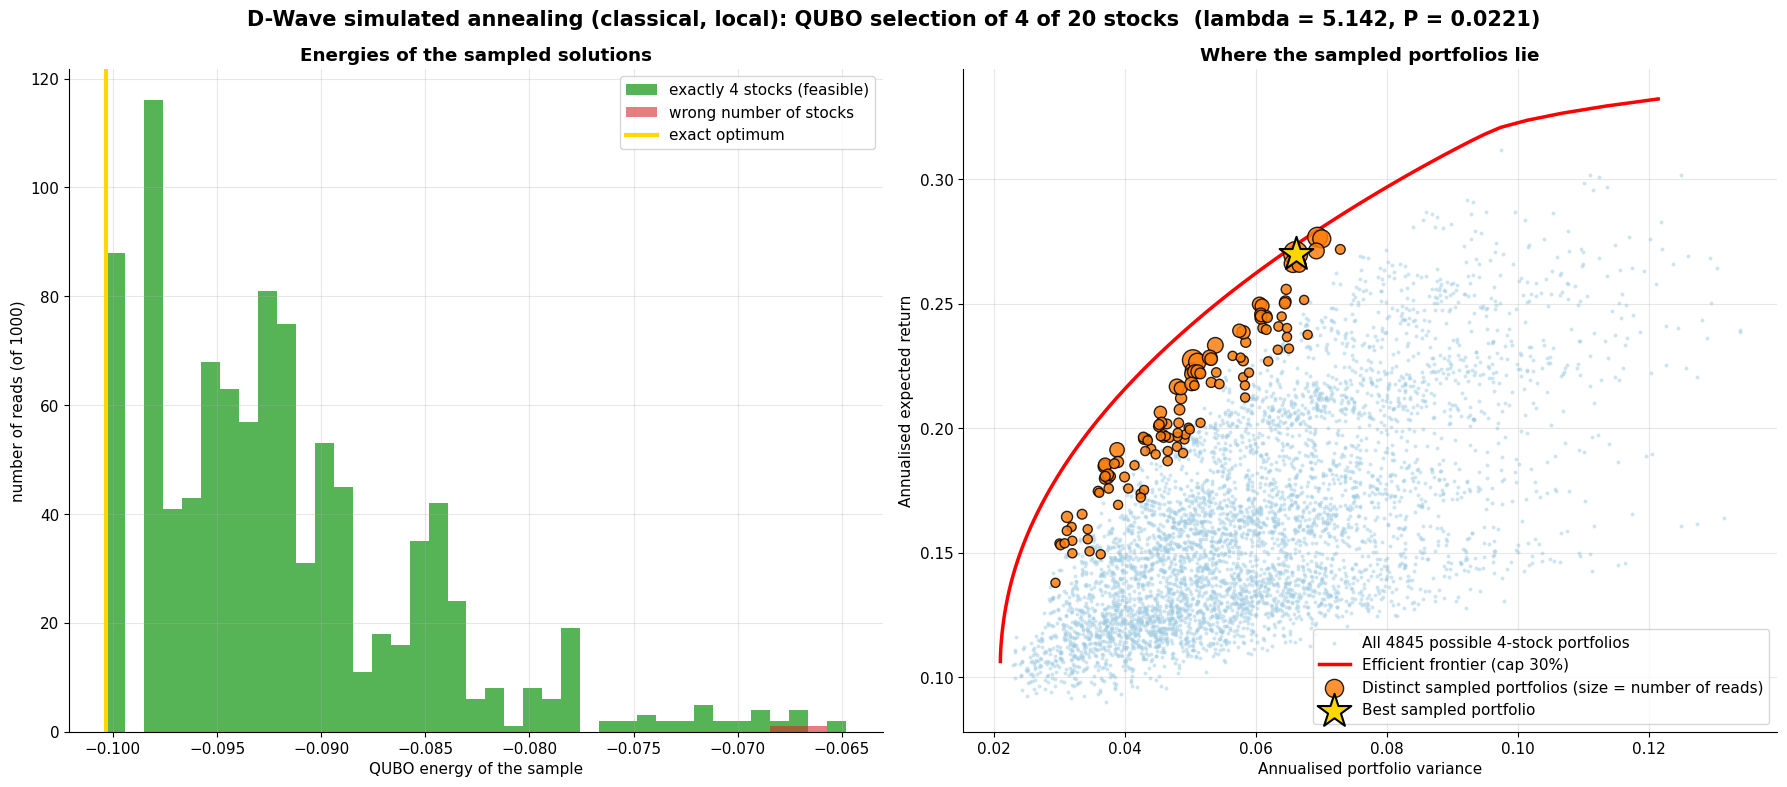

In [1]:
"""
Collect daily price data for 20 US stocks using yfinance.
Period: 2000-01-01 to 2026-01-01

Outputs (in ./us_stock_data):
  - <TICKER>.csv          : per-stock OHLCV data
  - all_stocks_long.csv   : all stocks stacked (Date, Ticker, OHLCV)
  - adj_close_wide.csv    : Date x Ticker matrix of adjusted close prices
  - close_wide.csv        : Date x Ticker matrix of raw close prices
  - download_summary.csv  : rows, first/last date per ticker

Install:  pip install yfinance pandas
"""

import os
import time

import pandas as pd
import yfinance as yf

# ----------------------------------------------------------------------
# Configuration
# ----------------------------------------------------------------------
START_DATE = "2000-01-01"
END_DATE = "2026-01-01"   # yfinance 'end' is exclusive
OUTPUT_DIR = "us_stock_data"
MAX_RETRIES = 3

# Note: Yahoo Finance uses a hyphen for share classes: BRK.B -> BRK-B
# (BRK-A is also available; add it below if you want both share classes.)
STOCKS = {
    "MSFT":  "Microsoft Corporation",
    "AAPL":  "Apple Inc.",
    "NVDA":  "NVIDIA Corporation",
    "AMZN":  "Amazon.com Inc.",
    "INTC":  "Intel Corporation",
    "WMT":   "Walmart Inc.",
    "KO":    "The Coca-Cola Company",
    "DIS":   "The Walt Disney Company",
    "PG":    "The Procter & Gamble Company",
    "IBM":   "International Business Machines",
    "MCD":   "McDonald's Corporation",
    "JPM":   "JPMorgan Chase & Co.",
    "GS":    "The Goldman Sachs Group, Inc.",
    "MS":    "Morgan Stanley",
    "AXP":   "American Express Company",
    "BAC":   "Bank of America Corporation",
    "JNJ":   "Johnson & Johnson",
    "XOM":   "ExxonMobil Corporation",
    "UNH":   "UnitedHealth Group Incorporated",
    "BRK-B": "Berkshire Hathaway Inc. (Class B)",
    # "BRK-A": "Berkshire Hathaway Inc. (Class A)",
}


# ----------------------------------------------------------------------
# Download helper
# ----------------------------------------------------------------------
def download_ticker(ticker: str) -> pd.DataFrame:
    """Download daily OHLCV for one ticker, with retries.

    auto_adjust=False keeps both 'Close' (split-adjusted) and 'Adj Close'
    (split + dividend adjusted).
    """
    for attempt in range(1, MAX_RETRIES + 1):
        try:
            df = yf.download(
                ticker,
                start=START_DATE,
                end=END_DATE,
                interval="1d",
                auto_adjust=False,
                progress=False,
                threads=False,
            )
            if df is not None and not df.empty:
                # Newer yfinance versions return MultiIndex columns
                if isinstance(df.columns, pd.MultiIndex):
                    df.columns = df.columns.get_level_values(0)
                df.index = pd.to_datetime(df.index)
                df.index.name = "Date"
                df = df[["Open", "High", "Low", "Close", "Adj Close", "Volume"]]
                return df.dropna(how="all")
            print(f"  [{ticker}] empty result (attempt {attempt}/{MAX_RETRIES})")
        except Exception as e:
            print(f"  [{ticker}] error: {e} (attempt {attempt}/{MAX_RETRIES})")
        time.sleep(2 * attempt)
    return pd.DataFrame()


# ----------------------------------------------------------------------
# Main
# ----------------------------------------------------------------------
def main():
    os.makedirs(OUTPUT_DIR, exist_ok=True)

    data = {}
    summary = []
    failed = []

    print(f"Downloading {len(STOCKS)} stocks from {START_DATE} to {END_DATE}\n")

    for i, (ticker, name) in enumerate(STOCKS.items(), start=1):
        print(f"[{i:02d}/{len(STOCKS)}] {ticker} - {name}")
        df = download_ticker(ticker)

        if df.empty:
            failed.append(ticker)
            continue

        df.to_csv(os.path.join(OUTPUT_DIR, f"{ticker}.csv"))
        data[ticker] = df
        summary.append(
            {
                "Ticker": ticker,
                "Name": name,
                "Rows": len(df),
                "First_Date": df.index.min().date(),
                "Last_Date": df.index.max().date(),
                "Missing_Close": int(df["Close"].isna().sum()),
            }
        )
        print(f"  -> {len(df)} rows ({df.index.min().date()} to {df.index.max().date()})")
        time.sleep(0.5)  # be polite to Yahoo

    if not data:
        raise SystemExit("No data downloaded. Check your internet connection.")

    # Long format (all stocks stacked)
    long_df = (
        pd.concat(data, names=["Ticker", "Date"])
        .reset_index()
        .sort_values(["Ticker", "Date"])
    )
    long_df.to_csv(os.path.join(OUTPUT_DIR, "all_stocks_long.csv"), index=False)

    # Wide format matrices (Date x Ticker)
    adj_close = pd.DataFrame({t: d["Adj Close"] for t, d in data.items()}).sort_index()
    close = pd.DataFrame({t: d["Close"] for t, d in data.items()}).sort_index()
    adj_close.to_csv(os.path.join(OUTPUT_DIR, "adj_close_wide.csv"))
    close.to_csv(os.path.join(OUTPUT_DIR, "close_wide.csv"))

    # Summary
    summary_df = pd.DataFrame(summary)
    summary_df.to_csv(os.path.join(OUTPUT_DIR, "download_summary.csv"), index=False)

    print("\n" + "=" * 70)
    print(summary_df.to_string(index=False))
    print("=" * 70)
    print(f"Successful: {len(data)}/{len(STOCKS)}")
    if failed:
        print(f"Failed: {failed}")
    print(f"Files saved in: ./{OUTPUT_DIR}/")


if __name__ == "__main__":
    main()

# =============================================================================
# PART 2 | MIQP on the data collected above
# =============================================================================
# =============================================================================
# SETUP (self-contained): loads the data, computes the full-period mu and Sigma and defines the helper functions.
# Identical to the code of your last cell (data / Markowitz helper parts); needs us_stock_data/adj_close_wide.csv.
# =============================================================================
# Same code as the notebook, as a plain script (run cell 1 first to create the CSV)

# =============================================================================
# CELL 2 | Settings, data and inputs (mu, Sigma) - computed ONCE from the full period
# Uses the adj_close_wide.csv written by cell 1.  Nothing is forecast: every optimiser
# below receives exactly the same table of expected returns and covariances.
# =============================================================================
import os, time, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import TwoSlopeNorm
from scipy.optimize import minimize
from IPython.display import display

warnings.filterwarnings("ignore")
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

# ----------------------------- user settings ---------------------------------
DATA_FILE   = "us_stock_data/adj_close_wide.csv"   # written by cell 1
OUT_DIR     = "qubo_fullperiod_outputs"            # figures and tables are saved here
START, END  = "2000-01-01", "2026-01-01"           # full period used for the single optimisation
TD          = 252                                  # trading days per year
RF          = 0.0                                  # risk-free rate (0 matches your Markowitz chart; 0.02 matches cell 3)
MAX_W       = 0.30                                 # cap per stock (1.0 = plain long-only Markowitz, but annealing then struggles; see notes)
GAMMA       = 4.0                                  # risk aversion in  gamma/2 * w'Sigma w - mu'w
UNITS       = 20                                   # weight grid: 1 unit = 1/UNITS of the portfolio (20 -> 5 %)
K_SELECT    = 8                                    # stocks held by the QUBO "select K" variant
PEN_MULT    = 2.0                                  # penalty strength for the budget / cardinality constraint
SA_CHAINS   = 128                                  # parallel annealing chains
SA_SWEEPS   = 150                                  # sweeps per chain
SEED        = 42
SHRINK_COV  = False                                # True -> Ledoit-Wolf shrinkage of the covariance matrix
X_AXIS      = "variance"                           # "variance" (like your chart) or "volatility"
SHOW_RANDOM = False                                # True -> add random portfolios behind the frontier
QUICK       = False                                # True -> smaller grids in the robustness cell

COLORS = {"EW": "#7f7f7f", "MinVar": "#1f77b4", "MaxSharpe": "#ff7f0e",
          "MeanVar": "#2ca02c", "QUBO-W": "#d62728", "QUBO-S": "#9467bd"}
LABELS = {"EW": "Equal weight (1/N)", "MinVar": "Min-variance", "MaxSharpe": "Max-Sharpe",
          "MeanVar": "Mean-variance (continuous)", "QUBO-W": "QUBO weights", "QUBO-S": "QUBO select-K"}

os.makedirs(OUT_DIR, exist_ok=True)
def savefig(name):
    plt.savefig(f"{OUT_DIR}/{name}.png", dpi=300, bbox_inches="tight")

# ------------------------------- data ----------------------------------------
prices = pd.read_csv(DATA_FILE, index_col="Date", parse_dates=True).sort_index().loc[START:END]
returns = prices.pct_change().iloc[1:]
n_rows = len(returns)
returns = returns.dropna()                          # only days on which every stock traded
tickers = list(returns.columns)
N = len(tickers)

def ledoit_wolf_cov(X):
    """Ledoit-Wolf shrinkage towards a scaled identity (same result as scikit-learn's LedoitWolf)."""
    X = X - X.mean(axis=0)
    T, n = X.shape
    S = X.T @ X / T
    m = np.trace(S) / n
    d2 = np.sum((S - m * np.eye(n)) ** 2)
    b2 = min((np.sum(np.sum(X ** 2, axis=1) ** 2) - T * np.sum(S ** 2)) / T ** 2, d2)
    sh = b2 / d2 if d2 > 0 else 0.0
    return (1 - sh) * S + sh * m * np.eye(n)

mu = returns.mean().to_numpy() * TD                                   # annualised mean return (arithmetic)
Sigma = (ledoit_wolf_cov(returns.to_numpy()) if SHRINK_COV else returns.cov().to_numpy()) * TD
assert np.all(np.linalg.eigvalsh(Sigma) > 0), "covariance matrix is not positive definite"

print(f"{N} stocks | {returns.index[0].date()} to {returns.index[-1].date()} | {len(returns)} daily returns "
      f"({n_rows - len(returns)} rows dropped for missing values)")
print(f"risk-free {RF:.1%} | weight cap {MAX_W:.0%} | gamma {GAMMA:g} | covariance: {'Ledoit-Wolf' if SHRINK_COV else 'sample'}")

def xs(var):
    """x-axis coordinate of a portfolio from its variance."""
    var = np.asarray(var, dtype=float)
    return var if X_AXIS == "variance" else np.sqrt(var)
XLABEL = "Annualised portfolio variance" if X_AXIS == "variance" else "Annualised volatility"


# =============================================================================
# CELL 3 | STEP 1: Classical Markowitz solutions (the reference the QUBO is compared with)
#   EW = equal weight | MinVar = minimum variance | MaxSharpe = tangency portfolio
#   MeanVar = minimise gamma/2 w'Sigma w - mu'w   (exactly the objective the QUBO encodes)
# All are long-only, fully invested, capped at MAX_W.
# =============================================================================
def equal_weight(n):
    return np.full(n, 1.0 / n)

def _slsqp(fun, jac, n, cap, starts):
    cons = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0, "jac": lambda w: np.ones(n)}]
    best = None
    for w0 in starts:
        res = minimize(fun, w0, jac=jac, method="SLSQP", bounds=[(0.0, cap)] * n,
                       constraints=cons, options={"maxiter": 1000, "ftol": 1e-12})
        if res.success and (best is None or res.fun < best.fun):
            best = res
    if best is None:
        return equal_weight(n)
    w = np.clip(best.x, 0.0, cap)
    return w / w.sum()

def min_variance(Sigma, cap):
    n = len(Sigma)
    return _slsqp(lambda w: w @ Sigma @ w, lambda w: 2 * Sigma @ w, n, cap, [equal_weight(n)])

def mean_variance(mu, Sigma, gamma, cap):
    n = len(mu)
    return _slsqp(lambda w: 0.5 * gamma * w @ Sigma @ w - mu @ w, lambda w: gamma * Sigma @ w - mu,
                  n, cap, [equal_weight(n), min_variance(Sigma, cap)])

def max_sharpe(mu, Sigma, cap, rf=RF):
    n = len(mu)
    def fun(w):
        return -(mu @ w - rf) / np.sqrt(w @ Sigma @ w)
    def jac(w):
        s = np.sqrt(w @ Sigma @ w)
        return -(mu / s - (mu @ w - rf) * (Sigma @ w) / s ** 3)
    return _slsqp(fun, jac, n, cap, [equal_weight(n), min_variance(Sigma, cap)])

def mv_objective(w, mu, Sigma, gamma):
    return 0.5 * gamma * w @ Sigma @ w - mu @ w

def port_stats(w, mu=mu, Sigma=Sigma):
    """(expected return, variance, volatility, Sharpe)"""
    ret, var = float(mu @ w), float(w @ Sigma @ w)
    return ret, var, np.sqrt(var), (ret - RF) / np.sqrt(var)

def frontier_points(mu, Sigma, cap, n_pts=80):
    """Long-only efficient frontier. Returns arrays (variance, return)."""
    n = len(mu)
    w_min = min_variance(Sigma, cap)
    order, w_hi, left = np.argsort(-mu), np.zeros(n), 1.0
    for i in order:                                    # highest return reachable under the cap
        take = min(cap, left); w_hi[i] = take; left -= take
        if left <= 1e-12: break
    pts = []
    for tr in np.linspace(mu @ w_min, mu @ w_hi, n_pts)[:-1]:
        cons = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0, "jac": lambda w: np.ones(n)},
                {"type": "eq", "fun": lambda w, tr=tr: mu @ w - tr, "jac": lambda w: mu}]
        res = minimize(lambda w: w @ Sigma @ w, w_min, jac=lambda w: 2 * Sigma @ w, method="SLSQP",
                       bounds=[(0.0, cap)] * n, constraints=cons, options={"maxiter": 1000, "ftol": 1e-12})
        if res.success:
            pts.append((res.fun, tr))
    pts.append((w_hi @ Sigma @ w_hi, mu @ w_hi))
    pts = np.array(pts)
    pts = pts[np.argsort(pts[:, 0])]
    return pts[:, 0], np.maximum.accumulate(pts[:, 1])      # variance ascending, return non-decreasing (efficient part only)

def frontier_return_at(var_target, mu, Sigma, cap, w_start):
    """Highest expected return reachable with variance <= var_target (long-only, capped): the exact frontier height at that risk."""
    n = len(mu)
    cons = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0, "jac": lambda w: np.ones(n)},
            {"type": "ineq", "fun": lambda w: var_target - w @ Sigma @ w, "jac": lambda w: -2 * Sigma @ w}]
    res = minimize(lambda w: -mu @ w, w_start, jac=lambda w: -mu, method="SLSQP", bounds=[(0.0, cap)] * n,
                   constraints=cons, options={"maxiter": 1000, "ftol": 1e-12})
    return float(mu @ res.x) if res.success else np.nan


t0 = time.time()
w_ew = equal_weight(N)
w_minvar = min_variance(Sigma, MAX_W)
w_maxsh = max_sharpe(mu, Sigma, MAX_W)
t_cls = time.time() - t0
t0 = time.time()
w_meanvar = mean_variance(mu, Sigma, GAMMA, MAX_W)
t_meanvar = time.time() - t0
f_var, f_ret = frontier_points(mu, Sigma, MAX_W)

# =============================================================================
# D-WAVE OCEAN VERSION OF THE k-STOCK QUBO  (k = 4)
#
# The same QUBO as before, written as a dimod BinaryQuadraticModel and sampled with an Ocean sampler:
#     H(x) = lambda/2 * (x'Sigma x)/k^2 - (mu'x)/k + P * (sum(x) - k)^2 ,     x_i in {0,1},  weight of a chosen stock = 1/k
#   mu, Sigma : full-period 2000-2025 annualised mean return / covariance (from the downloaded data above)
#   lambda    : (R_t - RF)/sigma_t^2  (the value for which the max-Sharpe portfolio is the continuous mean-variance optimum)
#   P         : Monte Carlo penalty estimate (Algorithm 1 of the paper, Eq. 8), largest estimate of all runs
#
#   SAMPLER = "local"  -> D-Wave's classical simulated-annealing sampler on your own computer (free, no account)
#   SAMPLER = "qpu"    -> the real D-Wave quantum annealer (needs a D-Wave Leap account and API token)
# The result is compared with the exhaustive optimum over all C(20,k) subsets.
# =============================================================================
import sys, subprocess, importlib, time, os
from math import comb
from itertools import combinations, islice
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ----------------------------- settings -------------------------------------------
K          = 4                         # number of stocks to select
SAMPLER    = "local"                   # "local" (simulated annealing, classical)  or  "qpu" (D-Wave quantum annealer)
NUM_READS  = 1000                      # number of samples (anneals) requested
NUM_SWEEPS = 1000                      # local sampler only: sweeps per read
ANNEAL_US  = None                      # qpu only: annealing time in microseconds (None = default 20)
CHAIN_STRENGTH = None                  # qpu only: None = automatic
DWAVE_TOKEN = os.environ.get("DWAVE_API_TOKEN")   # qpu only: your Leap API token (or run `dwave config create` once)
MC_N, MC_RUNS, MC_SEED = 5000, 200, SEED + 7

def _ensure(module, pip_name):
    """import a package; if it is missing, install it into the Python that runs THIS notebook, then import it."""
    try:
        return importlib.import_module(module)
    except ImportError:
        print(f"'{module}' not found in {sys.executable} -> installing '{pip_name}' ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])
        importlib.invalidate_caches()
        return importlib.import_module(module)

# ----------------------------- lambda ---------------------------------------------
r_t, v_t, _, sh_t = port_stats(w_maxsh)
LAMBDA = (r_t - RF) / v_t
w_chk = mean_variance(mu, Sigma, LAMBDA, MAX_W)
print(f"lambda = (R_t - RF) / var_t = ({r_t:.4f} - {RF:.4f}) / {v_t:.5f} = {LAMBDA:.4f}   "
      f"(check vs max-Sharpe portfolio: max |weight difference| = {np.abs(w_chk - w_maxsh).max():.1e})")
obj_w = lambda w: 0.5 * LAMBDA * float(w @ Sigma @ w) - float(mu @ w)

# ----------------------------- Monte Carlo penalty --------------------------------
def mc_binary_samples(n, m, rng):
    card = rng.integers(0, n + 1, size=m)
    rank = np.argsort(np.argsort(rng.random((m, n)), axis=1), axis=1)
    return (rank < card[:, None]).astype(float)

def penalty_lower_bound(q, lin, s, k, lam):
    f = 0.5 * lam / k ** 2 * q - lin / k
    viol = (s - k) ** 2
    v_min = viol.min()
    f_from = f[viol == v_min].min()
    m = (f < f_from) & (viol > v_min)
    if not m.any():
        return 0.0
    return ((f_from - f[m]) / (viol[m] - v_min)).max()

rng_mc = np.random.default_rng(MC_SEED)
mc_p = np.zeros(MC_RUNS)
for run in range(MC_RUNS):
    Xs = mc_binary_samples(N, MC_N, rng_mc)
    mc_p[run] = penalty_lower_bound(np.einsum("ri,ij,rj->r", Xs, Sigma, Xs), Xs @ mu, Xs.sum(axis=1), K, LAMBDA)
P = mc_p.max()
print(f"penalty P for k = {K}: Monte Carlo max over {MC_RUNS} runs = {P:.5f}")

# ----------------------------- QUBO -> dimod BinaryQuadraticModel ------------------
Q = 0.5 * LAMBDA / K ** 2 * Sigma - np.diag(mu / K) + P * (np.ones((N, N)) - 2 * K * np.eye(N))     # H = x'Qx + const
CONST = P * K ** 2
dimod = _ensure("dimod", "dimod")
bqm = dimod.BinaryQuadraticModel.from_qubo({(i, j): (Q[i, j] + Q[j, i] if i != j else Q[i, i])
                                            for i in range(N) for j in range(i, N)}, offset=CONST)
print(f"BQM: {bqm.num_variables} binary variables, {bqm.num_interactions} couplings (fully connected)")

# ----------------------------- sample ---------------------------------------------
t0 = time.time()
if SAMPLER == "local":
    sa = _ensure("dwave.samplers", "dwave-samplers")
    sampleset = sa.SimulatedAnnealingSampler().sample(bqm, num_reads=NUM_READS, num_sweeps=NUM_SWEEPS, seed=SEED)
    sampler_name = "D-Wave simulated annealing (classical, local)"
elif SAMPLER == "qpu":
    ds = _ensure("dwave.system", "dwave-system")
    qpu = ds.DWaveSampler(token=DWAVE_TOKEN) if DWAVE_TOKEN else ds.DWaveSampler()
    kw = dict(num_reads=NUM_READS, label=f"QUBO {K}-stock portfolio")
    if ANNEAL_US: kw["annealing_time"] = ANNEAL_US
    if CHAIN_STRENGTH: kw["chain_strength"] = CHAIN_STRENGTH
    sampleset = ds.EmbeddingComposite(qpu).sample(bqm, **kw)
    sampler_name = f"D-Wave quantum annealer ({qpu.properties.get('chip_id', 'QPU')})"
else:
    raise ValueError('SAMPLER must be "local" or "qpu"')
t_sample = time.time() - t0
print(f"Sampler: {sampler_name}  |  {NUM_READS} reads in {t_sample:.1f} s")
if SAMPLER == "qpu":
    cbf = sampleset.record.chain_break_fraction.mean() if "chain_break_fraction" in sampleset.record.dtype.names else float("nan")
    print(f"QPU access time {sampleset.info.get('timing', {}).get('qpu_access_time', float('nan')) / 1e3:.1f} ms | "
          f"mean chain-break fraction {cbf:.3f}")

# ----------------------------- analyse the samples --------------------------------
ss = sampleset.aggregate()
cols = [list(ss.variables).index(i) for i in range(N)]
X = np.array(ss.record.sample)[:, cols].astype(float)
counts = np.array(ss.record.num_occurrences); E = np.array(ss.record.energy)
assert np.allclose(E, np.einsum("ui,ij,uj->u", X, Q, X) + CONST, atol=1e-8), "energy mismatch"
feas = X.sum(axis=1) == K
Wmat = X / K
objs = np.array([obj_w(w) if f else np.nan for w, f in zip(Wmat, feas)])      # risk-return objective of the equal-weight portfolio

def best_equal_weight(K, chunk=40000):
    best_f, best_c, it = np.inf, None, combinations(range(N), K)
    while True:
        c = np.array(list(islice(it, chunk)))
        if len(c) == 0:
            return best_f, best_c
        f = 0.5 * LAMBDA * Sigma[c[:, :, None], c[:, None, :]].sum(axis=(1, 2)) / K ** 2 - mu[c].sum(axis=1) / K
        if f.min() < best_f:
            best_f, best_c = float(f.min()), c[int(np.argmin(f))]
f_ex, c_ex = best_equal_weight(K)

best = int(np.nanargmin(objs)) if feas.any() else None
total = counts.sum()
print(f"\nReads that satisfy 'exactly {K} stocks': {counts[feas].sum() / total * 100:.1f}%   |   distinct solutions found: {len(counts)}")
if best is None:
    raise RuntimeError("No sampled solution has exactly k stocks: increase NUM_READS or P.")
hit = feas & np.isclose(objs, f_ex, atol=1e-10)
print(f"Reads that found the exact optimum: {counts[hit].sum() / total * 100:.1f}%")
sel = np.flatnonzero(X[best])
print("=" * 78)
print(f"SAMPLER RESULT (best feasible sample, k = {K}): " + ", ".join(tickers[i] for i in sel) + f"  -> {100 / K:.0f}% each")
print(f"exhaustive optimum                           : " + ", ".join(tickers[i] for i in sorted(c_ex)))
print(f"same stocks as exhaustive optimum: {set(sel) == set(c_ex)}   |   objective {objs[best]:.6f} vs exact {f_ex:.6f}")
print("=" * 78)

order = np.argsort(E)[:10]
top = pd.DataFrame({"Stocks": [", ".join(tickers[i] for i in np.flatnonzero(X[u])) for u in order],
                    "Reads": counts[order], "Energy": E[order], "Exactly k stocks": feas[order],
                    "Objective": objs[order], "Gap to exact optimum": objs[order] - f_ex})
print("The 10 lowest-energy distinct samples:")
display(top.round(6))
r_, v_, s_, h_ = port_stats(Wmat[best])
print(f"Best sample portfolio: return {r_ * 100:.2f}% | variance {v_:.4f} | volatility {s_ * 100:.2f}% | Sharpe {h_:.3f}")
top.to_csv(f"{OUT_DIR}/dwave_k{K}_top_samples.csv")

# ----------------------------- charts ---------------------------------------------
allc = np.array(list(combinations(range(N), K))) if comb(N, K) <= 300000 else None
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
ax = axes[0]
bins = np.linspace(E.min(), np.percentile(np.repeat(E, counts), 99), 40)
ax.hist(np.repeat(E[feas], counts[feas]), bins=bins, color="#2ca02c", alpha=0.8, label=f"exactly {K} stocks (feasible)")
if (~feas).any():
    ax.hist(np.repeat(E[~feas], counts[~feas]), bins=bins, color="#d62728", alpha=0.6, label=f"wrong number of stocks")
e_opt = float(np.einsum("i,ij,j", (lambda z: z)(np.bincount(c_ex, minlength=N).astype(float)), Q,
                        np.bincount(c_ex, minlength=N).astype(float)) + CONST)
ax.axvline(e_opt, color="gold", lw=3, label="exact optimum")
ax.set_xlabel("QUBO energy of the sample"); ax.set_ylabel(f"number of reads (of {NUM_READS})"); ax.grid(True, alpha=0.3); ax.legend()
ax.set_title("Energies of the sampled solutions", fontweight="bold")

ax = axes[1]
if allc is not None:
    rc = mu[allc].mean(axis=1); vc = Sigma[allc[:, :, None], allc[:, None, :]].sum(axis=(1, 2)) / K ** 2
    ax.scatter(xs(vc), rc, s=8, color="#9ecae1", alpha=0.5, linewidths=0, label=f"All {len(allc)} possible {K}-stock portfolios")
ax.plot(xs(f_var), f_ret, color="red", lw=2.5, label=f"Efficient frontier (cap {MAX_W:.0%})")
fi = np.flatnonzero(feas)
sr = np.array([port_stats(Wmat[u])[0] for u in fi]); sv = np.array([port_stats(Wmat[u])[1] for u in fi])
ax.scatter(xs(sv), sr, s=40 + 260 * counts[fi] / counts[fi].max(), color="#ff7f0e", edgecolor="black", alpha=0.85, zorder=4,
           label="Distinct sampled portfolios (size = number of reads)")
ax.scatter(xs(v_), r_, marker="*", s=650, color="gold", edgecolor="black", linewidths=1.5, zorder=6, label="Best sampled portfolio")
ax.set_xlabel(XLABEL); ax.set_ylabel("Annualised expected return"); ax.grid(True, alpha=0.3); ax.legend(loc="lower right")
ax.set_title("Where the sampled portfolios lie", fontweight="bold")
fig.suptitle(f"{sampler_name}: QUBO selection of {K} of {N} stocks  (lambda = {LAMBDA:.3f}, P = {P:.4f})", fontsize=15, fontweight="bold")
plt.tight_layout(); savefig(f"dwave_k{K}_{SAMPLER}"); plt.show()